# Trustworthy Skin-Lesion AI on HAM10000

## Calibration, uncertainty, selective referral, subgroup analysis, and compute-aware evaluation

This notebook implements a journal-ready Google Colab workflow for a skin-lesion AI study centred on the question:

> **When should a skin-lesion AI model provide an automatic prediction, and when should it abstain and refer to a clinician?**

The workflow is aligned with the research proposal and evidence review:

1. **Data integrity first**: robust extraction, metadata audit, image-path validation, lesion-level train/validation/test splitting, and leakage checks.
2. **Long-tail classification**: image-only transfer-learning baselines and optional long-tail loss ablations.
3. **Clinical reliability**: balanced accuracy, macro-F1, per-class recall, melanoma recall, Brier score, NLL, ECE, reliability diagrams, and calibration.
4. **Uncertainty and selective referral**: max-probability uncertainty, entropy, margin, optional MC Dropout, risk–coverage curves, and referral-rate summaries.
5. **Fairness / consistency within HAM10000**: subgroup analysis by available metadata only: sex, age group, anatomical site, and diagnosis-confirmation type.
6. **External and stress testing**: optional ISIC 2018 Task 3 test evaluation if present in the zip, plus acquisition-style perturbation tests.
7. **Publication outputs**: tables, figures, bootstrap confidence intervals, runtime logs, and a manifest that maps manuscript claims to reproducible files.

**Boundary statement:** HAM10000 does not contain reliable skin-tone or race labels. This notebook therefore performs *internal metadata subgroup analysis* on HAM10000 and treats any skin-tone fairness claim as requiring an external dataset such as Fitzpatrick17k or DDI.

## 0. Run policy and recommended Colab settings

This version is configured for a **CPU-only full publishable run**.

Use Colab with the standard CPU runtime. You may also open it in a GPU runtime, but this notebook explicitly hides all CUDA devices with:

```python
os.environ["CUDA_VISIBLE_DEVICES"] = "-1"
```

This is intentional. It prevents the repeated `CUDA_ERROR_INVALID_HANDLE` failures seen in earlier GPU sessions by making TensorFlow use CPU only.

This version is configured for a **fresh full run**, not a smoke test:

- `CONFIG["force_retrain"] = True`
- baseline training is enabled
- model funnel is enabled
- long-tail loss ablation is enabled
- repeated-seed training is enabled
- multimodal ablation is enabled
- calibration, uncertainty, selective referral, subgroup analysis, bootstrap CIs, stress tests, optional external ISIC2018 evaluation, Grad-CAM, and TFLite export are enabled

### Practical CPU warning

A full CPU-only run over all selected backbones, losses, repeated seeds, MC Dropout, and bootstrap intervals can take a long time. This is more stable than the previous GPU path, but much slower. For a quick debugging run, reduce epochs and turn off selected ablations only after the full workflow has been verified.

### Required run order

Run cells from the top. Do not import TensorFlow before the CPU setup cell. If you already ran a TensorFlow/GPU cell in the current Colab runtime, restart the runtime and run this notebook from the first cell.


In [ ]:
# --- Colab package setup ---
# Most packages are preinstalled in Colab. Run this cell once if needed.

import sys, subprocess, pkgutil

REQUIRED = [
    "numpy", "pandas", "matplotlib", "sklearn", "tensorflow", "PIL", "joblib"
]

missing = []
for pkg in REQUIRED:
    import_name = "PIL" if pkg == "PIL" else pkg
    if pkgutil.find_loader(import_name) is None:
        missing.append(pkg)

if missing:
    print("Missing packages:", missing)
    install_map = {"PIL": "pillow", "sklearn": "scikit-learn"}
    pip_names = [install_map.get(m, m) for m in missing]
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q"] + pip_names)
else:
    print("Core packages are available.")

Core packages are available.


In [ ]:
# --- FIRST TensorFlow setup cell: CPU-only, full-run version ---
# Run this cell only after a fresh Colab runtime restart.
# Do not import TensorFlow in any earlier cell.
#
# Purpose:
# 1) Force CPU-only TensorFlow execution before TensorFlow is imported.
# 2) Remove the CUDA invalid-handle failure path completely.
# 3) Validate basic TensorFlow CPU kernels before data/model construction.

import os

# Force CPU execution BEFORE importing TensorFlow.
# This is the critical line: it hides CUDA devices from TensorFlow.
os.environ["CUDA_VISIBLE_DEVICES"] = "-1"

# Conservative TensorFlow runtime settings.
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
os.environ["TF_XLA_FLAGS"] = "--tf_xla_auto_jit=0"
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"
os.environ.pop("TF_GPU_ALLOCATOR", None)

import re
import gc
import sys
import json
import math
import time
import zipfile
import random
import shutil
import hashlib
import warnings
import subprocess
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageEnhance, ImageOps
import joblib

from IPython.display import display, Markdown

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Keep TensorFlow conservative and deterministic enough for a defensible CPU run.
tf.config.set_soft_device_placement(True)
try:
    tf.config.optimizer.set_jit(False)
except Exception as e:
    print("Could not disable XLA JIT:", e)

# Explicitly verify that TensorFlow sees no GPU.
physical_gpus = tf.config.list_physical_devices("GPU")
logical_gpus = tf.config.list_logical_devices("GPU")
if physical_gpus or logical_gpus:
    raise RuntimeError(
        "CPU-only mode was requested, but TensorFlow can still see GPU devices. "
        "Restart the runtime and make sure this setup cell is run before any TensorFlow import."
    )

def runtime_guard(stage="runtime check"):
    """Validate basic TensorFlow CPU kernels.

    The function name gpu_runtime_guard is retained as an alias for downstream
    compatibility, but in this CPU-only notebook it checks CPU execution.
    """
    try:
        with tf.device("/CPU:0"):
            a = tf.constant([1, 2, 3], dtype=tf.int32)
            b = tf.cast(a, tf.float32)               # tests Cast
            c = tf.equal(a, tf.constant([1, 0, 3]))  # tests Equal
            m = tf.random.uniform((128, 128), dtype=tf.float32)
            mm = tf.linalg.matmul(m, m)              # tests compute
            checksum = (
                float(tf.reduce_sum(mm).numpy())
                + float(tf.reduce_sum(b).numpy())
                + float(tf.reduce_sum(tf.cast(c, tf.float32)).numpy())
            )
        print(f"[{stage}] CPU TensorFlow sanity check passed; checksum={checksum:.3f}")
        return True
    except Exception as e:
        raise RuntimeError(
            f"[{stage}] TensorFlow CPU sanity check failed. Restart the runtime and rerun from the top."
        ) from e

# Backward-compatible alias used by later cells.
gpu_runtime_guard = runtime_guard

runtime_guard("initial CPU setup")

from sklearn.model_selection import GroupShuffleSplit
try:
    from sklearn.model_selection import StratifiedGroupKFold
    HAS_SGK = True
except Exception:
    HAS_SGK = False

from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import (
    balanced_accuracy_score, f1_score, recall_score, precision_score,
    classification_report, confusion_matrix, roc_auc_score,
    average_precision_score, log_loss, accuracy_score
)

warnings.filterwarnings("ignore")

print("TensorFlow:", tf.__version__)
print("CPU-only mode active.")
print("Physical GPUs visible to TensorFlow:", tf.config.list_physical_devices("GPU"))
print("Logical GPUs visible to TensorFlow:", tf.config.list_logical_devices("GPU"))
print("Physical CPUs:", tf.config.list_physical_devices("CPU"))


[initial CPU setup] CPU TensorFlow sanity check passed; checksum=519435.688
TensorFlow: 2.20.0
CPU-only mode active.
Physical GPUs visible to TensorFlow: []
Logical GPUs visible to TensorFlow: []
Physical CPUs: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]


In [ ]:
CONFIG = {
    # Data paths
    "drive_zip_path": "/content/drive/MyDrive/dataverse_files.zip",
    "work_dir": "/content/ham10000_trustworthy_ai",
    "project_name": "trustworthy_skin_lesion_ai_ham10000_cpu_full",

    # Reproducibility
    "seed": 42,
    "final_seeds": [42, 2026, 3407],
    "run_final_three_seeds": True,
    "force_retrain": True,
    "main_model_selection_image_only": True,
    "include_multimodal_in_model_selection": False,
    "run_final_selected_seed_confirmation": True,

    # Data split
    "test_size": 0.20,
    "val_size_of_trainval": 0.20,
    "split_by": "lesion_id",
    "label_col": "dx",
    "image_id_col": "image_id",

    # Image/model settings
    "image_size": 224,
    "batch_size": 8,
    "preview_tfdata_batch": False,
    "data_pipeline_backend": "keras_sequence_cpu",
    "force_cpu_training": True,
    "force_gpu_training": False,
    "build_model_on_cpu": True,
    "compile_model_on_cpu": True,
    "run_model_build_preview": False,
    "backbone": "EfficientNetB0",
    "use_metadata": False,
    "dropout_rate": 0.30,

    # Training schedule
    "head_epochs": 8,
    "finetune_epochs": 20,
    "early_stopping_patience": 5,
    "finetune_last_n_layers": 40,
    "head_learning_rate": 1e-3,
    "finetune_learning_rate": 1e-5,

    # Imbalance strategy
    "loss_type": "weighted_ce",
    "focal_gamma": 2.0,
    "class_balanced_beta": 0.9999,

    # Model-comparison / ablation switches: all enabled for a full publishable run
    "run_training": True,
    "run_model_funnel": True,
    "funnel_backbones": ["EfficientNetB0", "MobileNetV2", "ResNet50"],
    "run_long_tail_ablation": True,
    "long_tail_losses": ["weighted_ce", "focal", "class_balanced_ce"],
    "run_multimodal_ablation": True,

    # Evaluation
    "n_bins_ece": 15,
    "bootstrap_reps": 1000,
    "run_bootstrap": True,
    "min_subgroup_n": 30,

    # Uncertainty
    "run_mc_dropout": True,
    "mc_dropout_passes": 20,
    "mc_dropout_max_n": 500,

    # External/stress tests
    "run_isic2018_external_if_found": True,
    "run_stress_tests": True,
    "stress_test_max_images": 1000,
    "run_gradcam_example": True,

    # Compression
    "run_tflite_export": True,
}

WORK_DIR = Path(CONFIG["work_dir"])
RAW_DIR = WORK_DIR / "raw"
DATA_DIR = WORK_DIR / "data"
SPLIT_DIR = WORK_DIR / "splits"
MODEL_DIR = WORK_DIR / "models"
FIG_DIR = WORK_DIR / "figures"
RESULT_DIR = WORK_DIR / "results"
CACHE_DIR = WORK_DIR / "cache"

for d in [RAW_DIR, DATA_DIR, SPLIT_DIR, MODEL_DIR, FIG_DIR, RESULT_DIR, CACHE_DIR]:
    d.mkdir(parents=True, exist_ok=True)

with open(WORK_DIR / "config.json", "w") as f:
    json.dump(CONFIG, f, indent=2)

# CPU-only full run: mixed precision is disabled.
USE_MIXED_PRECISION = False
tf.keras.backend.clear_session()
tf.keras.mixed_precision.set_global_policy("float32")
print("Mixed precision disabled; policy set to:", tf.keras.mixed_precision.global_policy())
print("CPU-only full run configuration saved to:", WORK_DIR / "config.json")
CONFIG


Mixed precision disabled; policy set to: <DTypePolicy "float32">
CPU-only full run configuration saved to: /content/ham10000_trustworthy_ai/config.json


{'drive_zip_path': '/content/drive/MyDrive/dataverse_files.zip',
 'work_dir': '/content/ham10000_trustworthy_ai',
 'project_name': 'trustworthy_skin_lesion_ai_ham10000_cpu_full',
 'seed': 42,
 'final_seeds': [42, 2026, 3407],
 'run_final_three_seeds': True,
 'force_retrain': True,
 'main_model_selection_image_only': True,
 'include_multimodal_in_model_selection': False,
 'run_final_selected_seed_confirmation': True,
 'test_size': 0.2,
 'val_size_of_trainval': 0.2,
 'split_by': 'lesion_id',
 'label_col': 'dx',
 'image_id_col': 'image_id',
 'image_size': 224,
 'batch_size': 8,
 'preview_tfdata_batch': False,
 'data_pipeline_backend': 'keras_sequence_cpu',
 'force_cpu_training': True,
 'force_gpu_training': False,
 'build_model_on_cpu': True,
 'compile_model_on_cpu': True,
 'run_model_build_preview': False,
 'backbone': 'EfficientNetB0',
 'use_metadata': False,
 'dropout_rate': 0.3,
 'head_epochs': 8,
 'finetune_epochs': 20,
 'early_stopping_patience': 5,
 'finetune_last_n_layers': 40,
 '

In [ ]:
# --- CPU full-run configuration audit ---
# This cell fails early if any core switch is not set for the requested CPU-only full retraining run.

assert os.environ.get("CUDA_VISIBLE_DEVICES") == "-1", "CUDA_VISIBLE_DEVICES must be -1 for CPU-only mode."
assert len(tf.config.list_logical_devices("GPU")) == 0, "TensorFlow still sees GPU devices; restart runtime and rerun setup first."
assert CONFIG["force_retrain"] is True, "force_retrain must be True for a fresh full rerun."
assert CONFIG["run_training"] is True, "Baseline training must be enabled."
assert CONFIG["run_model_funnel"] is True, "Model funnel must be enabled."
assert CONFIG["run_long_tail_ablation"] is True, "Long-tail loss ablation must be enabled."
assert CONFIG["run_final_three_seeds"] is True, "Repeated-seed training must be enabled."
assert CONFIG["run_multimodal_ablation"] is True, "Multimodal ablation must be enabled."
assert CONFIG["run_bootstrap"] is True, "Bootstrap confidence intervals must be enabled."
assert CONFIG["run_mc_dropout"] is True, "MC Dropout uncertainty must be enabled."
assert CONFIG["run_stress_tests"] is True, "Stress testing must be enabled."
assert CONFIG["run_tflite_export"] is True, "TFLite export must be enabled."

print("CPU-only full retraining audit passed.")
print("All major training/evaluation switches are enabled.")
print("force_retrain:", CONFIG["force_retrain"])
print("visible GPUs:", tf.config.list_logical_devices("GPU"))


CPU-only full retraining audit passed.
All major training/evaluation switches are enabled.
force_retrain: True
visible GPUs: []


In [ ]:
# --- Reproducibility helpers ---

def set_all_seeds(seed: int = 42, deterministic: bool = False):
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)
    try:
        tf.keras.utils.set_random_seed(seed)
        if deterministic:
            tf.config.experimental.enable_op_determinism()
    except Exception as e:
        print("Seed/determinism warning:", e)

set_all_seeds(CONFIG["seed"], deterministic=False)


def file_md5(path, block_size=2**20):
    h = hashlib.md5()
    with open(path, "rb") as f:
        while True:
            b = f.read(block_size)
            if not b:
                break
            h.update(b)
    return h.hexdigest()


def run_shell(cmd):
    try:
        return subprocess.check_output(cmd, shell=True, stderr=subprocess.STDOUT, text=True)
    except subprocess.CalledProcessError as e:
        return e.output
    except Exception as e:
        return str(e)


def log_environment():
    env = {
        "timestamp": datetime.now().isoformat(),
        "tensorflow": tf.__version__,
        "python": sys.version,
        "compute_mode": "CPU-only",
        "gpu_devices_visible_to_tensorflow": [str(x) for x in tf.config.list_physical_devices("GPU")],
        "cpu_devices": [str(x) for x in tf.config.list_physical_devices("CPU")],
        "mixed_precision_policy": str(tf.keras.mixed_precision.global_policy()),
    }
    with open(RESULT_DIR / "environment_log.json", "w") as f:
        json.dump(env, f, indent=2)
    return env

env = log_environment()
print(env["timestamp"])
print(env["compute_mode"])
print("GPUs visible to TensorFlow:", env["gpu_devices_visible_to_tensorflow"])

2026-05-20T16:08:20.564650
CPU-only
GPUs visible to TensorFlow: []


## 1. Mount Google Drive and unpack the dataset

The code below expects `dataverse_files.zip` in your Google Drive root. It extracts the outer zip and then recursively extracts any nested zip files, which is needed because your screenshot shows nested zipped folders such as `HAM10000_images_part_1` and `HAM10000_images_part_2`.

In [ ]:
# --- Mount Google Drive ---

try:
    from google.colab import drive
    drive.mount('/content/drive')
except Exception as e:
    print("Not running inside Colab or Drive already mounted:", e)

zip_path = Path(CONFIG["drive_zip_path"])
print("Expected zip path:", zip_path)
print("Exists:", zip_path.exists())
if zip_path.exists():
    print("Size GB:", round(zip_path.stat().st_size / 1e9, 3))
    print("MD5:", file_md5(zip_path))
else:
    raise FileNotFoundError(
        f"Could not find {zip_path}. Check the file is in MyDrive root and named dataverse_files.zip."
    )

Mounted at /content/drive
Expected zip path: /content/drive/MyDrive/dataverse_files.zip
Exists: True
Size GB: 3.2
MD5: 4b7c00f15c19fcb0852b0fe311e953a1


In [ ]:
# --- Extract outer and nested zip files robustly ---

EXTRACT_MARKER = RAW_DIR / ".extracted_dataverse_files"

if not EXTRACT_MARKER.exists():
    print("Extracting outer zip. This may take several minutes.")
    with zipfile.ZipFile(zip_path, 'r') as z:
        z.extractall(RAW_DIR)
    EXTRACT_MARKER.write_text(datetime.now().isoformat())
else:
    print("Outer zip already extracted:", EXTRACT_MARKER.read_text())

# Recursively extract nested zips, but do not repeat extraction if marker exists.
def extract_nested_zips(root: Path, max_rounds: int = 4):
    for round_id in range(max_rounds):
        zips = list(root.rglob("*.zip"))
        new_count = 0
        for zp in zips:
            marker = zp.with_suffix(zp.suffix + ".extracted")
            out_dir = zp.with_suffix("")
            if marker.exists():
                continue
            out_dir.mkdir(parents=True, exist_ok=True)
            print(f"Extracting nested zip: {zp.name} -> {out_dir}")
            try:
                with zipfile.ZipFile(zp, 'r') as z:
                    z.extractall(out_dir)
                marker.write_text(datetime.now().isoformat())
                new_count += 1
            except zipfile.BadZipFile:
                print("Bad zip or not a real zip:", zp)
        if new_count == 0:
            break

extract_nested_zips(RAW_DIR)

# Show high-level extracted structure
for p in sorted(RAW_DIR.iterdir()):
    print("DIR " if p.is_dir() else "FILE", p.name, round(p.stat().st_size/1e6, 2), "MB" if p.is_file() else "")

Extracting outer zip. This may take several minutes.
Extracting nested zip: HAM10000_segmentations_lesion_tschandl.zip -> /content/ham10000_trustworthy_ai/raw/HAM10000_segmentations_lesion_tschandl
Extracting nested zip: ISIC2018_Task3_Test_Images.zip -> /content/ham10000_trustworthy_ai/raw/ISIC2018_Task3_Test_Images
Extracting nested zip: HAM10000_images_part_1.zip -> /content/ham10000_trustworthy_ai/raw/HAM10000_images_part_1
Extracting nested zip: HAM10000_images_part_2.zip -> /content/ham10000_trustworthy_ai/raw/HAM10000_images_part_2
FILE .extracted_dataverse_files 0.0 MB
DIR  HAM10000_images_part_1 0.18 
FILE HAM10000_images_part_1.zip 1366.52 MB
FILE HAM10000_images_part_1.zip.extracted 0.0 MB
DIR  HAM10000_images_part_2 0.17 
FILE HAM10000_images_part_2.zip 1403.57 MB
FILE HAM10000_images_part_2.zip.extracted 0.0 MB
FILE HAM10000_metadata 0.69 MB
DIR  HAM10000_segmentations_lesion_tschandl 0.0 
FILE HAM10000_segmentations_lesion_tschandl.zip 10.81 MB
FILE HAM10000_segmentations

## 2. Locate HAM10000 metadata and images

This cell searches recursively because Dataverse exports are not always extracted into the same folder layout. It accepts metadata files with or without `.csv` extension.

In [ ]:
# --- Locate files ---

IMAGE_EXTS = {".jpg", ".jpeg", ".png"}

all_files = list(RAW_DIR.rglob("*"))
image_files = [p for p in all_files if p.is_file() and p.suffix.lower() in IMAGE_EXTS]
print("Image files found:", len(image_files))
print("First image files:", image_files[:5])

# Metadata candidate: usually HAM10000_metadata or HAM10000_metadata.csv
metadata_candidates = []
for p in all_files:
    if not p.is_file():
        continue
    name_low = p.name.lower()
    if "ham10000_metadata" in name_low:
        metadata_candidates.append(p)

print("Metadata candidates:")
for p in metadata_candidates:
    print(" -", p, round(p.stat().st_size/1024, 1), "KB")

if not metadata_candidates:
    raise FileNotFoundError("Could not find HAM10000_metadata in extracted files.")

# Prefer csv-looking candidates, but read extensionless files too.
metadata_path = sorted(metadata_candidates, key=lambda p: (p.suffix.lower() != ".csv", len(str(p))))[0]
print("Using metadata:", metadata_path)

# Build image_id -> path map. HAM10000 image ids are usually ISIC_XXXXXXX.
image_path_map = {}
for p in image_files:
    stem = p.stem
    # If duplicate file stems exist, keep first and log later.
    image_path_map.setdefault(stem, p)

print("Unique image ids:", len(image_path_map))

Image files found: 23053
First image files: [PosixPath('/content/ham10000_trustworthy_ai/raw/HAM10000_images_part_2/ISIC_0032147.jpg'), PosixPath('/content/ham10000_trustworthy_ai/raw/HAM10000_images_part_2/ISIC_0029514.jpg'), PosixPath('/content/ham10000_trustworthy_ai/raw/HAM10000_images_part_2/ISIC_0030145.jpg'), PosixPath('/content/ham10000_trustworthy_ai/raw/HAM10000_images_part_2/ISIC_0032296.jpg'), PosixPath('/content/ham10000_trustworthy_ai/raw/HAM10000_images_part_2/ISIC_0031698.jpg')]
Metadata candidates:
 - /content/ham10000_trustworthy_ai/raw/HAM10000_metadata 674.0 KB
Using metadata: /content/ham10000_trustworthy_ai/raw/HAM10000_metadata
Unique image ids: 23053


In [ ]:
# --- Load metadata robustly ---

try:
    meta = pd.read_csv(metadata_path)
except UnicodeDecodeError:
    meta = pd.read_csv(metadata_path, encoding="latin1")

print(meta.shape)
display(meta.head())
print(meta.dtypes)

required_cols = ["lesion_id", "image_id", "dx", "dx_type", "age", "sex", "localization"]
missing_cols = [c for c in required_cols if c not in meta.columns]
if missing_cols:
    raise ValueError(f"Missing required HAM10000 columns: {missing_cols}. Found: {list(meta.columns)}")

# Attach image paths and retain rows with image files.
meta["image_path"] = meta["image_id"].map(lambda x: str(image_path_map.get(str(x), "")))
meta["image_exists"] = meta["image_path"].map(lambda x: bool(x) and Path(x).exists())

print("Rows:", len(meta))
print("Rows with images:", int(meta["image_exists"].sum()))
print("Rows missing images:", int((~meta["image_exists"]).sum()))

if meta["image_exists"].sum() == 0:
    raise RuntimeError("No metadata rows map to extracted image files. Check extraction and image IDs.")

meta = meta.loc[meta["image_exists"]].copy().reset_index(drop=True)
meta["dx"] = meta["dx"].astype(str).str.lower()

# Canonical class order for HAM10000 / ISIC 2018 Task 3
CLASS_NAMES = ["akiec", "bcc", "bkl", "df", "mel", "nv", "vasc"]
CLASS_TO_IDX = {c: i for i, c in enumerate(CLASS_NAMES)}
IDX_TO_CLASS = {i: c for c, i in CLASS_TO_IDX.items()}

unknown_labels = sorted(set(meta["dx"]) - set(CLASS_NAMES))
if unknown_labels:
    raise ValueError(f"Unexpected labels: {unknown_labels}")

meta["label"] = meta["dx"].map(CLASS_TO_IDX).astype(int)

# Save cleaned metadata.
clean_metadata_path = DATA_DIR / "ham10000_metadata_clean_with_paths.csv"
meta.to_csv(clean_metadata_path, index=False)
print("Saved:", clean_metadata_path)

(10015, 8)


,lesion_id,image_id,dx,dx_type,age,sex,localization,dataset
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp,vidir_modern
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp,vidir_modern
2,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp,vidir_modern
3,HAM_0002730,ISIC_0025661,bkl,histo,80.0,male,scalp,vidir_modern
4,HAM_0001466,ISIC_0031633,bkl,histo,75.0,male,ear,vidir_modern


lesion_id        object
image_id         object
dx               object
dx_type          object
age             float64
sex              object
localization     object
dataset          object
dtype: object
Rows: 10015
Rows with images: 10015
Rows missing images: 0
Saved: /content/ham10000_trustworthy_ai/data/ham10000_metadata_clean_with_paths.csv


## 3. Data audit: leakage, class imbalance, metadata completeness

These checks are not cosmetic. They directly justify the paper's methodological credibility. Random image-level splitting is inappropriate because multiple images can share a lesion identifier. Therefore, all final splits below use grouped splitting by `lesion_id`.

In [ ]:
# --- Data audit tables ---

def audit_ham10000(df):
    audit = {}
    audit["n_rows"] = len(df)
    audit["n_unique_images"] = df["image_id"].nunique()
    audit["n_unique_lesions"] = df["lesion_id"].nunique()
    audit["duplicate_image_ids"] = int(df["image_id"].duplicated().sum())
    audit["lesions_with_multiple_images"] = int((df.groupby("lesion_id")["image_id"].nunique() > 1).sum())
    audit["max_images_per_lesion"] = int(df.groupby("lesion_id")["image_id"].nunique().max())
    audit["missing_age"] = int(df["age"].isna().sum())
    audit["unknown_sex"] = int(df["sex"].astype(str).str.lower().isin(["unknown", "nan", "none"]).sum())
    return pd.DataFrame([audit]).T.rename(columns={0: "value"})

audit_table = audit_ham10000(meta)
display(audit_table)
audit_table.to_csv(RESULT_DIR / "data_audit_summary.csv")

class_counts = meta["dx"].value_counts().reindex(CLASS_NAMES)
class_props = (class_counts / class_counts.sum()).rename("proportion")
class_table = pd.concat([class_counts.rename("n"), class_props], axis=1)
display(class_table)
class_table.to_csv(RESULT_DIR / "class_distribution.csv")

meta_summary = {
    "sex": meta["sex"].fillna("missing").value_counts(dropna=False),
    "localization": meta["localization"].fillna("missing").value_counts(dropna=False),
    "dx_type": meta["dx_type"].fillna("missing").value_counts(dropna=False),
}
for name, tab in meta_summary.items():
    print("\n", name)
    display(tab.to_frame("n"))
    tab.to_csv(RESULT_DIR / f"metadata_distribution_{name}.csv")

,value
n_rows,10015
n_unique_images,10015
n_unique_lesions,7470
duplicate_image_ids,0
lesions_with_multiple_images,1956
max_images_per_lesion,6
missing_age,57
unknown_sex,57


,n,proportion
dx,,
akiec,327,0.032651
bcc,514,0.051323
bkl,1099,0.109735
df,115,0.011483
mel,1113,0.111133
nv,6705,0.669496
vasc,142,0.014179



 sex


,n
sex,
male,5406
female,4552
unknown,57



 localization


,n
localization,
back,2192
lower extremity,2077
trunk,1404
upper extremity,1118
abdomen,1022
face,745
chest,407
foot,319
unknown,234



 dx_type


,n
dx_type,
histo,5340
follow_up,3704
consensus,902
confocal,69


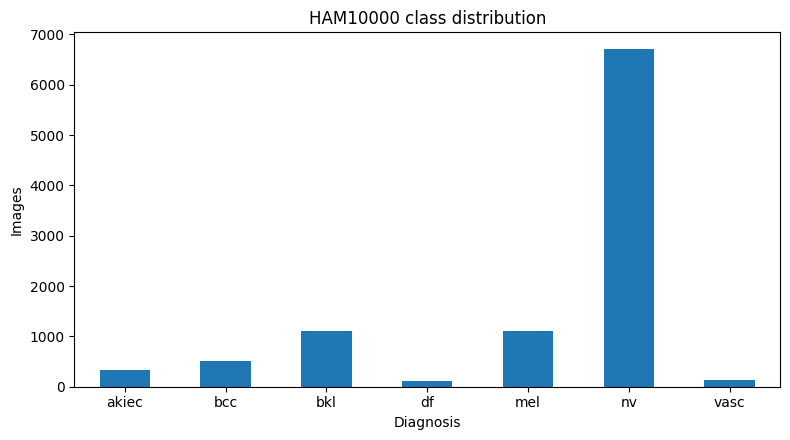

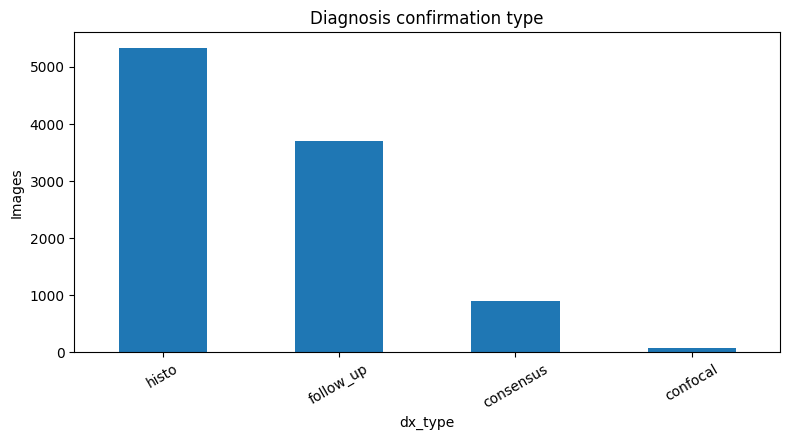

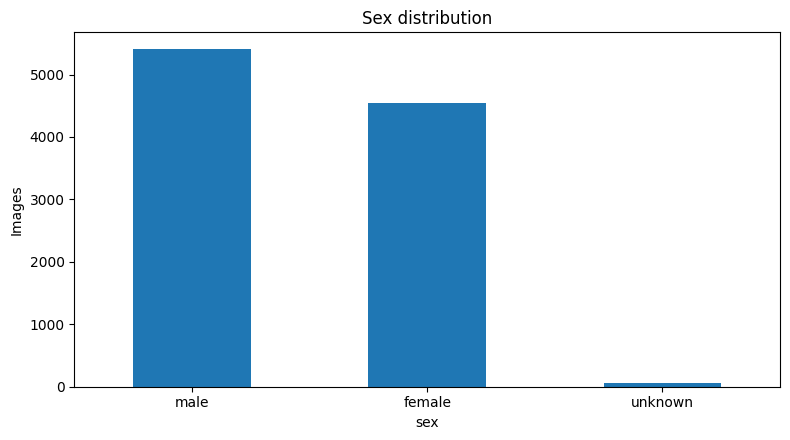

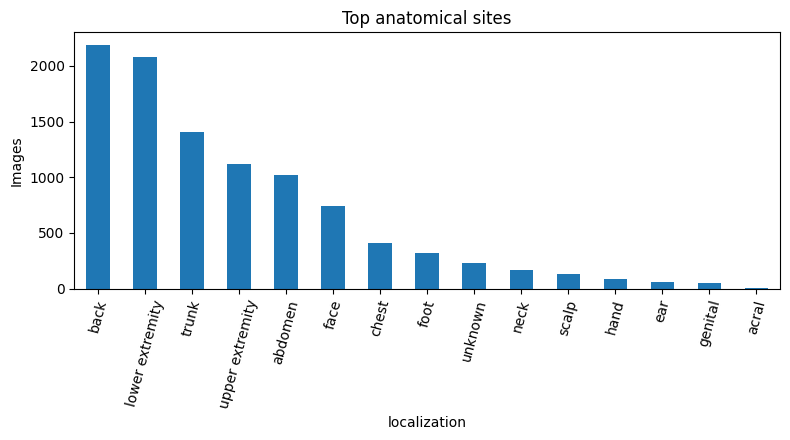

In [ ]:
# --- EDA figures ---

def save_bar(series, title, xlabel, ylabel, out_path, rotation=0):
    fig, ax = plt.subplots(figsize=(8, 4.5))
    series.plot(kind="bar", ax=ax)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.tick_params(axis='x', rotation=rotation)
    fig.tight_layout()
    fig.savefig(out_path, dpi=200)
    plt.show()

save_bar(class_counts, "HAM10000 class distribution", "Diagnosis", "Images", FIG_DIR / "class_distribution.png")
save_bar(meta["dx_type"].fillna("missing").value_counts(), "Diagnosis confirmation type", "dx_type", "Images", FIG_DIR / "dx_type_distribution.png", rotation=30)
save_bar(meta["sex"].fillna("missing").value_counts(), "Sex distribution", "sex", "Images", FIG_DIR / "sex_distribution.png")
save_bar(meta["localization"].fillna("missing").value_counts().head(20), "Top anatomical sites", "localization", "Images", FIG_DIR / "localization_distribution.png", rotation=75)

## 4. Lesion-level grouped train/validation/test split

Final results must use grouped splitting by `lesion_id`. The validation set is reserved for early stopping, model selection, and temperature scaling. The test set is held back until final evaluation.

In [ ]:
# --- Grouped stratified split with fallback ---

def stratified_group_split(df, label_col="label", group_col="lesion_id", test_size=0.2, seed=42):
    """Return train_idx, test_idx. Prefer StratifiedGroupKFold; fallback to GroupShuffleSplit."""
    y = df[label_col].values
    groups = df[group_col].values
    idx = np.arange(len(df))

    if HAS_SGK:
        # n_splits approximates requested test fraction.
        n_splits = max(2, int(round(1 / test_size)))
        sgkf = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=seed)
        # Choose the fold whose test size is closest to requested.
        best = None
        for tr, te in sgkf.split(idx, y, groups):
            frac = len(te) / len(idx)
            score = abs(frac - test_size)
            if best is None or score < best[0]:
                best = (score, tr, te)
        return best[1], best[2]
    else:
        gss = GroupShuffleSplit(n_splits=1, test_size=test_size, random_state=seed)
        tr, te = next(gss.split(idx, y, groups))
        return tr, te

# First split: train+val vs test.
trainval_idx, test_idx = stratified_group_split(
    meta, label_col="label", group_col="lesion_id", test_size=CONFIG["test_size"], seed=CONFIG["seed"]
)
trainval_df = meta.iloc[trainval_idx].copy().reset_index(drop=True)
test_df = meta.iloc[test_idx].copy().reset_index(drop=True)

# Second split: train vs validation inside trainval.
train_idx2, val_idx2 = stratified_group_split(
    trainval_df, label_col="label", group_col="lesion_id", test_size=CONFIG["val_size_of_trainval"], seed=CONFIG["seed"] + 1
)
train_df = trainval_df.iloc[train_idx2].copy().reset_index(drop=True)
val_df = trainval_df.iloc[val_idx2].copy().reset_index(drop=True)

# Verify no lesion leakage.
def assert_no_group_overlap(a, b, group_col="lesion_id", name_a="A", name_b="B"):
    overlap = set(a[group_col]).intersection(set(b[group_col]))
    if overlap:
        raise AssertionError(f"Leakage: {len(overlap)} lesion_ids overlap between {name_a} and {name_b}")
    print(f"No {group_col} overlap between {name_a} and {name_b}.")

assert_no_group_overlap(train_df, val_df, name_a="train", name_b="val")
assert_no_group_overlap(train_df, test_df, name_a="train", name_b="test")
assert_no_group_overlap(val_df, test_df, name_a="val", name_b="test")

for split_name, df in [("train", train_df), ("val", val_df), ("test", test_df)]:
    df["split"] = split_name
    df.to_csv(SPLIT_DIR / f"{split_name}.csv", index=False)
    print(split_name, df.shape, "lesions", df["lesion_id"].nunique())
    display(df["dx"].value_counts().reindex(CLASS_NAMES).to_frame("n"))

split_all = pd.concat([train_df, val_df, test_df], axis=0).reset_index(drop=True)
split_all.to_csv(SPLIT_DIR / "ham10000_lesion_level_split_all.csv", index=False)
print("Saved split files to", SPLIT_DIR)

No lesion_id overlap between train and val.
No lesion_id overlap between train and test.
No lesion_id overlap between val and test.
train (6413, 12) lesions 4780


,n
dx,
akiec,203
bcc,329
bkl,681
df,69
mel,695
nv,4342
vasc,94


val (1605, 12) lesions 1196


,n
dx,
akiec,56
bcc,100
bkl,192
df,18
mel,199
nv,1027
vasc,13


test (1997, 12) lesions 1494


,n
dx,
akiec,68
bcc,85
bkl,226
df,28
mel,219
nv,1336
vasc,35


Saved split files to /content/ham10000_trustworthy_ai/splits


split,test,train,val
dx,,,
akiec,68,203,56
bcc,85,329,100
bkl,226,681,192
df,28,69,18
mel,219,695,199
nv,1336,4342,1027
vasc,35,94,13


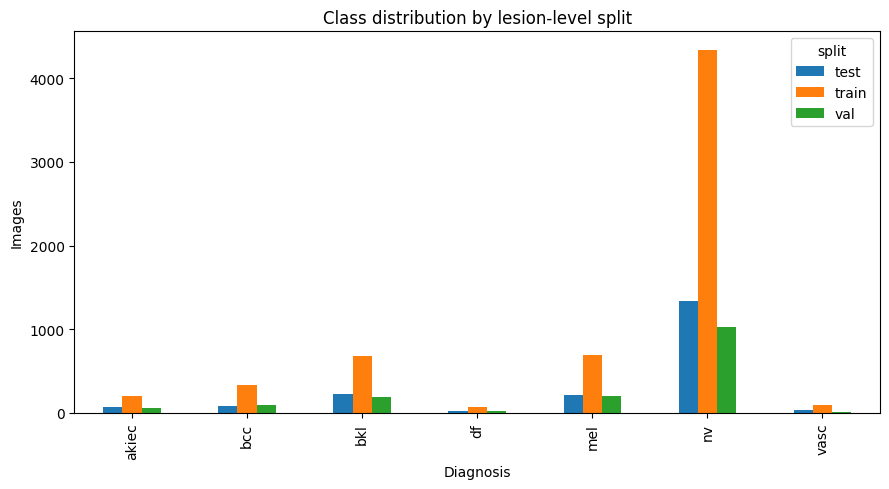

In [ ]:
# --- Split distribution figure ---

split_counts = split_all.pivot_table(index="dx", columns="split", values="image_id", aggfunc="count").reindex(CLASS_NAMES).fillna(0)
display(split_counts)
split_counts.to_csv(RESULT_DIR / "split_class_distribution.csv")

fig, ax = plt.subplots(figsize=(9, 5))
split_counts.plot(kind="bar", ax=ax)
ax.set_title("Class distribution by lesion-level split")
ax.set_xlabel("Diagnosis")
ax.set_ylabel("Images")
fig.tight_layout()
fig.savefig(FIG_DIR / "split_class_distribution.png", dpi=200)
plt.show()

## 5. Train-only metadata preprocessing

Metadata preprocessing is fitted on the training split only to avoid leakage. For the multimodal model, age is median-imputed and standardized; sex, anatomical site, and diagnosis-confirmation type are one-hot encoded with unknown categories handled safely.

In [ ]:
# --- Train-only metadata preprocessing ---
# Predictive metadata should include only variables plausibly available before diagnosis.
#
# IMPORTANT METHODOLOGICAL GUARD:
#   dx_type is the diagnostic-confirmation mechanism (e.g., histology, follow-up,
#   consensus, confocal). It is valid for subgroup/error analysis but is not a
#   deployable pre-diagnostic predictor. Including it as a model input would risk
#   post-outcome/label-confirmation leakage.
#
# Therefore:
#   - Model-input metadata: age, sex, localization
#   - Subgroup-only metadata: sex, age_bin, localization, dx_type

META_CATEGORICAL_COLS = ["sex", "localization"]
META_NUMERIC_COLS = ["age"]
SUBGROUP_VARIABLES = ["sex", "age_bin", "localization", "dx_type"]

assert "dx_type" not in META_CATEGORICAL_COLS + META_NUMERIC_COLS, (
    "dx_type must never be used as a predictive metadata input. "
    "It is reserved for subgroup analysis only."
)

class MetadataPreprocessor:
    def __init__(self, categorical_cols, numeric_cols):
        self.categorical_cols = list(categorical_cols)
        self.numeric_cols = list(numeric_cols)
        self.encoder = None
        self.scaler = None
        self.age_median = None
        self.feature_names_ = None

    def fit(self, df):
        cat = df[self.categorical_cols].fillna("missing").astype(str).replace({"nan": "missing"})
        # Compatibility with sklearn versions.
        try:
            self.encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
        except TypeError:
            self.encoder = OneHotEncoder(handle_unknown="ignore", sparse=False)
        self.encoder.fit(cat)

        num = df[self.numeric_cols].copy()
        self.age_median = float(num["age"].median())
        num["age"] = num["age"].fillna(self.age_median).astype(float)
        self.scaler = StandardScaler().fit(num.values)

        cat_names = list(self.encoder.get_feature_names_out(self.categorical_cols))
        self.feature_names_ = self.numeric_cols + cat_names
        return self

    def transform(self, df):
        cat = df[self.categorical_cols].fillna("missing").astype(str).replace({"nan": "missing"})
        cat_arr = self.encoder.transform(cat)
        num = df[self.numeric_cols].copy()
        num["age"] = num["age"].fillna(self.age_median).astype(float)
        num_arr = self.scaler.transform(num.values)
        return np.concatenate([num_arr, cat_arr], axis=1).astype("float32")

meta_pre = MetadataPreprocessor(META_CATEGORICAL_COLS, META_NUMERIC_COLS).fit(train_df)
X_meta_train = meta_pre.transform(train_df)
X_meta_val = meta_pre.transform(val_df)
X_meta_test = meta_pre.transform(test_df)
META_DIM = X_meta_train.shape[1]

joblib.dump(meta_pre, MODEL_DIR / "metadata_preprocessor_clean_inputs.joblib")

metadata_manifest = {
    "predictive_categorical_cols": META_CATEGORICAL_COLS,
    "predictive_numeric_cols": META_NUMERIC_COLS,
    "excluded_from_predictive_inputs": ["dx_type"],
    "subgroup_variables": SUBGROUP_VARIABLES,
    "reason_dx_type_excluded": (
        "dx_type encodes diagnostic-confirmation pathway and may be partly downstream "
        "of the diagnostic process; it is retained only for subgroup analysis."
    ),
    "metadata_feature_dimension": int(META_DIM),
    "metadata_feature_names": list(meta_pre.feature_names_),
}
(MODEL_DIR / "metadata_input_manifest.json").write_text(json.dumps(metadata_manifest, indent=2))

print("Metadata feature dimension:", META_DIM)
print("Predictive categorical metadata:", META_CATEGORICAL_COLS)
print("Predictive numeric metadata:", META_NUMERIC_COLS)
print("Subgroup-only variables:", SUBGROUP_VARIABLES)
print("First 10 metadata features:", meta_pre.feature_names_[:10])
print("Confirmed: dx_type is excluded from model inputs and retained only for subgroup analysis.")


Metadata feature dimension: 18
Predictive categorical metadata: ['sex', 'localization']
Predictive numeric metadata: ['age']
Subgroup-only variables: ['sex', 'age_bin', 'localization', 'dx_type']
First 10 metadata features: ['age', 'sex_female', 'sex_male', 'sex_unknown', 'localization_abdomen', 'localization_back', 'localization_chest', 'localization_ear', 'localization_face', 'localization_foot']
Confirmed: dx_type is excluded from model inputs and retained only for subgroup analysis.


## 6. TensorFlow datasets

The model receives two inputs: an image tensor and a metadata vector. For image-only models, the metadata input is present but ignored, which keeps all downstream code consistent.

In [ ]:
# --- Data pipeline: CPU-only Python/PIL sequence for images ---
# This cell intentionally does NOT use tf.data.
# Reason: earlier failures occurred during TensorFlow device-side dataset/tensor construction.
# This CPU-only version loads image batches with Python/PIL and passes NumPy arrays to Keras.
# Same downstream outputs are preserved:
#   train_ds, val_ds, test_ds = datasets_for(...)

from pathlib import Path
import numpy as np
from PIL import Image, ImageEnhance, ImageOps
import tensorflow as tf
from tensorflow import keras

IMG_SIZE = int(CONFIG["image_size"])
BATCH_SIZE = int(CONFIG["batch_size"])
N_CLASSES = len(CLASS_NAMES)


def compute_inverse_frequency_weights(df, label_col="label", n_classes=None):
    """Inverse-frequency class weights: total / (K * n_k)."""
    if n_classes is None:
        n_classes = N_CLASSES
    counts = (
        df[label_col].value_counts()
        .reindex(range(n_classes))
        .fillna(0)
        .astype(float)
        .values
    )
    total = counts.sum()
    weights = total / (n_classes * np.maximum(counts, 1.0))
    return weights.astype("float32")


def compute_effective_number_weights(df, beta=0.9999, label_col="label", n_classes=None):
    """Effective-number class-balanced weights, normalized to mean 1."""
    if n_classes is None:
        n_classes = N_CLASSES
    counts = (
        df[label_col].value_counts()
        .reindex(range(n_classes))
        .fillna(0)
        .astype(float)
        .values
    )
    counts = np.maximum(counts, 1.0)
    effective_num = 1.0 - np.power(beta, counts)
    weights = (1.0 - beta) / np.maximum(effective_num, 1e-12)
    weights = weights / np.mean(weights)
    return weights.astype("float32")


class_weights_arr = compute_inverse_frequency_weights(train_df)
class_balanced_weights_arr = compute_effective_number_weights(
    train_df,
    beta=float(CONFIG["class_balanced_beta"]),
)
class_weight_dict = {i: float(class_weights_arr[i]) for i in range(N_CLASSES)}

print(
    "Inverse-frequency class weights:",
    {CLASS_NAMES[i]: round(float(class_weights_arr[i]), 3) for i in range(N_CLASSES)},
)
print(
    "Effective-number class-balanced weights:",
    {CLASS_NAMES[i]: round(float(class_balanced_weights_arr[i]), 3) for i in range(N_CLASSES)},
)


def _pil_resize_rgb(path, image_size=IMG_SIZE):
    """Load one image as RGB float32 array in 0-255 scale."""
    with Image.open(path) as im:
        im = ImageOps.exif_transpose(im).convert("RGB")
        im = im.resize((image_size, image_size), resample=Image.BILINEAR)
        arr = np.asarray(im, dtype="float32")
    return arr


def _augment_numpy_dermoscopy(arr, rng):
    """Conservative lesion-preserving augmentation in NumPy/PIL.

    This avoids tf.image entirely at the dataset stage, removing the earlier TensorFlow-device failure path while retaining defendable dermoscopy augmentation.
    """
    im = Image.fromarray(np.clip(arr, 0, 255).astype("uint8"), mode="RGB")

    if rng.random() < 0.5:
        im = ImageOps.mirror(im)
    if rng.random() < 0.5:
        im = ImageOps.flip(im)

    # Mild brightness and contrast perturbations.
    brightness = rng.uniform(0.90, 1.10)
    contrast = rng.uniform(0.90, 1.10)
    im = ImageEnhance.Brightness(im).enhance(brightness)
    im = ImageEnhance.Contrast(im).enhance(contrast)

    # Mild central zoom/crop.
    crop_fraction = rng.uniform(0.90, 1.00)
    w, h = im.size
    cw, ch = int(w * crop_fraction), int(h * crop_fraction)
    left = (w - cw) // 2
    top = (h - ch) // 2
    im = im.crop((left, top, left + cw, top + ch)).resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR)

    return np.asarray(im, dtype="float32")


def load_image_numpy(path, training=False, seed=None):
    """Public helper used by Sequence, stress tests and Grad-CAM."""
    path = str(path)
    arr = _pil_resize_rgb(path, IMG_SIZE)
    if training:
        rng = np.random.default_rng(seed)
        arr = _augment_numpy_dermoscopy(arr, rng)
    return arr.astype("float32")


class HAM10000Sequence(keras.utils.Sequence):
    """Keras-compatible image loader that avoids tf.data completely.

    Keras receives NumPy batches and performs forward/backward passes on CPU in this notebook.
    The returned input signature matches the model:
      image-only: {"image": images}
      multimodal: {"image": images, "metadata": meta}
    """
    def __init__(
        self,
        df,
        X_meta,
        batch_size=16,
        training=False,
        shuffle=False,
        use_metadata=False,
        include_sample_weight=False,
        sample_weight_mode="inverse_frequency",
        seed=42,
    ):
        try:
            super().__init__()
        except TypeError:
            super().__init__(**{})
        self.df = df.reset_index(drop=True).copy()
        self.paths = self.df["image_path"].astype(str).to_numpy()
        self.labels = self.df["label"].astype("int32").to_numpy()
        self.X_meta = np.asarray(X_meta, dtype="float32")
        self.batch_size = int(batch_size)
        self.training = bool(training)
        self.shuffle = bool(shuffle)
        self.use_metadata = bool(use_metadata)
        self.include_sample_weight = bool(include_sample_weight)
        self.sample_weight_mode = sample_weight_mode
        self.seed = int(seed)
        self.epoch = 0
        self.indexes = np.arange(len(self.paths))

        if len(self.paths) != len(self.labels) or len(self.paths) != len(self.X_meta):
            raise ValueError(
                f"Length mismatch: paths={len(self.paths)}, labels={len(self.labels)}, metadata={len(self.X_meta)}"
            )

        missing = [p for p in self.paths[: min(len(self.paths), 3000)] if not Path(p).exists()]
        if missing:
            raise FileNotFoundError("Missing image files, examples:\n" + "\n".join(missing[:5]))

        if self.include_sample_weight:
            if self.sample_weight_mode == "inverse_frequency":
                self.sample_weights = class_weights_arr[self.labels].astype("float32")
            elif self.sample_weight_mode == "class_balanced":
                self.sample_weights = class_balanced_weights_arr[self.labels].astype("float32")
            else:
                raise ValueError(f"Unknown sample_weight_mode: {self.sample_weight_mode}")
        else:
            self.sample_weights = None

        self.on_epoch_end()

    def __len__(self):
        return int(np.ceil(len(self.paths) / self.batch_size))

    def on_epoch_end(self):
        if self.shuffle:
            rng = np.random.default_rng(self.seed + self.epoch)
            rng.shuffle(self.indexes)
        self.epoch += 1

    def __getitem__(self, batch_idx):
        start = batch_idx * self.batch_size
        end = min((batch_idx + 1) * self.batch_size, len(self.paths))
        batch_indexes = self.indexes[start:end]

        images = np.empty((len(batch_indexes), IMG_SIZE, IMG_SIZE, 3), dtype="float32")
        for j, idx in enumerate(batch_indexes):
            # deterministic per-image/per-epoch augmentation seed
            aug_seed = self.seed + self.epoch * 1_000_003 + int(idx)
            images[j] = load_image_numpy(self.paths[idx], training=self.training, seed=aug_seed)

        y = self.labels[batch_indexes].astype("int32")
        if self.use_metadata:
            x = {
                "image": images,
                "metadata": self.X_meta[batch_indexes].astype("float32"),
            }
        else:
            x = {"image": images}

        if self.include_sample_weight:
            sw = self.sample_weights[batch_indexes].astype("float32")
            return x, y, sw
        return x, y

    def __iter__(self):
        for i in range(len(self)):
            yield self[i]


def make_tf_dataset(
    df,
    X_meta,
    training=False,
    include_sample_weight=False,
    shuffle=True,
    use_metadata=False,
):
    """Compatibility wrapper: name kept, but backend is Keras Sequence rather than tf.data."""
    return HAM10000Sequence(
        df=df,
        X_meta=X_meta,
        batch_size=BATCH_SIZE,
        training=training,
        shuffle=(training and shuffle),
        use_metadata=use_metadata,
        include_sample_weight=include_sample_weight,
        seed=int(CONFIG["seed"]),
    )


def datasets_for(use_metadata=False, loss_type=None):
    """Return train/validation/test datasets compatible with a given model and loss."""
    if loss_type is None:
        loss_type = CONFIG["loss_type"]

    include_train_weights = loss_type == "weighted_ce"

    train_dataset = make_tf_dataset(
        train_df,
        X_meta_train,
        training=True,
        include_sample_weight=include_train_weights,
        shuffle=True,
        use_metadata=use_metadata,
    )
    val_dataset = make_tf_dataset(
        val_df,
        X_meta_val,
        training=False,
        include_sample_weight=False,
        shuffle=False,
        use_metadata=use_metadata,
    )
    test_dataset = make_tf_dataset(
        test_df,
        X_meta_test,
        training=False,
        include_sample_weight=False,
        shuffle=False,
        use_metadata=use_metadata,
    )
    return train_dataset, val_dataset, test_dataset


# Construct default datasets.
train_ds, val_ds, test_ds = datasets_for(
    use_metadata=bool(CONFIG["use_metadata"]),
    loss_type=CONFIG["loss_type"],
)

print("CPU-only Keras Sequence datasets constructed; tf.data is not used.")
print("use_metadata:", CONFIG["use_metadata"])
print("loss_type:", CONFIG["loss_type"])
print("batch_size:", BATCH_SIZE)
print("image_size:", IMG_SIZE)
print("backend:", CONFIG.get("data_pipeline_backend", "keras_sequence_cpu"))
print("compute mode: CPU-only")
print("GPUs visible to TensorFlow:", tf.config.list_logical_devices("GPU"))

if bool(CONFIG.get("preview_tfdata_batch", False)):
    preview_batch = train_ds[0]
    print("Batch preview successful.")
    if len(preview_batch) == 3:
        x_preview, y_preview, sw_preview = preview_batch
        print("Batch includes sample weights:", sw_preview.shape)
    else:
        x_preview, y_preview = preview_batch
        print("Batch does not include sample weights.")
    print("Input keys:", list(x_preview.keys()))
    print("Image batch shape:", x_preview["image"].shape)
    if "metadata" in x_preview:
        print("Metadata batch shape:", x_preview["metadata"].shape)
    print("Label batch shape:", y_preview.shape)
else:
    print("Batch preview skipped. The first batch will be loaded at fit/evaluation time.")


Inverse-frequency class weights: {'akiec': 4.513, 'bcc': 2.785, 'bkl': 1.345, 'df': 13.277, 'mel': 1.318, 'nv': 0.211, 'vasc': 9.746}
Effective-number class-balanced weights: {'akiec': 0.952, 'bcc': 0.591, 'bkl': 0.291, 'df': 2.782, 'mel': 0.285, 'nv': 0.054, 'vasc': 2.045}
CPU-only Keras Sequence datasets constructed; tf.data is not used.
use_metadata: False
loss_type: weighted_ce
batch_size: 8
image_size: 224
backend: keras_sequence_cpu
compute mode: CPU-only
GPUs visible to TensorFlow: []
Batch preview skipped. The first batch will be loaded at fit/evaluation time.


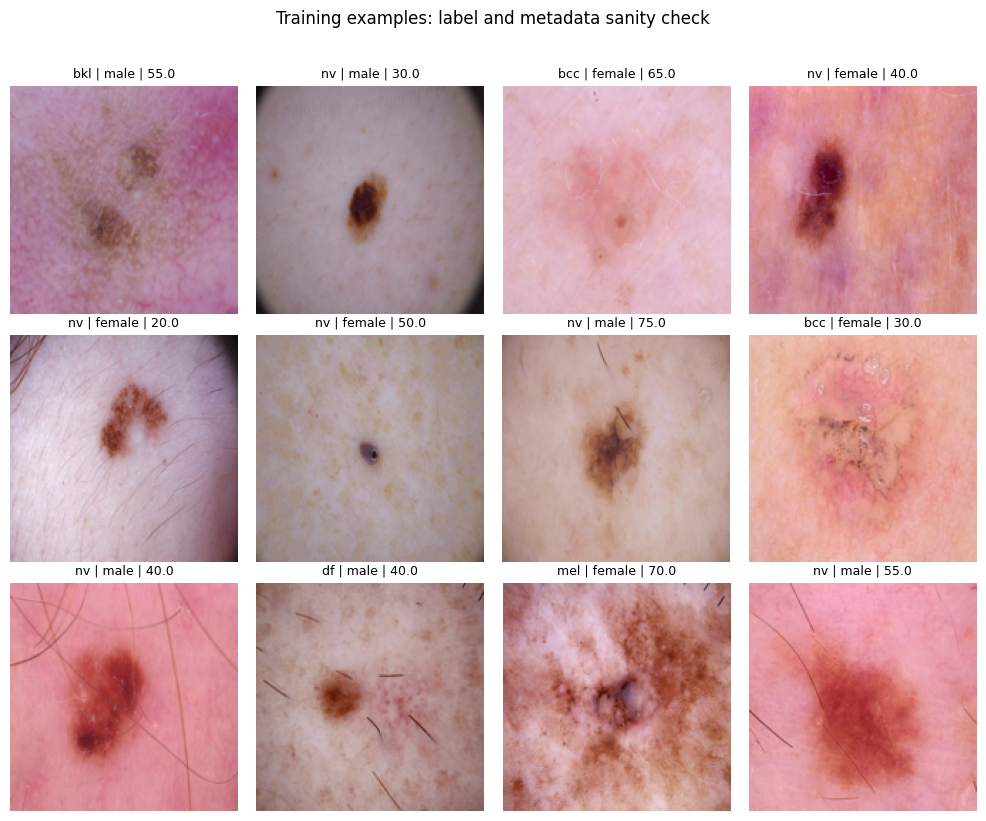

In [ ]:
# --- Visual sanity check: samples from the training split ---

sample_df = train_df.sample(min(12, len(train_df)), random_state=CONFIG["seed"])
fig, axes = plt.subplots(3, 4, figsize=(10, 8))
for ax, (_, row) in zip(axes.flat, sample_df.iterrows()):
    img = Image.open(row["image_path"]).convert("RGB").resize((160, 160))
    ax.imshow(img)
    ax.set_title(f"{row['dx']} | {row['sex']} | {row['age']}", fontsize=9)
    ax.axis("off")
fig.suptitle("Training examples: label and metadata sanity check", y=1.02)
fig.tight_layout()
fig.savefig(FIG_DIR / "training_examples_grid.png", dpi=200)
plt.show()

## 7. Model builders: image-only and late-fusion multimodal networks

The recommended first publishable route is: EfficientNetB0 image-only baseline → temperature scaling and selective referral → metadata late-fusion ablation → optional MC Dropout/ensemble for the best model.

In [ ]:
# --- Losses and model builders: CPU-only publishable version ---
# This cell defines losses and model constructors only.
# Model construction is CPU-only by design, avoiding all CUDA/CuDNN paths.

import contextlib


def _maybe_cpu_scope(enabled=True):
    """Context manager for CPU-only graph/model construction when requested."""
    if enabled:
        return tf.device("/CPU:0")
    return contextlib.nullcontext()


def class_weighted_sparse_ce(class_weights):
    # Keep the constant on CPU at creation time; it will be copied as needed during fit.
    with tf.device("/CPU:0"):
        weights_tf = tf.constant(np.asarray(class_weights, dtype="float32"), dtype=tf.float32)

    def loss_fn(y_true, logits):
        y_true_int = tf.cast(tf.reshape(y_true, [-1]), tf.int32)
        ce = tf.keras.losses.sparse_categorical_crossentropy(y_true_int, logits, from_logits=True)
        w = tf.gather(weights_tf, y_true_int)
        return ce * w

    return loss_fn


def sparse_categorical_focal_loss(gamma=2.0, class_weights=None):
    if class_weights is None:
        cw = None
    else:
        with tf.device("/CPU:0"):
            cw = tf.constant(np.asarray(class_weights, dtype="float32"), dtype=tf.float32)

    def loss_fn(y_true, logits):
        y_true_int = tf.cast(tf.reshape(y_true, [-1]), tf.int32)
        ce = tf.keras.losses.sparse_categorical_crossentropy(y_true_int, logits, from_logits=True)
        probs = tf.nn.softmax(logits, axis=-1)
        p_t = tf.gather(probs, y_true_int[:, None], batch_dims=1)
        p_t = tf.squeeze(p_t, axis=1)
        focal = tf.pow(1.0 - p_t, gamma) * ce
        if cw is not None:
            focal *= tf.gather(cw, y_true_int)
        return focal

    return loss_fn


@keras.utils.register_keras_serializable(package="TrustworthySkinAI")
class ResNet50Preprocess(layers.Layer):
    def call(self, inputs):
        return tf.keras.applications.resnet50.preprocess_input(inputs)


@keras.utils.register_keras_serializable(package="TrustworthySkinAI")
class MobileNetV2Preprocess(layers.Layer):
    def call(self, inputs):
        return tf.keras.applications.mobilenet_v2.preprocess_input(inputs)


@keras.utils.register_keras_serializable(package="TrustworthySkinAI")
class DenseNetPreprocess(layers.Layer):
    def call(self, inputs):
        return tf.keras.applications.densenet.preprocess_input(inputs)


@keras.utils.register_keras_serializable(package="TrustworthySkinAI")
class EfficientNetIdentityPreprocess(layers.Layer):
    def call(self, inputs):
        # Keras EfficientNet preprocessing is already included in the application model.
        # Keeping this explicit identity layer documents the intended 0-255 input scale.
        return tf.cast(inputs, tf.float32)


def get_backbone(name, input_tensor):
    """Return an ImageNet-pretrained backbone with a stable preprocessing path.

    Input images are float32 in 0-255 RGB scale. EfficientNet models in Keras include
    their own rescaling/normalization preprocessing; ResNet/MobileNet/DenseNet use
    their standard preprocessing layers.
    """
    name_l = name.lower()

    if name_l == "efficientnetb0":
        x = EfficientNetIdentityPreprocess(name="efficientnet_input_scale_documented")(input_tensor)
        backbone = tf.keras.applications.EfficientNetB0(
            include_top=False, weights="imagenet", input_tensor=x, pooling="avg"
        )
    elif name_l == "resnet50":
        x = ResNet50Preprocess(name="resnet_preprocess")(input_tensor)
        backbone = tf.keras.applications.ResNet50(
            include_top=False, weights="imagenet", input_tensor=x, pooling="avg"
        )
    elif name_l == "mobilenetv2":
        x = MobileNetV2Preprocess(name="mobilenet_preprocess")(input_tensor)
        backbone = tf.keras.applications.MobileNetV2(
            include_top=False, weights="imagenet", input_tensor=x, pooling="avg"
        )
    elif name_l == "densenet121":
        x = DenseNetPreprocess(name="densenet_preprocess")(input_tensor)
        backbone = tf.keras.applications.DenseNet121(
            include_top=False, weights="imagenet", input_tensor=x, pooling="avg"
        )
    else:
        raise ValueError(f"Unsupported backbone: {name}")

    return backbone


def build_model(backbone_name="EfficientNetB0", use_metadata=False, meta_dim=None, dropout_rate=0.3, train_backbone=False):
    """Build the image-only or late-fusion multimodal classifier.

    Graph construction happens under a CPU device scope. This notebook is CPU-only.
    """
    if meta_dim is None:
        meta_dim = META_DIM

    build_on_cpu = bool(CONFIG.get("build_model_on_cpu", True))

    with _maybe_cpu_scope(build_on_cpu):
        image_in = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3), name="image")
        backbone = get_backbone(backbone_name, image_in)
        backbone.trainable = bool(train_backbone)

        img_emb = backbone.output
        img_emb = layers.Dropout(dropout_rate, name="image_dropout")(img_emb)

        if use_metadata:
            meta_in = keras.Input(shape=(meta_dim,), name="metadata")
            m = layers.Dense(64, activation="relu", name="metadata_dense_1")(meta_in)
            m = layers.BatchNormalization(name="metadata_bn_1")(m)
            m = layers.Dropout(dropout_rate, name="metadata_dropout")(m)
            m = layers.Dense(32, activation="relu", name="metadata_dense_2")(m)
            x = layers.Concatenate(name="late_fusion_concat")([img_emb, m])
            inputs = {"image": image_in, "metadata": meta_in}
        else:
            x = img_emb
            inputs = {"image": image_in}

        x = layers.Dense(256, activation="relu", name="classifier_dense")(x)
        x = layers.BatchNormalization(name="classifier_bn")(x)
        x = layers.Dropout(dropout_rate, name="classifier_dropout")(x)
        logits = layers.Dense(N_CLASSES, dtype="float32", name="logits")(x)

        model = keras.Model(
            inputs=inputs,
            outputs=logits,
            name=f"{backbone_name}_{'multimodal' if use_metadata else 'image_only'}",
        )

    return model


def compile_model(model, lr, loss_type="weighted_ce"):
    """Compile model using the requested long-tail strategy."""
    compile_on_cpu = bool(CONFIG.get("compile_model_on_cpu", True))

    with _maybe_cpu_scope(compile_on_cpu):
        opt = keras.optimizers.Adam(learning_rate=lr)

        if loss_type == "focal":
            loss = sparse_categorical_focal_loss(gamma=CONFIG["focal_gamma"], class_weights=class_weights_arr)
        elif loss_type == "class_balanced_ce":
            loss = class_weighted_sparse_ce(class_balanced_weights_arr)
        elif loss_type == "weighted_ce":
            # For weighted CE, sample weights are supplied by the Sequence.
            loss = keras.losses.SparseCategoricalCrossentropy(from_logits=True)
        else:
            raise ValueError(f"Unsupported loss_type: {loss_type}")

        model.compile(
            optimizer=opt,
            loss=loss,
            metrics=[keras.metrics.SparseCategoricalAccuracy(name="accuracy")],
        )

    return model


# Optional preview. Disabled by default because the training utility will build the real model.
if bool(CONFIG.get("run_model_build_preview", False)):
    runtime_guard("before optional model build preview")
    preview_model = build_model(CONFIG["backbone"], use_metadata=CONFIG["use_metadata"], meta_dim=META_DIM)
    compile_model(preview_model, CONFIG["head_learning_rate"], CONFIG["loss_type"])
    preview_model.summary()
else:
    print("Model-builder cell loaded. Preview build skipped for speed/stability.")
    print("Backbone:", CONFIG["backbone"], "| use_metadata:", CONFIG["use_metadata"], "| N_CLASSES:", N_CLASSES)


Model-builder cell loaded. Preview build skipped for speed/stability.
Backbone: EfficientNetB0 | use_metadata: False | N_CLASSES: 7


## 8. Training protocol: frozen head training then careful fine-tuning

This is a two-stage transfer-learning protocol. First train only the classification head to stabilise the task-specific layer. Then unfreeze the last part of the backbone with a much smaller learning rate.

In [ ]:
# --- Training utilities: CPU-only full-run version ---

def model_uses_metadata(model):
    names = []
    for inp in model.inputs:
        try:
            names.append(inp.name.split(":")[0].split("/")[-1])
        except Exception:
            pass
    return "metadata" in names


def unfreeze_last_n_layers(model, n_last=40):
    """Unfreeze the last n layers of the nested application backbone, keeping BatchNorm frozen."""
    for layer in model.layers:
        layer.trainable = False

    backbone = None
    for layer in model.layers:
        if isinstance(layer, keras.Model) and layer.name.lower().startswith(("efficientnet", "resnet", "mobilenet", "densenet")):
            backbone = layer
            break

    if backbone is None:
        backbone = model

    trainable_count = 0
    for layer in backbone.layers[-int(n_last):]:
        if not isinstance(layer, layers.BatchNormalization):
            layer.trainable = True
            trainable_count += 1

    for layer in model.layers:
        if layer.name.startswith(("classifier", "logits", "metadata", "late_fusion")) and not isinstance(layer, layers.BatchNormalization):
            layer.trainable = True

    print("Unfroze backbone layers:", trainable_count)
    return model


def safe_load_model(path):
    """Load a Keras model without requiring custom loss serialization."""
    custom_objects = {
        "ResNet50Preprocess": ResNet50Preprocess,
        "MobileNetV2Preprocess": MobileNetV2Preprocess,
        "DenseNetPreprocess": DenseNetPreprocess,
        "EfficientNetIdentityPreprocess": EfficientNetIdentityPreprocess,
    }
    with tf.device("/CPU:0"):
        return tf.keras.models.load_model(path, compile=False, custom_objects=custom_objects)


def _fit_with_runtime_guard(model, train_data, val_data, epochs, callbacks, stage_name):
    """Fit on CPU with a clear failure message.

    CUDA is disabled at setup, so this function avoids all GPU-specific guards.
    """
    runtime_guard(f"before {stage_name}")
    try:
        with tf.device("/CPU:0"):
            return model.fit(
                train_data,
                validation_data=val_data,
                epochs=int(epochs),
                callbacks=callbacks,
                verbose=1,
            )
    except Exception as e:
        raise RuntimeError(
            f"TensorFlow/Keras failed during {stage_name}. This CPU-only notebook avoids CUDA; "
            "check the preceding traceback for data-path, memory, or model-construction errors."
        ) from e


def train_one_model(backbone_name, use_metadata, seed, loss_type="weighted_ce", run_tag=None):
    set_all_seeds(seed, deterministic=False)
    tf.keras.backend.clear_session()
    gc.collect()

    if run_tag is None:
        run_tag = f"{backbone_name}_{'meta' if use_metadata else 'image'}_seed{seed}_{loss_type}"
    out_dir = MODEL_DIR / run_tag
    out_dir.mkdir(parents=True, exist_ok=True)
    final_path = out_dir / "final_model.keras"

    if final_path.exists() and not CONFIG["force_retrain"]:
        print(f"Existing trained model found; reusing: {final_path}")
        model = safe_load_model(final_path)
        runtime_path = out_dir / "runtime.json"
        runtime = json.load(open(runtime_path)) if runtime_path.exists() else {
            "run_tag": run_tag,
            "backbone": backbone_name,
            "use_metadata": use_metadata,
            "seed": seed,
            "loss_type": loss_type,
            "reused_existing": True,
            "timestamp": datetime.now().isoformat(),
        }
        return model, out_dir, runtime

    train_ds_local, val_ds_local, _ = datasets_for(use_metadata=use_metadata, loss_type=loss_type)

    print(f"Building model safely | {run_tag}")
    model = build_model(
        backbone_name,
        use_metadata=use_metadata,
        meta_dim=META_DIM,
        dropout_rate=CONFIG["dropout_rate"],
        train_backbone=False,
    )
    compile_model(model, CONFIG["head_learning_rate"], loss_type)

    # Save a text summary for reproducibility without forcing interactive rendering.
    summary_lines = []
    model.summary(print_fn=lambda x: summary_lines.append(x))
    (out_dir / "model_summary.txt").write_text("\n".join(summary_lines))

    callbacks_head = [
        keras.callbacks.ModelCheckpoint(out_dir / "best_head.weights.h5", monitor="val_loss", save_best_only=True, save_weights_only=True),
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=CONFIG["early_stopping_patience"], restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.3, patience=2, min_lr=1e-6),
        keras.callbacks.CSVLogger(out_dir / "history_head.csv"),
    ]

    print(f"Stage 1: frozen backbone head training | {run_tag}")
    t0 = time.time()
    hist1 = _fit_with_runtime_guard(
        model,
        train_ds_local,
        val_ds_local,
        epochs=CONFIG["head_epochs"],
        callbacks=callbacks_head,
        stage_name=f"head training: {run_tag}",
    )
    head_seconds = time.time() - t0

    print(f"Stage 2: fine-tuning | {run_tag}")
    model = unfreeze_last_n_layers(model, CONFIG["finetune_last_n_layers"])
    compile_model(model, CONFIG["finetune_learning_rate"], loss_type)

    callbacks_ft = [
        keras.callbacks.ModelCheckpoint(out_dir / "best_finetuned.weights.h5", monitor="val_loss", save_best_only=True, save_weights_only=True),
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=CONFIG["early_stopping_patience"], restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.3, patience=2, min_lr=1e-7),
        keras.callbacks.CSVLogger(out_dir / "history_finetune.csv"),
    ]

    t1 = time.time()
    hist2 = _fit_with_runtime_guard(
        model,
        train_ds_local,
        val_ds_local,
        epochs=CONFIG["finetune_epochs"],
        callbacks=callbacks_ft,
        stage_name=f"fine-tuning: {run_tag}",
    )
    ft_seconds = time.time() - t1

    # Save without optimizer to avoid serializing custom losses/optimizer state.
    with tf.device("/CPU:0"):
        model.save(final_path, include_optimizer=False)

    runtime = {
        "run_tag": run_tag,
        "backbone": backbone_name,
        "use_metadata": use_metadata,
        "seed": seed,
        "loss_type": loss_type,
        "head_seconds": head_seconds,
        "finetune_seconds": ft_seconds,
        "total_seconds": head_seconds + ft_seconds,
        "batch_size": BATCH_SIZE,
        "image_size": IMG_SIZE,
        "build_model_on_cpu": bool(CONFIG.get("build_model_on_cpu", True)),
        "compile_model_on_cpu": bool(CONFIG.get("compile_model_on_cpu", True)),
        "compute_mode": "CPU-only",
        "gpu_name": None,
        "timestamp": datetime.now().isoformat(),
        "reused_existing": False,
    }
    with open(out_dir / "runtime.json", "w") as f:
        json.dump(runtime, f, indent=2)

    return model, out_dir, runtime

print("Training utility ready. Model build/compile/training are CPU-only.")


Training utility ready. Model build/compile/training are CPU-only.


In [ ]:
# --- Main baseline training cell ---
# This trains the first image-only baseline configured in CONFIG.

RUN_TRAINING = CONFIG["run_training"]

baseline_model = None
baseline_dir = None
baseline_runtime = None

if RUN_TRAINING:
    baseline_model, baseline_dir, baseline_runtime = train_one_model(
        CONFIG["backbone"],
        use_metadata=CONFIG["use_metadata"],
        seed=CONFIG["seed"],
        loss_type=CONFIG["loss_type"]
    )
    print("Baseline model directory:", baseline_dir)
    print("Baseline runtime:", baseline_runtime)
else:
    print("Training skipped. Set CONFIG['run_training']=True when ready.")

Building model safely | EfficientNetB0_image_seed42_weighted_ce
16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Stage 1: frozen backbone head training | EfficientNetB0_image_seed42_weighted_ce
[before head training: EfficientNetB0_image_seed42_weighted_ce] CPU TensorFlow sanity check passed; checksum=519435.688
Epoch 1/8
802/802 ━━━━━━━━━━━━━━━━━━━━ 245s 286ms/step - accuracy: 0.3647 - loss: 1.7951 - val_accuracy: 0.5196 - val_loss: 1.3374 - learning_rate: 0.0010
Epoch 2/8
802/802 ━━━━━━━━━━━━━━━━━━━━ 220s 273ms/step - accuracy: 0.4756 - loss: 1.3762 - val_accuracy: 0.5483 - val_loss: 1.2578 - learning_rate: 0.0010
Epoch 3/8
802/802 ━━━━━━━━━━━━━━━━━━━━ 260s 324ms/step - accuracy: 0.5002 - loss: 1.3217 - val_accuracy: 0.5981 - val_loss: 1.0581 - learning_rate: 0.0010
Epoch 4/8
802/802 ━━━━━━━━━━━━━━━━━━━━ 192s 239ms/step - accuracy: 0.5066 - loss: 1.2783 - val_accuracy: 0.5657 - val_loss: 1.1951 - learning_rate: 0.0010
Epoch 5/8
802/802 ━━━━━━━━━━━━━━━━━━━━ 190s 237ms/step - accuracy: 0.5314 - loss: 1.1877 - val_accuracy: 0.6056 - val_loss: 1.0794 - learning_rate: 0.0010
Epoch 6/8
802/802 ━━━━━━

In [ ]:
# --- Model comparison funnel, long-tail loss ablation, and repeated-seed final run ---
# These runs are enabled for publication-grade evidence. Existing models are reused unless CONFIG["force_retrain"]=True.

funnel_rows = []

# 1) Backbone funnel: compare model families under the same split and weighted CE.
if CONFIG["run_model_funnel"]:
    for bb in CONFIG["funnel_backbones"]:
        tf.keras.backend.clear_session(); gc.collect()
        model_i, out_dir_i, runtime_i = train_one_model(
            bb, use_metadata=False, seed=CONFIG["seed"], loss_type="weighted_ce",
            run_tag=f"{bb}_image_seed{CONFIG['seed']}_weighted_ce"
        )
        funnel_rows.append(runtime_i)
        pd.DataFrame(funnel_rows).to_csv(RESULT_DIR / "model_funnel_runtime.csv", index=False)
else:
    print("Model funnel skipped.")

# 2) Long-tail loss ablation on the configured main backbone.
loss_rows = []
if CONFIG["run_long_tail_ablation"]:
    for loss_type in CONFIG["long_tail_losses"]:
        tf.keras.backend.clear_session(); gc.collect()
        model_l, out_dir_l, runtime_l = train_one_model(
            CONFIG["backbone"], use_metadata=False, seed=CONFIG["seed"], loss_type=loss_type,
            run_tag=f"{CONFIG['backbone']}_image_seed{CONFIG['seed']}_{loss_type}"
        )
        loss_rows.append(runtime_l)
        pd.DataFrame(loss_rows).to_csv(RESULT_DIR / "long_tail_loss_ablation_runtime.csv", index=False)
else:
    print("Long-tail loss ablation skipped.")

# 3) Repeated seeds for the primary model specification.
seed_rows = []
if CONFIG["run_final_three_seeds"]:
    for seed in CONFIG["final_seeds"]:
        tf.keras.backend.clear_session(); gc.collect()
        model_s, out_dir_s, runtime_s = train_one_model(
            CONFIG["backbone"], use_metadata=CONFIG["use_metadata"], seed=seed, loss_type=CONFIG["loss_type"],
            run_tag=f"{CONFIG['backbone']}_{'meta' if CONFIG['use_metadata'] else 'image'}_seed{seed}_{CONFIG['loss_type']}"
        )
        seed_rows.append(runtime_s)
        pd.DataFrame(seed_rows).to_csv(RESULT_DIR / "final_repeated_seed_runtime.csv", index=False)
else:
    print("Repeated-seed final run skipped.")

# Keep the primary baseline in memory for immediate downstream evaluation.
if baseline_model is None:
    primary_path = MODEL_DIR / f"{CONFIG['backbone']}_{'meta' if CONFIG['use_metadata'] else 'image'}_seed{CONFIG['seed']}_{CONFIG['loss_type']}" / "final_model.keras"
    if primary_path.exists():
        baseline_model = safe_load_model(primary_path)
        baseline_dir = primary_path.parent
        print("Loaded primary baseline after funnel:", primary_path)

Building model safely | EfficientNetB0_image_seed42_weighted_ce


Stage 1: frozen backbone head training | EfficientNetB0_image_seed42_weighted_ce
[before head training: EfficientNetB0_image_seed42_weighted_ce] CPU TensorFlow sanity check passed; checksum=519435.688
Epoch 1/8
802/802 ━━━━━━━━━━━━━━━━━━━━ 201s 236ms/step - accuracy: 0.3647 - loss: 1.7951 - val_accuracy: 0.5196 - val_loss: 1.3374 - learning_rate: 0.0010
Epoch 2/8
802/802 ━━━━━━━━━━━━━━━━━━━━ 222s 276ms/step - accuracy: 0.4756 - loss: 1.3762 - val_accuracy: 0.5483 - val_loss: 1.2578 - learning_rate: 0.0010
Epoch 3/8
802/802 ━━━━━━━━━━━━━━━━━━━━ 197s 245ms/step - accuracy: 0.5002 - loss: 1.3217 - val_accuracy: 0.5981 - val_loss: 1.0581 - learning_rate: 0.0010
Epoch 4/8
802/802 ━━━━━━━━━━━━━━━━━━━━ 192s 240ms/step - accuracy: 0.5066 - loss: 1.2783 - val_accuracy: 0.5657 - val_loss: 1.1951 - learning_rate: 0.0010
Epoch 5/8
802/802 ━━━━━━━━━━━━━━━━━━━━ 236s 294ms/step - accuracy: 0.5314 - loss: 1.1877 - val_accuracy: 0.6056 - val_loss: 1.0794 - learning_rate: 0.0010
Epoch 6/8
802/802 ━━━━━━

Stage 1: frozen backbone head training | MobileNetV2_image_seed42_weighted_ce
[before head training: MobileNetV2_image_seed42_weighted_ce] CPU TensorFlow sanity check passed; checksum=519435.688
Epoch 1/8
802/802 ━━━━━━━━━━━━━━━━━━━━ 147s 175ms/step - accuracy: 0.3825 - loss: 1.7510 - val_accuracy: 0.5396 - val_loss: 1.2694 - learning_rate: 0.0010
Epoch 2/8
802/802 ━━━━━━━━━━━━━━━━━━━━ 139s 173ms/step - accuracy: 0.5007 - loss: 1.3503 - val_accuracy: 0.5526 - val_loss: 1.2362 - learning_rate: 0.0010
Epoch 3/8
802/802 ━━━━━━━━━━━━━━━━━━━━ 138s 171ms/step - accuracy: 0.5392 - loss: 1.2230 - val_accuracy: 0.5495 - val_loss: 1.2116 - learning_rate: 0.0010
Epoch 4/8
802/802 ━━━━━━━━━━━━━━━━━━━━ 142s 177ms/step - accuracy: 0.5470 - loss: 1.1673 - val_accuracy: 0.5975 - val_loss: 1.0696 - learning_rate: 0.0010
Epoch 5/8
802/802 ━━━━━━━━━━━━━━━━━━━━ 137s 171ms/step - accuracy: 0.5442 - loss: 1.1425 - val_accuracy: 0.6150 - val_loss: 1.0810 - learning_rate: 0.0010
Epoch 6/8
802/802 ━━━━━━━━━━━━

Stage 1: frozen backbone head training | ResNet50_image_seed42_weighted_ce
[before head training: ResNet50_image_seed42_weighted_ce] CPU TensorFlow sanity check passed; checksum=519435.688
Epoch 1/8
802/802 ━━━━━━━━━━━━━━━━━━━━ 398s 486ms/step - accuracy: 0.3898 - loss: 1.6795 - val_accuracy: 0.5458 - val_loss: 1.2405 - learning_rate: 0.0010
Epoch 2/8
802/802 ━━━━━━━━━━━━━━━━━━━━ 391s 487ms/step - accuracy: 0.5353 - loss: 1.3034 - val_accuracy: 0.5695 - val_loss: 1.1654 - learning_rate: 0.0010
Epoch 3/8
802/802 ━━━━━━━━━━━━━━━━━━━━ 388s 484ms/step - accuracy: 0.5727 - loss: 1.1385 - val_accuracy: 0.6791 - val_loss: 0.8608 - learning_rate: 0.0010
Epoch 4/8
802/802 ━━━━━━━━━━━━━━━━━━━━ 389s 484ms/step - accuracy: 0.5863 - loss: 1.0899 - val_accuracy: 0.5626 - val_loss: 1.2130 - learning_rate: 0.0010
Epoch 5/8
802/802 ━━━━━━━━━━━━━━━━━━━━ 385s 479ms/step - accuracy: 0.5876 - loss: 1.0717 - val_accuracy: 0.6355 - val_loss: 0.9505 - learning_rate: 0.0010
Epoch 6/8
802/802 ━━━━━━━━━━━━━━━━━━

Stage 1: frozen backbone head training | EfficientNetB0_image_seed42_weighted_ce
[before head training: EfficientNetB0_image_seed42_weighted_ce] CPU TensorFlow sanity check passed; checksum=519435.688
Epoch 1/8
802/802 ━━━━━━━━━━━━━━━━━━━━ 202s 236ms/step - accuracy: 0.3647 - loss: 1.7951 - val_accuracy: 0.5196 - val_loss: 1.3374 - learning_rate: 0.0010
Epoch 2/8
802/802 ━━━━━━━━━━━━━━━━━━━━ 190s 237ms/step - accuracy: 0.4756 - loss: 1.3762 - val_accuracy: 0.5483 - val_loss: 1.2578 - learning_rate: 0.0010
Epoch 3/8
802/802 ━━━━━━━━━━━━━━━━━━━━ 188s 234ms/step - accuracy: 0.5002 - loss: 1.3217 - val_accuracy: 0.5981 - val_loss: 1.0581 - learning_rate: 0.0010
Epoch 4/8
802/802 ━━━━━━━━━━━━━━━━━━━━ 186s 232ms/step - accuracy: 0.5066 - loss: 1.2783 - val_accuracy: 0.5657 - val_loss: 1.1951 - learning_rate: 0.0010
Epoch 5/8
802/802 ━━━━━━━━━━━━━━━━━━━━ 185s 230ms/step - accuracy: 0.5314 - loss: 1.1877 - val_accuracy: 0.6056 - val_loss: 1.0794 - learning_rate: 0.0010
Epoch 6/8
802/802 ━━━━━━

Stage 1: frozen backbone head training | EfficientNetB0_image_seed42_focal
[before head training: EfficientNetB0_image_seed42_focal] CPU TensorFlow sanity check passed; checksum=519435.688
Epoch 1/8
802/802 ━━━━━━━━━━━━━━━━━━━━ 207s 241ms/step - accuracy: 0.3552 - loss: 1.4072 - val_accuracy: 0.4461 - val_loss: 1.0303 - learning_rate: 0.0010
Epoch 2/8
802/802 ━━━━━━━━━━━━━━━━━━━━ 194s 242ms/step - accuracy: 0.4617 - loss: 0.9544 - val_accuracy: 0.5358 - val_loss: 0.9132 - learning_rate: 0.0010
Epoch 3/8
802/802 ━━━━━━━━━━━━━━━━━━━━ 193s 240ms/step - accuracy: 0.4993 - loss: 0.8516 - val_accuracy: 0.6093 - val_loss: 0.8942 - learning_rate: 0.0010
Epoch 4/8
802/802 ━━━━━━━━━━━━━━━━━━━━ 187s 234ms/step - accuracy: 0.5048 - loss: 0.8207 - val_accuracy: 0.5657 - val_loss: 0.8048 - learning_rate: 0.0010
Epoch 5/8
802/802 ━━━━━━━━━━━━━━━━━━━━ 192s 239ms/step - accuracy: 0.5157 - loss: 0.7734 - val_accuracy: 0.5657 - val_loss: 0.8249 - learning_rate: 0.0010
Epoch 6/8
802/802 ━━━━━━━━━━━━━━━━━━

Stage 1: frozen backbone head training | EfficientNetB0_image_seed42_class_balanced_ce
[before head training: EfficientNetB0_image_seed42_class_balanced_ce] CPU TensorFlow sanity check passed; checksum=519435.688
Epoch 1/8
802/802 ━━━━━━━━━━━━━━━━━━━━ 210s 246ms/step - accuracy: 0.3873 - loss: 0.3911 - val_accuracy: 0.5782 - val_loss: 0.3319 - learning_rate: 0.0010
Epoch 2/8
802/802 ━━━━━━━━━━━━━━━━━━━━ 191s 238ms/step - accuracy: 0.5083 - loss: 0.2974 - val_accuracy: 0.6006 - val_loss: 0.2990 - learning_rate: 0.0010
Epoch 3/8
802/802 ━━━━━━━━━━━━━━━━━━━━ 191s 238ms/step - accuracy: 0.5364 - loss: 0.2837 - val_accuracy: 0.5981 - val_loss: 0.2806 - learning_rate: 0.0010
Epoch 4/8
802/802 ━━━━━━━━━━━━━━━━━━━━ 196s 244ms/step - accuracy: 0.5486 - loss: 0.2697 - val_accuracy: 0.5981 - val_loss: 0.2771 - learning_rate: 0.0010
Epoch 5/8
802/802 ━━━━━━━━━━━━━━━━━━━━ 194s 242ms/step - accuracy: 0.5529 - loss: 0.2629 - val_accuracy: 0.5888 - val_loss: 0.2827 - learning_rate: 0.0010
Epoch 6/8
80

Stage 1: frozen backbone head training | EfficientNetB0_image_seed42_weighted_ce
[before head training: EfficientNetB0_image_seed42_weighted_ce] CPU TensorFlow sanity check passed; checksum=519435.688
Epoch 1/8
802/802 ━━━━━━━━━━━━━━━━━━━━ 206s 241ms/step - accuracy: 0.3647 - loss: 1.7951 - val_accuracy: 0.5196 - val_loss: 1.3374 - learning_rate: 0.0010
Epoch 2/8
802/802 ━━━━━━━━━━━━━━━━━━━━ 202s 240ms/step - accuracy: 0.4756 - loss: 1.3762 - val_accuracy: 0.5483 - val_loss: 1.2578 - learning_rate: 0.0010
Epoch 3/8
802/802 ━━━━━━━━━━━━━━━━━━━━ 192s 240ms/step - accuracy: 0.5002 - loss: 1.3217 - val_accuracy: 0.5981 - val_loss: 1.0581 - learning_rate: 0.0010
Epoch 4/8
802/802 ━━━━━━━━━━━━━━━━━━━━ 190s 237ms/step - accuracy: 0.5066 - loss: 1.2783 - val_accuracy: 0.5657 - val_loss: 1.1951 - learning_rate: 0.0010
Epoch 5/8
802/802 ━━━━━━━━━━━━━━━━━━━━ 187s 233ms/step - accuracy: 0.5314 - loss: 1.1877 - val_accuracy: 0.6056 - val_loss: 1.0794 - learning_rate: 0.0010
Epoch 6/8
802/802 ━━━━━━

Stage 1: frozen backbone head training | EfficientNetB0_image_seed2026_weighted_ce
[before head training: EfficientNetB0_image_seed2026_weighted_ce] CPU TensorFlow sanity check passed; checksum=527233.375
Epoch 1/8
802/802 ━━━━━━━━━━━━━━━━━━━━ 214s 250ms/step - accuracy: 0.3395 - loss: 1.8683 - val_accuracy: 0.4548 - val_loss: 1.5288 - learning_rate: 0.0010
Epoch 2/8
802/802 ━━━━━━━━━━━━━━━━━━━━ 189s 236ms/step - accuracy: 0.4745 - loss: 1.4189 - val_accuracy: 0.5994 - val_loss: 1.1052 - learning_rate: 0.0010
Epoch 3/8
802/802 ━━━━━━━━━━━━━━━━━━━━ 193s 241ms/step - accuracy: 0.5146 - loss: 1.2794 - val_accuracy: 0.6118 - val_loss: 1.0730 - learning_rate: 0.0010
Epoch 4/8
802/802 ━━━━━━━━━━━━━━━━━━━━ 189s 235ms/step - accuracy: 0.5213 - loss: 1.2097 - val_accuracy: 0.5963 - val_loss: 1.0387 - learning_rate: 0.0010
Epoch 5/8
802/802 ━━━━━━━━━━━━━━━━━━━━ 194s 241ms/step - accuracy: 0.5311 - loss: 1.2223 - val_accuracy: 0.6069 - val_loss: 1.1015 - learning_rate: 0.0010
Epoch 6/8
802/802 ━━

Stage 1: frozen backbone head training | EfficientNetB0_image_seed3407_weighted_ce
[before head training: EfficientNetB0_image_seed3407_weighted_ce] CPU TensorFlow sanity check passed; checksum=513979.094
Epoch 1/8
802/802 ━━━━━━━━━━━━━━━━━━━━ 211s 246ms/step - accuracy: 0.3622 - loss: 1.8526 - val_accuracy: 0.4704 - val_loss: 1.4868 - learning_rate: 0.0010
Epoch 2/8
802/802 ━━━━━━━━━━━━━━━━━━━━ 202s 251ms/step - accuracy: 0.4797 - loss: 1.3845 - val_accuracy: 0.6137 - val_loss: 1.0557 - learning_rate: 0.0010
Epoch 3/8
802/802 ━━━━━━━━━━━━━━━━━━━━ 196s 244ms/step - accuracy: 0.4951 - loss: 1.2624 - val_accuracy: 0.5383 - val_loss: 1.2404 - learning_rate: 0.0010
Epoch 4/8
802/802 ━━━━━━━━━━━━━━━━━━━━ 192s 239ms/step - accuracy: 0.5230 - loss: 1.2321 - val_accuracy: 0.5919 - val_loss: 1.1186 - learning_rate: 0.0010
Epoch 5/8
802/802 ━━━━━━━━━━━━━━━━━━━━ 189s 236ms/step - accuracy: 0.5676 - loss: 1.1193 - val_accuracy: 0.6280 - val_loss: 1.0004 - learning_rate: 3.0000e-04
Epoch 6/8
802/80

## 9. Evaluation functions

The following cells evaluate classification, calibration, subgroup gaps, and selective referral. They work with logits, not softmax-only outputs, so that temperature scaling can be fitted correctly on the validation set.

In [ ]:
# --- Prediction and metric utilities ---

def compatible_datasets_for_model(model, loss_type=None):
    """Build val/test datasets compatible with the model's input signature."""
    use_meta = model_uses_metadata(model)
    train_d, val_d, test_d = datasets_for(use_metadata=use_meta, loss_type=loss_type or CONFIG["loss_type"])
    return train_d, val_d, test_d


def to_numpy_1d(y):
    """Accept TensorFlow tensors or NumPy arrays from either tf.data or Keras Sequence."""
    if hasattr(y, "numpy"):
        y = y.numpy()
    return np.asarray(y).astype("int32").reshape(-1)


def collect_logits(model, ds):
    logits_list, y_list = [], []
    for batch in ds:
        if len(batch) == 3:
            x, y, _ = batch
        else:
            x, y = batch
        logits = model.predict(x, verbose=0)
        logits_list.append(np.asarray(logits))
        y_list.append(to_numpy_1d(y))
    return np.concatenate(logits_list, axis=0), np.concatenate(y_list, axis=0)


def softmax_np(logits, temperature=1.0):
    z = logits / float(max(temperature, 1e-8))
    z = z - np.max(z, axis=1, keepdims=True)
    expz = np.exp(z)
    return expz / np.sum(expz, axis=1, keepdims=True)


def onehot_np(y, n_classes=N_CLASSES):
    y = y.astype(int)
    out = np.zeros((len(y), n_classes), dtype=float)
    out[np.arange(len(y)), y] = 1.0
    return out


def multiclass_brier(y_true, probs):
    return float(np.mean(np.sum((onehot_np(y_true, probs.shape[1]) - probs) ** 2, axis=1)))


def expected_calibration_error(y_true, probs, n_bins=15):
    conf = probs.max(axis=1)
    pred = probs.argmax(axis=1)
    correct = (pred == y_true).astype(float)
    bins = np.linspace(0.0, 1.0, n_bins + 1)
    ece = 0.0
    bin_rows = []
    for i in range(n_bins):
        lo, hi = bins[i], bins[i+1]
        mask = (conf > lo) & (conf <= hi) if i > 0 else (conf >= lo) & (conf <= hi)
        n = int(mask.sum())
        if n > 0:
            acc = float(correct[mask].mean())
            avg_conf = float(conf[mask].mean())
            gap = abs(acc - avg_conf)
            ece += (n / len(y_true)) * gap
            bin_rows.append({"bin": i, "lo": lo, "hi": hi, "n": n, "accuracy": acc, "confidence": avg_conf, "gap": gap})
        else:
            bin_rows.append({"bin": i, "lo": lo, "hi": hi, "n": 0, "accuracy": np.nan, "confidence": np.nan, "gap": np.nan})
    return float(ece), pd.DataFrame(bin_rows)


def evaluate_probs(y_true, probs, prefix=""):
    pred = probs.argmax(axis=1)
    y_oh = onehot_np(y_true, probs.shape[1])
    out = {}
    out[prefix + "accuracy"] = accuracy_score(y_true, pred)
    out[prefix + "balanced_accuracy"] = balanced_accuracy_score(y_true, pred)
    out[prefix + "macro_f1"] = f1_score(y_true, pred, average="macro", zero_division=0)
    out[prefix + "weighted_f1"] = f1_score(y_true, pred, average="weighted", zero_division=0)
    out[prefix + "macro_recall"] = recall_score(y_true, pred, average="macro", zero_division=0)
    out[prefix + "brier"] = multiclass_brier(y_true, probs)
    out[prefix + "nll"] = log_loss(y_true, np.clip(probs, 1e-7, 1-1e-7), labels=np.arange(probs.shape[1]))
    out[prefix + "ece"], _ = expected_calibration_error(y_true, probs, CONFIG["n_bins_ece"])
    try:
        out[prefix + "ovr_roc_auc_macro"] = roc_auc_score(y_oh, probs, average="macro", multi_class="ovr")
    except Exception:
        out[prefix + "ovr_roc_auc_macro"] = np.nan
    return out


def per_class_table(y_true, probs):
    pred = probs.argmax(axis=1)
    rows = []
    for i, name in enumerate(CLASS_NAMES):
        mask = y_true == i
        rows.append({
            "class": name,
            "support": int(mask.sum()),
            "recall": recall_score((y_true == i).astype(int), (pred == i).astype(int), zero_division=0),
            "precision": precision_score((y_true == i).astype(int), (pred == i).astype(int), zero_division=0),
            "f1": f1_score((y_true == i).astype(int), (pred == i).astype(int), zero_division=0),
        })
    return pd.DataFrame(rows)


In [ ]:
# --- Choose model for evaluation: validation-selected, test-blind ---
# Publishable rule:
#   The final model for held-out test evaluation must be selected using validation data only.
#   The test set is not used for model selection.
#
# Priority:
#   1) If MODEL_TO_EVALUATE is explicitly set, load that model.
#   2) Otherwise, evaluate all saved final_model.keras files on the validation split.
#   3) Select the model with the highest validation macro-F1.
#   4) Prepare compatible val/test datasets for the selected model.

from pathlib import Path
import pandas as pd
import numpy as np
import gc

# Manual override. Leave as None for publishable validation-based model selection.
MODEL_TO_EVALUATE = None
# Example:
# MODEL_TO_EVALUATE = "/content/ham10000_trustworthy_ai/models/EfficientNetB0_image_seed42_weighted_ce/final_model.keras"


def infer_loss_type_from_run_tag(run_tag):
    """Infer training loss type from a saved model folder name."""
    if "class_balanced_ce" in run_tag:
        return "class_balanced_ce"
    if "weighted_ce" in run_tag:
        return "weighted_ce"
    if "focal" in run_tag:
        return "focal"
    return CONFIG.get("loss_type", "weighted_ce")


def infer_backbone_from_run_tag(run_tag):
    """Infer backbone name for audit only."""
    possible = ["EfficientNetB0", "ResNet50", "MobileNetV2", "DenseNet121"]
    low = run_tag.lower()
    for b in possible:
        if b.lower() in low:
            return b
    return "unknown"


def is_primary_selection_candidate(model_path):
    """Return True if a saved model is eligible for primary test-blind selection.

    The manuscript's main model-selection analysis is intentionally image-only.
    Multimodal models are trained later as a clean exploratory ablation using age,
    sex and localization only. Repeated-seed confirmation models are also excluded
    from primary selection to prevent post-selection confirmation runs from changing
    the selected model family on later reruns.
    """
    run_tag = Path(model_path).parent.name.lower()

    excluded_tokens = [
        "multimodal",
        "cleanmeta",
        "finalconfirm",
        "tflite",
        "saved_model",
    ]

    if any(tok in run_tag for tok in excluded_tokens):
        return False

    if CONFIG.get("main_model_selection_image_only", True):
        # Exclude older or accidental metadata model folders from primary selection.
        if "_meta" in run_tag or "metadata" in run_tag:
            return False

    return True


def validation_score_model(model_path):
    """Load one model and score it on the validation split only."""
    model_path = Path(model_path)
    run_tag = model_path.parent.name
    loss_type_i = infer_loss_type_from_run_tag(run_tag)

    model_i = safe_load_model(model_path)
    uses_meta_i = model_uses_metadata(model_i)

    # Only validation is used here; test is intentionally untouched.
    _, val_ds_i, _ = datasets_for(
        use_metadata=uses_meta_i,
        loss_type=loss_type_i,
    )

    val_logits_i, y_val_i = collect_logits(model_i, val_ds_i)
    val_probs_i = softmax_np(val_logits_i, temperature=1.0)
    val_metrics_i = evaluate_probs(y_val_i, val_probs_i, prefix="val_")

    row = {
        "run_tag": run_tag,
        "model_path": str(model_path),
        "backbone": infer_backbone_from_run_tag(run_tag),
        "loss_type": loss_type_i,
        "uses_metadata": uses_meta_i,
        **val_metrics_i,
    }

    runtime_path = model_path.parent / "runtime.json"
    if runtime_path.exists():
        try:
            runtime = json.load(open(runtime_path))
            for k in [
                "seed",
                "total_seconds",
                "head_seconds",
                "finetune_seconds",
                "reused_existing",
                "timestamp",
            ]:
                row[k] = runtime.get(k)
        except Exception as e:
            row["runtime_json_error"] = repr(e)

    # Free memory after scoring candidate.
    del model_i
    gc.collect()
    tf.keras.backend.clear_session()

    return row


def load_explicit_or_select_best_model():
    """Return model_eval, selected_model_path, selection_table."""
    if MODEL_TO_EVALUATE is not None:
        explicit_path = Path(MODEL_TO_EVALUATE)
        if not explicit_path.exists():
            raise FileNotFoundError(f"MODEL_TO_EVALUATE does not exist: {explicit_path}")

        selected_model = safe_load_model(explicit_path)
        selection_table = pd.DataFrame([{
            "selection_mode": "manual_explicit_path",
            "run_tag": explicit_path.parent.name,
            "model_path": str(explicit_path),
            "uses_metadata": model_uses_metadata(selected_model),
        }])
        return selected_model, explicit_path, selection_table

    all_candidate_paths = sorted(MODEL_DIR.rglob("final_model.keras"))
    candidate_paths = [p for p in all_candidate_paths if is_primary_selection_candidate(p)]
    excluded_paths = [p for p in all_candidate_paths if not is_primary_selection_candidate(p)]
    if excluded_paths:
        print(f"Excluded {len(excluded_paths)} non-primary/exploratory saved model(s) from main selection.")

    if not candidate_paths:
        # Fallback only if no saved model exists yet.
        if "baseline_model" in globals() and baseline_model is not None:
            selection_table = pd.DataFrame([{
                "selection_mode": "in_memory_baseline_fallback",
                "run_tag": "baseline_model_in_memory",
                "model_path": None,
                "uses_metadata": model_uses_metadata(baseline_model),
                "warning": "No saved final_model.keras files found; using in-memory baseline_model.",
            }])
            return baseline_model, None, selection_table

        return None, None, pd.DataFrame()

    print(f"Found {len(candidate_paths)} primary image-only candidate model(s).")
    print("Scoring candidates on the validation split only...")

    rows = []
    for p in candidate_paths:
        try:
            row = validation_score_model(p)
            rows.append(row)
            print(
                "Scored:",
                row["run_tag"],
                "| val_macro_f1:",
                round(float(row.get("val_macro_f1", np.nan)), 4),
                "| val_bal_acc:",
                round(float(row.get("val_balanced_accuracy", np.nan)), 4),
            )
        except Exception as e:
            rows.append({
                "run_tag": Path(p).parent.name,
                "model_path": str(p),
                "selection_error": repr(e),
            })
            print("Could not score:", p, "->", repr(e))

    selection_df = pd.DataFrame(rows)

    valid_df = selection_df.dropna(subset=["val_macro_f1"]).copy()
    if valid_df.empty:
        raise RuntimeError(
            "No candidate model could be scored on validation data. "
            "Check saved models and dataset compatibility."
        )

    # Primary selection metric: validation macro-F1.
    # Tie-breakers: validation balanced accuracy, validation Brier, validation ECE.
    sort_cols = ["val_macro_f1"]
    ascending = [False]

    if "val_balanced_accuracy" in valid_df.columns:
        sort_cols.append("val_balanced_accuracy")
        ascending.append(False)
    if "val_brier" in valid_df.columns:
        sort_cols.append("val_brier")
        ascending.append(True)
    if "val_ece" in valid_df.columns:
        sort_cols.append("val_ece")
        ascending.append(True)

    valid_df = valid_df.sort_values(sort_cols, ascending=ascending)

    selected_row = valid_df.iloc[0]
    selected_path = Path(selected_row["model_path"])
    selected_model = safe_load_model(selected_path)

    selection_df["selected_for_main_test_evaluation"] = (
        selection_df["model_path"].astype(str) == str(selected_path)
    )
    selection_df["selection_metric"] = "validation_macro_f1"
    selection_df["selection_note"] = (
        "Image-only model selected without using the held-out test set. "
        "Multimodal/metadata models and final-confirmation seed runs are excluded from primary selection. "
        "Test data are used only after this selection step."
    )

    return selected_model, selected_path, selection_df


model_eval, selected_model_path, model_selection_df = load_explicit_or_select_best_model()

if model_eval is None:
    print("No trained model available. Run the training cells first or set MODEL_TO_EVALUATE to a valid .keras path.")
else:
    print("\nSelected model for main evaluation:")
    print("Path:", selected_model_path)
    print("Uses metadata:", model_uses_metadata(model_eval))

    display(
        model_selection_df.sort_values(
            "val_macro_f1",
            ascending=False,
            na_position="last",
        )
    )

    model_selection_df.to_csv(
        RESULT_DIR / "model_selection_validation_only.csv",
        index=False,
    )

    _, val_ds_eval, test_ds_eval = compatible_datasets_for_model(model_eval)
    print("Compatible validation and test datasets prepared.")

Found 7 primary image-only candidate model(s).
Scoring candidates on the validation split only...
Scored: EfficientNetB0_image_seed2026_weighted_ce | val_macro_f1: 0.5494 | val_bal_acc: 0.6413
Scored: EfficientNetB0_image_seed3407_weighted_ce | val_macro_f1: 0.5573 | val_bal_acc: 0.6139
Scored: EfficientNetB0_image_seed42_class_balanced_ce | val_macro_f1: 0.5623 | val_bal_acc: 0.6672
Scored: EfficientNetB0_image_seed42_focal | val_macro_f1: 0.5479 | val_bal_acc: 0.6533
Scored: EfficientNetB0_image_seed42_weighted_ce | val_macro_f1: 0.5587 | val_bal_acc: 0.6444
Scored: MobileNetV2_image_seed42_weighted_ce | val_macro_f1: 0.5476 | val_bal_acc: 0.6175
Scored: ResNet50_image_seed42_weighted_ce | val_macro_f1: 0.6009 | val_bal_acc: 0.6946

Selected model for main evaluation:
Path: /content/ham10000_trustworthy_ai/models/ResNet50_image_seed42_weighted_ce/final_model.keras
Uses metadata: False


,run_tag,model_path,backbone,loss_type,uses_metadata,val_accuracy,val_balanced_accuracy,val_macro_f1,val_weighted_f1,val_macro_recall,...,val_ovr_roc_auc_macro,seed,total_seconds,head_seconds,finetune_seconds,reused_existing,timestamp,selected_for_main_test_evaluation,selection_metric,selection_note
6,ResNet50_image_seed42_weighted_ce,/content/ham10000_trustworthy_ai/models/ResNet...,ResNet50,weighted_ce,False,0.723988,0.694637,0.600851,0.742925,0.694637,...,0.947024,42,8016.708351,3122.518421,4894.189929,False,2026-05-20T22:38:41.581220,True,validation_macro_f1,Image-only model selected without using the he...
2,EfficientNetB0_image_seed42_class_balanced_ce,/content/ham10000_trustworthy_ai/models/Effici...,EfficientNetB0,class_balanced_ce,False,0.714019,0.667176,0.562321,0.733742,0.667176,...,0.929399,42,4810.558280,1575.521398,3235.036882,False,2026-05-21T02:41:32.831714,False,validation_macro_f1,Image-only model selected without using the he...
4,EfficientNetB0_image_seed42_weighted_ce,/content/ham10000_trustworthy_ai/models/Effici...,EfficientNetB0,weighted_ce,False,0.700312,0.644389,0.558676,0.722907,0.644389,...,0.931971,42,5648.357674,1565.513267,4082.844407,False,2026-05-21T04:15:53.808462,False,validation_macro_f1,Image-only model selected without using the he...
1,EfficientNetB0_image_seed3407_weighted_ce,/content/ham10000_trustworthy_ai/models/Effici...,EfficientNetB0,weighted_ce,False,0.699065,0.613922,0.557254,0.722751,0.613922,...,0.929886,3407,5061.369307,1579.942263,3481.427044,False,2026-05-21T06:50:01.497088,False,validation_macro_f1,Image-only model selected without using the he...
0,EfficientNetB0_image_seed2026_weighted_ce,/content/ham10000_trustworthy_ai/models/Effici...,EfficientNetB0,weighted_ce,False,0.692212,0.641257,0.549424,0.716367,0.641257,...,0.926765,2026,4157.821383,1545.934044,2611.887339,False,2026-05-21T05:25:25.144795,False,validation_macro_f1,Image-only model selected without using the he...
3,EfficientNetB0_image_seed42_focal,/content/ham10000_trustworthy_ai/models/Effici...,EfficientNetB0,focal,False,0.687227,0.653290,0.547868,0.713093,0.653290,...,0.924125,42,4150.514137,1551.166520,2599.347617,False,2026-05-21T01:21:10.848701,False,validation_macro_f1,Image-only model selected without using the he...
5,MobileNetV2_image_seed42_weighted_ce,/content/ham10000_trustworthy_ai/models/Mobile...,MobileNetV2,weighted_ce,False,0.716511,0.617486,0.547649,0.736156,0.617486,...,0.925864,42,3458.869198,1117.679906,2341.189293,False,2026-05-20T20:24:55.377290,False,validation_macro_f1,Image-only model selected without using the he...


Compatible validation and test datasets prepared.


In [ ]:
# --- Section 9A. Repeated-seed confirmation for validation-selected final architecture ---
# Purpose:
#   The earlier repeated-seed block follows the configured primary backbone.
#   This cell repeats the architecture/loss actually selected by validation macro-F1.
#
# Design:
#   - Uses the selected backbone/loss/use_metadata from model_selection_df.
#   - Saves results separately under FINALCONFIRM_* folders.
#   - Excludes these confirmation models from primary selection on future reruns.
#   - Reloads the selected model afterwards so downstream test evaluation remains
#     based on the validation-selected model.

if model_eval is not None and CONFIG.get("run_final_selected_seed_confirmation", True):
    selected_run_tag = Path(selected_model_path).parent.name if selected_model_path is not None else "manual_or_in_memory"
    selected_backbone = infer_backbone_from_run_tag(selected_run_tag)
    selected_loss = infer_loss_type_from_run_tag(selected_run_tag)
    selected_uses_metadata = bool(model_uses_metadata(model_eval))

    if selected_backbone == "unknown":
        print("Could not infer selected backbone; skipping final selected seed confirmation.")
    else:
        final_seed_rows = []

        print("Repeated-seed confirmation for selected architecture:")
        print("backbone:", selected_backbone)
        print("loss:", selected_loss)
        print("uses_metadata:", selected_uses_metadata)
        print("seeds:", CONFIG["final_seeds"])

        for seed in CONFIG["final_seeds"]:
            tf.keras.backend.clear_session()
            gc.collect()

            confirm_tag = (
                f"FINALCONFIRM_{selected_backbone}_"
                f"{'meta' if selected_uses_metadata else 'image'}_"
                f"seed{seed}_{selected_loss}"
            )

            model_s, out_dir_s, runtime_s = train_one_model(
                selected_backbone,
                use_metadata=selected_uses_metadata,
                seed=seed,
                loss_type=selected_loss,
                run_tag=confirm_tag,
            )

            _, val_s, test_s = compatible_datasets_for_model(model_s)

            val_logits_s, y_val_s = collect_logits(model_s, val_s)
            test_logits_s, y_test_s = collect_logits(model_s, test_s)

            T_s, val_nll_s = fit_temperature_scaling(val_logits_s, y_val_s)
            test_probs_s = softmax_np(test_logits_s, temperature=T_s)

            metrics_s = evaluate_probs(y_test_s, test_probs_s, prefix="test_")

            final_seed_rows.append({
                "confirmation_scope": "validation_selected_architecture",
                "confirm_run_tag": confirm_tag,
                "selected_run_tag": selected_run_tag,
                "backbone": selected_backbone,
                "loss_type": selected_loss,
                "uses_metadata": selected_uses_metadata,
                "seed": seed,
                "temperature": T_s,
                "val_nll_temperature": val_nll_s,
                **metrics_s,
                **runtime_s,
            })

            pd.DataFrame(final_seed_rows).to_csv(
                RESULT_DIR / "final_selected_architecture_repeated_seed_metrics.csv",
                index=False,
            )

        final_seed_df = pd.DataFrame(final_seed_rows)
        display(final_seed_df)

        # Reload the validation-selected model for downstream evaluation.
        if selected_model_path is not None and Path(selected_model_path).exists():
            model_eval = safe_load_model(selected_model_path)
            _, val_ds_eval, test_ds_eval = compatible_datasets_for_model(model_eval)
            print("Reloaded validation-selected model for downstream evaluation:", selected_model_path)
else:
    print("Final selected architecture repeated-seed confirmation skipped.")


Repeated-seed confirmation for selected architecture:
backbone: ResNet50
loss: weighted_ce
uses_metadata: False
seeds: [42, 2026, 3407]
Building model safely | FINALCONFIRM_ResNet50_image_seed42_weighted_ce


Stage 1: frozen backbone head training | FINALCONFIRM_ResNet50_image_seed42_weighted_ce
[before head training: FINALCONFIRM_ResNet50_image_seed42_weighted_ce] CPU TensorFlow sanity check passed; checksum=519435.688
Epoch 1/8
802/802 ━━━━━━━━━━━━━━━━━━━━ 409s 498ms/step - accuracy: 0.3898 - loss: 1.6795 - val_accuracy: 0.5458 - val_loss: 1.2405 - learning_rate: 0.0010
Epoch 2/8
256/802 ━━━━━━━━━━━━━━━━━━━━ 3:34 392ms/step - accuracy: 0.5336 - loss: 1.3594

In [31]:
# --- Evaluate uncalibrated model ---

if model_eval is not None:
    val_logits, y_val = collect_logits(model_eval, val_ds_eval)
    test_logits, y_test = collect_logits(model_eval, test_ds_eval)

    val_probs_raw = softmax_np(val_logits)
    test_probs_raw = softmax_np(test_logits)

    raw_metrics = evaluate_probs(y_test, test_probs_raw, prefix="raw_")
    display(pd.DataFrame([raw_metrics]).T.rename(columns={0: "value"}))
    pd.DataFrame([raw_metrics]).to_csv(RESULT_DIR / "test_metrics_raw.csv", index=False)

    pct = per_class_table(y_test, test_probs_raw)
    display(pct)
    pct.to_csv(RESULT_DIR / "per_class_metrics_raw.csv", index=False)
else:
    print("Skipped evaluation; no model loaded.")

,value
raw_accuracy,0.716074
raw_balanced_accuracy,0.676075
raw_macro_f1,0.610835
raw_weighted_f1,0.740370
raw_macro_recall,0.676075
raw_brier,0.381269
raw_nll,0.723204
raw_ece,0.058199
raw_ovr_roc_auc_macro,0.940414


,class,support,recall,precision,f1
0,akiec,68,0.500000,0.680000,0.576271
1,bcc,85,0.623529,0.456897,0.527363
2,bkl,226,0.734513,0.517134,0.606947
3,df,28,0.535714,0.500000,0.517241
4,mel,219,0.625571,0.347716,0.446982
5,nv,1336,0.741766,0.960271,0.836993
6,vasc,35,0.971429,0.629630,0.764045


In [ ]:
# --- Plot confusion matrix and per-class recall ---

def plot_confusion(y_true, probs, out_path, title="Confusion matrix"):
    pred = probs.argmax(axis=1)
    cm = confusion_matrix(y_true, pred, labels=np.arange(N_CLASSES))
    cm_norm = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)
    fig, ax = plt.subplots(figsize=(7, 6))
    im = ax.imshow(cm_norm, aspect="auto")
    ax.set_xticks(np.arange(N_CLASSES)); ax.set_xticklabels(CLASS_NAMES, rotation=45, ha="right")
    ax.set_yticks(np.arange(N_CLASSES)); ax.set_yticklabels(CLASS_NAMES)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
    ax.set_title(title)
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    for i in range(N_CLASSES):
        for j in range(N_CLASSES):
            ax.text(j, i, str(cm[i, j]), ha="center", va="center", fontsize=8)
    fig.tight_layout()
    fig.savefig(out_path, dpi=200)
    plt.show()
    return cm


def plot_per_class_recall(y_true, probs, out_path, title="Per-class recall"):
    tab = per_class_table(y_true, probs)
    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.bar(tab["class"], tab["recall"])
    ax.set_ylim(0, 1)
    ax.set_ylabel("Recall")
    ax.set_title(title)
    fig.tight_layout()
    fig.savefig(out_path, dpi=200)
    plt.show()
    return tab

if model_eval is not None:
    cm = plot_confusion(y_test, test_probs_raw, FIG_DIR / "confusion_matrix_raw.png", "Test confusion matrix, raw model")
    recall_tab = plot_per_class_recall(y_test, test_probs_raw, FIG_DIR / "per_class_recall_raw.png", "Test per-class recall, raw model")
else:
    print("Skipped plots; no model loaded.")

## 10. Temperature scaling calibration

Temperature scaling is fitted on validation logits only. It should improve probability calibration while leaving argmax predictions unchanged. It does **not** by itself prove that uncertainty is a good failure detector, which is why risk--coverage is evaluated separately.

In [32]:
# --- Temperature scaling ---

def fit_temperature_scaling(logits_val, y_val, max_iter=500, lr=0.05):
    logits_tf = tf.constant(logits_val, dtype=tf.float32)
    y_tf = tf.constant(y_val, dtype=tf.int32)
    log_t = tf.Variable(0.0, dtype=tf.float32)
    opt = tf.keras.optimizers.Adam(learning_rate=lr)

    best_loss = np.inf
    best_t = 1.0
    for i in range(max_iter):
        with tf.GradientTape() as tape:
            t = tf.exp(log_t)
            scaled = logits_tf / t
            loss = tf.reduce_mean(tf.keras.losses.sparse_categorical_crossentropy(y_tf, scaled, from_logits=True))
        grads = tape.gradient(loss, [log_t])
        opt.apply_gradients(zip(grads, [log_t]))
        loss_val = float(loss.numpy())
        t_val = float(tf.exp(log_t).numpy())
        if loss_val < best_loss:
            best_loss = loss_val
            best_t = t_val
    return best_t, best_loss

if model_eval is not None:
    T, val_nll_T = fit_temperature_scaling(val_logits, y_val)
    print("Fitted temperature:", T, "validation NLL:", val_nll_T)
    test_probs_temp = softmax_np(test_logits, temperature=T)
    temp_metrics = evaluate_probs(y_test, test_probs_temp, prefix="temp_")
    display(pd.DataFrame([raw_metrics, temp_metrics], index=["raw", "temperature_scaled"]).T)
    pd.DataFrame([{"temperature": T, **temp_metrics}]).to_csv(RESULT_DIR / "test_metrics_temperature_scaled.csv", index=False)
else:
    print("Skipped temperature scaling; no model loaded.")

Fitted temperature: 1.1669402122497559 validation NLL: 0.69093918800354


,raw,temperature_scaled
raw_accuracy,0.716074,NaN
raw_balanced_accuracy,0.676075,NaN
raw_macro_f1,0.610835,NaN
raw_weighted_f1,0.740370,NaN
raw_macro_recall,0.676075,NaN
raw_brier,0.381269,NaN
raw_nll,0.723204,NaN
raw_ece,0.058199,NaN
raw_ovr_roc_auc_macro,0.940414,NaN
temp_accuracy,NaN,0.716074


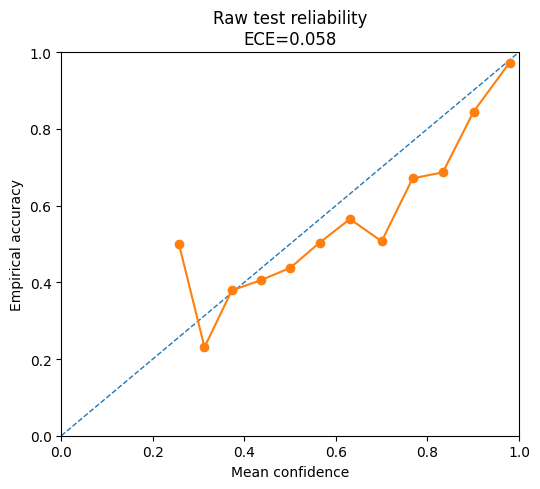

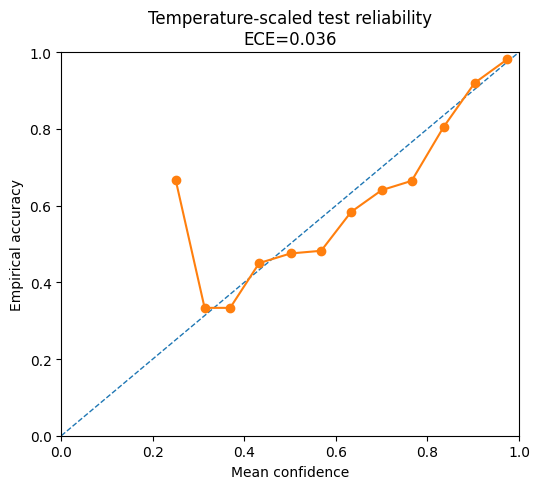

In [33]:
# --- Reliability diagrams ---

def plot_reliability(y_true, probs, out_path, title="Reliability diagram", n_bins=15):
    ece, bin_df = expected_calibration_error(y_true, probs, n_bins=n_bins)
    fig, ax = plt.subplots(figsize=(5.5, 5))
    ax.plot([0, 1], [0, 1], linestyle="--", linewidth=1)
    valid = bin_df["n"] > 0
    ax.plot(bin_df.loc[valid, "confidence"], bin_df.loc[valid, "accuracy"], marker="o")
    ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    ax.set_xlabel("Mean confidence")
    ax.set_ylabel("Empirical accuracy")
    ax.set_title(f"{title}\nECE={ece:.3f}")
    fig.tight_layout()
    fig.savefig(out_path, dpi=200)
    plt.show()
    return bin_df

if model_eval is not None:
    raw_bins = plot_reliability(y_test, test_probs_raw, FIG_DIR / "reliability_raw.png", "Raw test reliability", CONFIG["n_bins_ece"])
    temp_bins = plot_reliability(y_test, test_probs_temp, FIG_DIR / "reliability_temperature_scaled.png", "Temperature-scaled test reliability", CONFIG["n_bins_ece"])
    raw_bins.to_csv(RESULT_DIR / "reliability_bins_raw.csv", index=False)
    temp_bins.to_csv(RESULT_DIR / "reliability_bins_temperature_scaled.csv", index=False)
else:
    print("Skipped reliability diagrams; no model loaded.")

In [34]:
# --- Evaluate all trained model variants found in MODEL_DIR ---
# This creates a paper-ready comparison table for backbone/loss/seed runs.
# It uses the same validation-fitted temperature logic per model and evaluates once on the held-out test split.

def infer_model_metadata_from_path(model_path):
    run_tag = model_path.parent.name
    use_meta = "_meta_" in run_tag or "_multimodal_" in run_tag
    loss_type = "weighted_ce"
    for cand in ["class_balanced_ce", "weighted_ce", "focal"]:
        if run_tag.endswith(cand) or f"_{cand}" in run_tag:
            loss_type = cand
    return run_tag, use_meta, loss_type


all_model_rows = []
model_paths = sorted(MODEL_DIR.rglob("final_model.keras"))

for model_path in model_paths:
    try:
        run_tag, use_meta_i, loss_type_i = infer_model_metadata_from_path(model_path)
        m_i = safe_load_model(model_path)
        _, val_ds_i, test_ds_i = datasets_for(use_metadata=model_uses_metadata(m_i), loss_type=loss_type_i)

        v_logits, v_y = collect_logits(m_i, val_ds_i)
        te_logits, te_y = collect_logits(m_i, test_ds_i)

        t_i, val_nll_i = fit_temperature_scaling(v_logits, v_y, max_iter=250, lr=0.05)
        te_probs_raw = softmax_np(te_logits)
        te_probs_t = softmax_np(te_logits, temperature=t_i)

        raw_i = evaluate_probs(te_y, te_probs_raw, prefix="raw_")
        temp_i = evaluate_probs(te_y, te_probs_t, prefix="temp_")
        row = {
            "run_tag": run_tag,
            "model_path": str(model_path),
            "uses_metadata": model_uses_metadata(m_i),
            "temperature": t_i,
            "val_nll_temperature": val_nll_i,
            **raw_i,
            **temp_i,
        }

        runtime_path = model_path.parent / "runtime.json"
        if runtime_path.exists():
            try:
                rt = json.load(open(runtime_path))
                for k in ["backbone", "seed", "loss_type", "total_seconds", "head_seconds", "finetune_seconds", "reused_existing"]:
                    row[k] = rt.get(k)
            except Exception:
                pass

        all_model_rows.append(row)
        print("Evaluated:", run_tag)

    except Exception as e:
        all_model_rows.append({"run_tag": model_path.parent.name, "model_path": str(model_path), "error": repr(e)})
        print("Could not evaluate", model_path, "->", repr(e))

if all_model_rows:
    model_comparison_df = pd.DataFrame(all_model_rows)
    sort_col = "temp_macro_f1" if "temp_macro_f1" in model_comparison_df.columns else model_comparison_df.columns[0]
    display(model_comparison_df.sort_values(sort_col, ascending=False, na_position="last"))
    model_comparison_df.to_csv(RESULT_DIR / "all_trained_model_comparison.csv", index=False)
else:
    print("No trained model variants found yet.")

Evaluated: EfficientNetB0_image_seed2026_weighted_ce
Evaluated: EfficientNetB0_image_seed3407_weighted_ce
Evaluated: EfficientNetB0_image_seed42_class_balanced_ce
Evaluated: EfficientNetB0_image_seed42_focal
Evaluated: EfficientNetB0_image_seed42_weighted_ce
Evaluated: FINALCONFIRM_ResNet50_image_seed42_weighted_ce
Evaluated: MobileNetV2_image_seed42_weighted_ce
Evaluated: ResNet50_image_seed42_weighted_ce


,run_tag,model_path,uses_metadata,temperature,val_nll_temperature,raw_accuracy,raw_balanced_accuracy,raw_macro_f1,raw_weighted_f1,raw_macro_recall,...,temp_nll,temp_ece,temp_ovr_roc_auc_macro,backbone,seed,loss_type,total_seconds,head_seconds,finetune_seconds,reused_existing
7,ResNet50_image_seed42_weighted_ce,/content/ham10000_trustworthy_ai/models/ResNet...,False,1.166940,0.690939,0.716074,0.676075,0.610835,0.740370,0.676075,...,0.711250,0.035673,0.940304,ResNet50,42,weighted_ce,8016.708351,3122.518421,4894.189929,False
5,FINALCONFIRM_ResNet50_image_seed42_weighted_ce,/content/ham10000_trustworthy_ai/models/FINALC...,False,1.166940,0.690939,0.716074,0.676075,0.610835,0.740370,0.676075,...,0.711250,0.035673,0.940304,ResNet50,42,weighted_ce,8033.858391,3112.833783,4921.024609,False
6,MobileNetV2_image_seed42_weighted_ce,/content/ham10000_trustworthy_ai/models/Mobile...,False,1.065959,0.744255,0.714071,0.671722,0.588481,0.735585,0.671722,...,0.756396,0.029438,0.930369,MobileNetV2,42,weighted_ce,3458.869198,1117.679906,2341.189293,False
4,EfficientNetB0_image_seed42_weighted_ce,/content/ham10000_trustworthy_ai/models/Effici...,False,1.021595,0.734929,0.705058,0.671348,0.586023,0.732113,0.671348,...,0.753546,0.029027,0.928699,EfficientNetB0,42,weighted_ce,5648.357674,1565.513267,4082.844407,False
1,EfficientNetB0_image_seed3407_weighted_ce,/content/ham10000_trustworthy_ai/models/Effici...,False,1.016726,0.747967,0.699549,0.654050,0.573432,0.727274,0.654050,...,0.787003,0.032420,0.924799,EfficientNetB0,3407,weighted_ce,5061.369307,1579.942263,3481.427044,False
2,EfficientNetB0_image_seed42_class_balanced_ce,/content/ham10000_trustworthy_ai/models/Effici...,False,0.962759,0.746220,0.706059,0.670805,0.570339,0.731567,0.670805,...,0.766698,0.027893,0.926238,EfficientNetB0,42,class_balanced_ce,4810.558280,1575.521398,3235.036882,False
0,EfficientNetB0_image_seed2026_weighted_ce,/content/ham10000_trustworthy_ai/models/Effici...,False,0.952210,0.779547,0.692038,0.686316,0.568459,0.721095,0.686316,...,0.817445,0.027668,0.923328,EfficientNetB0,2026,weighted_ce,4157.821383,1545.934044,2611.887339,False
3,EfficientNetB0_image_seed42_focal,/content/ham10000_trustworthy_ai/models/Effici...,False,0.683267,0.802874,0.684527,0.672046,0.561352,0.715511,0.672046,...,0.823216,0.036745,0.922266,EfficientNetB0,42,focal,4150.514137,1551.166520,2599.347617,False


## 11. Selective referral / abstention analysis

The model is sorted from most certain to least certain. As coverage decreases, the system refers more uncertain cases to human review. The core question is whether selective referral reduces risk without disproportionately harming high-risk lesion sensitivity or subgroup coverage.

In [35]:
# --- Uncertainty scores and selective risk ---

def predictive_entropy(probs, eps=1e-12):
    p = np.clip(probs, eps, 1.0)
    return -np.sum(p * np.log(p), axis=1)


def confidence_margin(probs):
    s = np.sort(probs, axis=1)
    return s[:, -1] - s[:, -2]


def uncertainty_scores(probs):
    return {
        "maxprob_uncertainty": 1.0 - probs.max(axis=1),
        "entropy": predictive_entropy(probs),
        "negative_margin": -confidence_margin(probs),  # larger = more uncertain
    }


def selective_curve(y_true, probs, uncertainty, positive_class=None):
    """Risk-coverage curve with correct automatic sensitivity accounting.

    If positive_class is provided, auto_sensitivity_for_class is computed as:

        true positives that are kept AND predicted positive / all true positives

    Referred cases are therefore not counted as automatically detected. This avoids
    the previous bug where all predicted positives were counted, which could produce
    impossible sensitivity values above 1.
    """
    y_true = np.asarray(y_true).astype(int)
    probs = np.asarray(probs)
    uncertainty = np.asarray(uncertainty)

    pred = probs.argmax(axis=1)
    order = np.argsort(uncertainty)  # keep most certain first
    rows = []
    n = len(y_true)

    for k in range(max(1, int(0.05 * n)), n + 1):
        keep = order[:k]
        kept_mask = np.zeros(n, dtype=bool)
        kept_mask[keep] = True

        y_keep = y_true[keep]
        pred_keep = pred[keep]

        coverage = k / n
        risk = 1.0 - accuracy_score(y_keep, pred_keep)

        bal_acc = (
            balanced_accuracy_score(y_keep, pred_keep)
            if len(np.unique(y_keep)) > 1 else np.nan
        )

        macro_f1 = f1_score(
            y_keep,
            pred_keep,
            average="macro",
            zero_division=0,
        )

        row = {
            "coverage": coverage,
            "referral_rate": 1.0 - coverage,
            "selective_risk": risk,
            "balanced_accuracy": bal_acc,
            "macro_f1": macro_f1,
        }

        if positive_class is not None:
            true_pos = y_true == positive_class
            total_pos = int(true_pos.sum())

            if total_pos > 0:
                auto_detected_pos = (
                    true_pos
                    & kept_mask
                    & (pred == positive_class)
                ).sum()

                row["auto_sensitivity_for_class"] = auto_detected_pos / total_pos
                row["coverage_for_true_class"] = kept_mask[true_pos].mean()
            else:
                row["auto_sensitivity_for_class"] = np.nan
                row["coverage_for_true_class"] = np.nan

        rows.append(row)

    curve = pd.DataFrame(rows)

    if "auto_sensitivity_for_class" in curve.columns:
        max_sens = curve["auto_sensitivity_for_class"].dropna().max()
        assert (pd.isna(max_sens)) or (max_sens <= 1.0 + 1e-9), (
            "Selective sensitivity bug detected: auto_sensitivity_for_class exceeded 1."
        )

    # Area under risk-coverage: lower is better.
    aurc = np.trapz(curve["selective_risk"], curve["coverage"])
    return curve, float(aurc)


def summarize_selective(y_true, probs, scores):
    rows = []
    curves = {}
    mel_idx = CLASS_TO_IDX["mel"]

    for name, score in scores.items():
        curve, aurc = selective_curve(y_true, probs, score, positive_class=mel_idx)
        curves[name] = curve

        for target_cov in [0.95, 0.90, 0.80, 0.70, 0.50]:
            i = np.argmin(np.abs(curve["coverage"] - target_cov))
            row = curve.iloc[i].to_dict()
            row.update({"score": name, "target_coverage": target_cov, "AURC": aurc})
            rows.append(row)

    summary = pd.DataFrame(rows)

    if "auto_sensitivity_for_class" in summary.columns:
        assert summary["auto_sensitivity_for_class"].dropna().le(1.0 + 1e-9).all(), (
            "Selective summary contains impossible sensitivity > 1."
        )

    return summary, curves


if model_eval is not None:
    # Use calibrated probabilities for referral thresholds by default.
    probs_for_referral = test_probs_temp
    scores = uncertainty_scores(probs_for_referral)
    selective_summary, selective_curves = summarize_selective(y_test, probs_for_referral, scores)
    display(selective_summary)
    selective_summary.to_csv(RESULT_DIR / "selective_referral_summary.csv", index=False)

    for name, curve in selective_curves.items():
        curve.to_csv(RESULT_DIR / f"selective_curve_{name}.csv", index=False)

    print("Selective-referral curves saved. Sensitivity sanity check passed: values are bounded by 1.")
else:
    print("Skipped selective referral; no model loaded.")


,coverage,referral_rate,selective_risk,balanced_accuracy,macro_f1,auto_sensitivity_for_class,coverage_for_true_class,score,target_coverage,AURC
0,0.949925,0.050075,0.264101,0.690821,0.630851,0.611872,0.945205,maxprob_uncertainty,0.95,0.104883
1,0.899850,0.100150,0.248191,0.693756,0.638917,0.575342,0.867580,maxprob_uncertainty,0.90,0.104883
2,0.800200,0.199800,0.210263,0.715140,0.667815,0.511416,0.730594,maxprob_uncertainty,0.80,0.104883
3,0.700050,0.299950,0.168813,0.763386,0.713611,0.442922,0.593607,maxprob_uncertainty,0.70,0.104883
4,0.499750,0.500250,0.084168,0.805127,0.786205,0.219178,0.273973,maxprob_uncertainty,0.50,0.104883
5,0.949925,0.050075,0.266210,0.692752,0.630745,0.607306,0.931507,entropy,0.95,0.107709
6,0.899850,0.100150,0.254313,0.698232,0.638784,0.579909,0.858447,entropy,0.90,0.107709
7,0.800200,0.199800,0.212766,0.748900,0.701883,0.520548,0.735160,entropy,0.80,0.107709
8,0.700050,0.299950,0.177396,0.768226,0.723415,0.429224,0.579909,entropy,0.70,0.107709
9,0.499750,0.500250,0.080160,0.820672,0.808770,0.246575,0.296804,entropy,0.50,0.107709


Selective-referral curves saved. Sensitivity sanity check passed: values are bounded by 1.


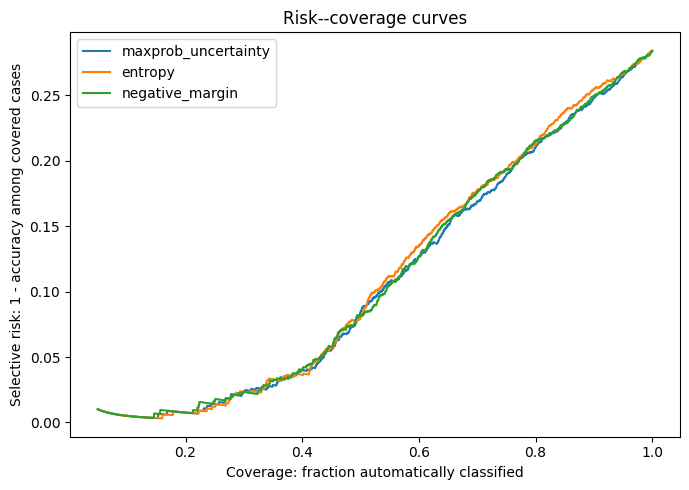

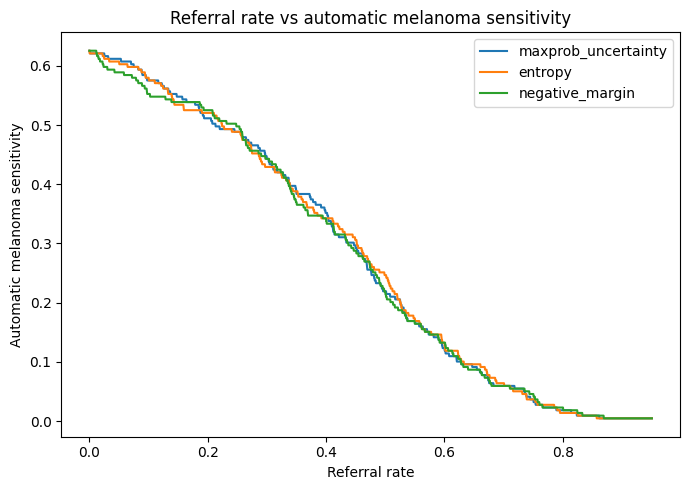

In [36]:
# --- Plot risk-coverage and referral curves ---

def plot_selective_curves(curves, out_path):
    fig, ax = plt.subplots(figsize=(7, 5))
    for name, curve in curves.items():
        ax.plot(curve["coverage"], curve["selective_risk"], label=name)
    ax.set_xlabel("Coverage: fraction automatically classified")
    ax.set_ylabel("Selective risk: 1 - accuracy among covered cases")
    ax.set_title("Risk--coverage curves")
    ax.legend()
    fig.tight_layout()
    fig.savefig(out_path, dpi=200)
    plt.show()


def plot_referral_vs_melanoma(curves, out_path):
    fig, ax = plt.subplots(figsize=(7, 5))
    for name, curve in curves.items():
        if "auto_sensitivity_for_class" in curve:
            ax.plot(curve["referral_rate"], curve["auto_sensitivity_for_class"], label=name)
    ax.set_xlabel("Referral rate")
    ax.set_ylabel("Automatic melanoma sensitivity")
    ax.set_title("Referral rate vs automatic melanoma sensitivity")
    ax.legend()
    fig.tight_layout()
    fig.savefig(out_path, dpi=200)
    plt.show()

if model_eval is not None:
    plot_selective_curves(selective_curves, FIG_DIR / "risk_coverage_curves.png")
    plot_referral_vs_melanoma(selective_curves, FIG_DIR / "referral_vs_melanoma_sensitivity.png")
else:
    print("Skipped selective plots; no model loaded.")

## 12. Internal subgroup analysis: sex, age, anatomical site, label-confirmation type

HAM10000 should not be over-claimed as a skin-tone fairness benchmark, because it does not provide reliable skin-tone or ethnicity labels. However, it does support internal subgroup analysis using available metadata: sex, age, anatomical site, and diagnosis-confirmation type.

In [37]:
import numpy as np
import pandas as pd

# --- Subgroup analysis ---

def add_age_bins(df):
    out = df.copy()
    out["age_bin"] = pd.cut(out["age"], bins=[-np.inf, 30, 45, 60, 75, np.inf], labels=["<=30", "31-45", "46-60", "61-75", ">75"])
    out["age_bin"] = out["age_bin"].astype(str).replace("nan", "missing")
    return out


def subgroup_metrics(df, y_true, probs, subgroup_col, min_n=30):
    rows = []
    tmp = df.reset_index(drop=True).copy()
    tmp["y_true"] = y_true
    pred = probs.argmax(axis=1)
    tmp["y_pred"] = pred

    # Get melanoma class index, assuming CLASS_TO_IDX is available in the global scope
    mel_idx = CLASS_TO_IDX["mel"]

    for group, idx in tmp.groupby(subgroup_col).groups.items():
        idx = np.array(list(idx))
        if len(idx) < min_n:
            continue

        subgroup_y_true = y_true[idx]
        subgroup_probs = probs[idx]
        subgroup_pred = subgroup_probs.argmax(axis=1)

        metrics = evaluate_probs(subgroup_y_true, subgroup_probs, prefix="")

        # Calculate melanoma recall for the subgroup
        mask_melanoma = subgroup_y_true == mel_idx
        total_melanoma_in_subgroup = mask_melanoma.sum()

        if total_melanoma_in_subgroup > 0:
            melanoma_recall_val = recall_score(mask_melanoma.astype(int), (subgroup_pred == mel_idx).astype(int), zero_division=0)
        else:
            melanoma_recall_val = np.nan # Use NaN if no melanoma cases in subgroup

        metrics["melanoma_recall"] = melanoma_recall_val

        metrics.update({"subgroup_variable": subgroup_col, "subgroup": str(group), "n": len(idx)})
        rows.append(metrics)
    return pd.DataFrame(rows)

if model_eval is not None:
    test_df_eval = add_age_bins(test_df)
    subgroup_vars = ["sex", "age_bin", "localization", "dx_type"]
    subgroup_tables = []
    for var in subgroup_vars:
        tab = subgroup_metrics(test_df_eval, y_test, test_probs_temp, var, min_n=CONFIG["min_subgroup_n"])
        subgroup_tables.append(tab)
    subgroup_results = pd.concat(subgroup_tables, axis=0, ignore_index=True)
    display(subgroup_results.sort_values(["subgroup_variable", "balanced_accuracy"]))
    subgroup_results.to_csv(RESULT_DIR / "internal_subgroup_metrics_temperature_scaled.csv", index=False)

    # Gap summary per variable.
    gap_rows = []
    for var, g in subgroup_results.groupby("subgroup_variable"):
        for metric in ["balanced_accuracy", "macro_f1", "brier", "ece", "melanoma_recall"]:
            vals = g[metric].dropna()
            if len(vals) >= 2:
                gap_rows.append({"subgroup_variable": var, "metric": metric, "min": vals.min(), "max": vals.max(), "gap": vals.max() - vals.min()})
    gap_df = pd.DataFrame(gap_rows)
    display(gap_df)
    gap_df.to_csv(RESULT_DIR / "internal_subgroup_gap_summary.csv", index=False)
else:
    print("Skipped subgroup analysis; no model loaded.")

,accuracy,balanced_accuracy,macro_f1,weighted_f1,macro_recall,brier,nll,ece,ovr_roc_auc_macro,melanoma_recall,subgroup_variable,subgroup,n
5,0.633803,0.533750,0.356345,0.744842,0.427000,0.454585,0.763626,0.080463,NaN,0.500000,age_bin,<=30,213
3,0.722973,0.629586,0.556613,0.749842,0.629586,0.369859,0.733396,0.059397,0.931476,0.647059,age_bin,46-60,592
4,0.677647,0.667199,0.626312,0.688513,0.667199,0.444085,0.850438,0.048189,0.930919,0.628571,age_bin,61-75,425
6,0.659722,0.692983,0.577558,0.663620,0.593985,0.456586,0.895360,0.072029,NaN,0.766667,age_bin,>75,144
2,0.776509,0.718116,0.589481,0.805705,0.718116,0.289402,0.531960,0.028573,0.955284,0.534884,age_bin,31-45,613
18,0.541746,0.613587,0.525417,0.552246,0.613587,0.598295,1.112909,0.097494,0.896926,0.625571,dx_type,histo,1054
16,0.721053,0.760860,0.550876,0.788425,0.507240,0.360124,0.663672,0.031446,NaN,NaN,dx_type,consensus,190
17,0.963365,0.963365,0.163557,0.981341,0.160561,0.063456,0.152016,0.063628,NaN,NaN,dx_type,follow_up,737
11,0.773333,0.334967,0.214489,0.822045,0.200980,0.290814,0.570506,0.165117,NaN,0.166667,localization,foot,75
8,0.622276,0.641829,0.459222,0.650317,0.550139,0.498310,0.938330,0.115274,NaN,0.769231,localization,back,413


,subgroup_variable,metric,min,max,gap
0,age_bin,balanced_accuracy,0.533750,0.718116,0.184366
1,age_bin,macro_f1,0.356345,0.626312,0.269967
2,age_bin,brier,0.289402,0.456586,0.167184
3,age_bin,ece,0.028573,0.080463,0.051890
4,age_bin,melanoma_recall,0.500000,0.766667,0.266667
5,dx_type,balanced_accuracy,0.613587,0.963365,0.349778
6,dx_type,macro_f1,0.163557,0.550876,0.387319
7,dx_type,brier,0.063456,0.598295,0.534838
8,dx_type,ece,0.031446,0.097494,0.066048
9,localization,balanced_accuracy,0.334967,0.866213,0.531246


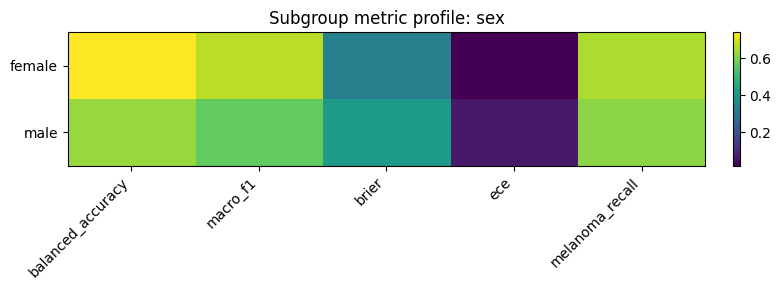

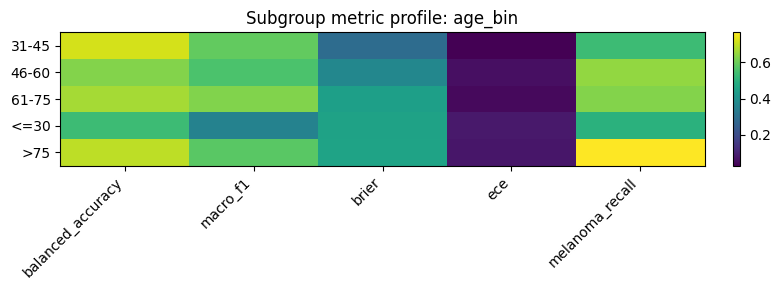

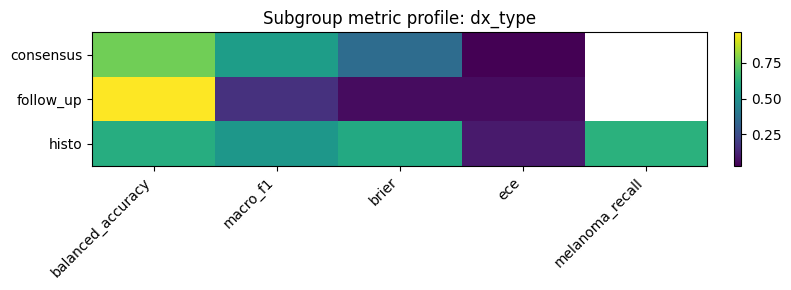

In [38]:
# --- Subgroup heatmap-style plot with matplotlib ---

if model_eval is not None and 'subgroup_results' in globals() and len(subgroup_results):
    plot_df = subgroup_results.copy()
    # Keep only moderate-sized subgroup tables to avoid unreadable figures.
    for var in ["sex", "age_bin", "dx_type"]:
        sub = plot_df[plot_df["subgroup_variable"] == var].copy()
        if sub.empty:
            continue
        metrics_to_plot = ["balanced_accuracy", "macro_f1", "brier", "ece", "melanoma_recall"]
        mat = sub.set_index("subgroup")[metrics_to_plot]
        fig, ax = plt.subplots(figsize=(8, max(3, 0.5 * len(mat))))
        im = ax.imshow(mat.values, aspect="auto")
        ax.set_xticks(np.arange(len(metrics_to_plot))); ax.set_xticklabels(metrics_to_plot, rotation=45, ha="right")
        ax.set_yticks(np.arange(len(mat.index))); ax.set_yticklabels(mat.index)
        ax.set_title(f"Subgroup metric profile: {var}")
        fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
        fig.tight_layout()
        fig.savefig(FIG_DIR / f"subgroup_metric_profile_{var}.png", dpi=200)
        plt.show()
else:
    print("Skipped subgroup plots.")

In [39]:
# --- Section 12A. Per-subgroup class counts ---
# Purpose:
#   Report the denominator behind subgroup metrics, especially melanoma, df, vasc, and akiec.
#   This prevents over-interpreting unstable recall values in small subgroups.

if model_eval is not None:
    test_df_eval = add_age_bins(test_df)
    subgroup_vars = ["sex", "age_bin", "localization", "dx_type"]

    subgroup_count_rows = []

    for var in subgroup_vars:
        tmp = test_df_eval.reset_index(drop=True).copy()
        tmp["true_label_id"] = y_test
        tmp["true_label"] = [CLASS_NAMES[int(i)] for i in y_test]

        for subgroup_name, g in tmp.groupby(var, dropna=False):
            label_counts = (
                g["true_label"]
                .value_counts()
                .reindex(CLASS_NAMES)
                .fillna(0)
                .astype(int)
                .to_dict()
            )

            row = {
                "subgroup_variable": var,
                "subgroup": str(subgroup_name),
                "n": int(len(g)),
            }

            # Add all class counts.
            for cls in CLASS_NAMES:
                row[f"n_{cls}"] = int(label_counts.get(cls, 0))

            # Add key rare/high-risk denominators explicitly.
            row["n_mel"] = int(label_counts.get("mel", 0))
            row["n_df"] = int(label_counts.get("df", 0))
            row["n_vasc"] = int(label_counts.get("vasc", 0))
            row["n_akiec"] = int(label_counts.get("akiec", 0))

            # Helpful instability flags.
            row["has_melanoma_cases"] = row["n_mel"] > 0
            row["melanoma_recall_unstable_if_lt10"] = row["n_mel"] < 10
            row["rare_class_min_n_akiec_df_vasc_mel"] = int(
                min(row["n_akiec"], row["n_df"], row["n_vasc"], row["n_mel"])
            )

            subgroup_count_rows.append(row)

    subgroup_class_counts = pd.DataFrame(subgroup_count_rows)

    # Sort to match the main subgroup table style.
    subgroup_class_counts = subgroup_class_counts.sort_values(
        ["subgroup_variable", "n"],
        ascending=[True, False]
    ).reset_index(drop=True)

    display_cols = [
        "subgroup_variable", "subgroup", "n",
        "n_akiec", "n_df", "n_vasc", "n_mel",
        "melanoma_recall_unstable_if_lt10",
        "rare_class_min_n_akiec_df_vasc_mel"
    ]

    display(subgroup_class_counts[display_cols])

    subgroup_class_counts.to_csv(
        RESULT_DIR / "internal_subgroup_class_counts.csv",
        index=False
    )

    print("Saved:", RESULT_DIR / "internal_subgroup_class_counts.csv")

else:
    print("Skipped subgroup class counts; no model loaded.")

,subgroup_variable,subgroup,n,n_akiec,n_df,n_vasc,n_mel,melanoma_recall_unstable_if_lt10,rare_class_min_n_akiec_df_vasc_mel
0,age_bin,31-45,613,4,10,7,43,False,4
1,age_bin,46-60,592,16,11,10,68,False,10
2,age_bin,61-75,425,31,5,8,70,False,5
3,age_bin,<=30,213,0,2,5,6,True,0
4,age_bin,>75,144,17,0,5,30,False,0
5,age_bin,missing,10,0,0,0,2,True,0
6,dx_type,histo,1054,68,12,11,219,False,11
7,dx_type,follow_up,737,0,0,0,0,True,0
8,dx_type,consensus,190,0,16,24,0,True,0
9,dx_type,confocal,16,0,0,0,0,True,0


Saved: /content/ham10000_trustworthy_ai/results/internal_subgroup_class_counts.csv


In [40]:
# --- Section 12B. Selective referral by subgroup ---
# Purpose:
#   For each subgroup, report how many cases would be automatically classified
#   and how many would be referred under fixed coverage or fixed target-risk rules.
#
# This directly supports the paper question:
#   "When should a skin-lesion AI abstain and refer to a human?"

def subgroup_selective_metrics_at_coverage(
    y_true_sub,
    probs_sub,
    uncertainty_sub,
    target_coverage=0.80
):
    """Selective-referral metrics within one subgroup at a fixed coverage."""
    y_true_sub = np.asarray(y_true_sub).astype(int)
    probs_sub = np.asarray(probs_sub)
    uncertainty_sub = np.asarray(uncertainty_sub)

    pred_sub = probs_sub.argmax(axis=1)
    n = len(y_true_sub)

    if n == 0:
        return None

    # Keep most certain cases.
    order = np.argsort(uncertainty_sub)
    k = int(np.ceil(target_coverage * n))
    k = max(1, min(k, n))
    keep = order[:k]

    y_keep = y_true_sub[keep]
    pred_keep = pred_sub[keep]

    mel_idx = CLASS_TO_IDX["mel"]
    true_mel_all = y_true_sub == mel_idx

    if true_mel_all.sum() > 0:
        # Automatic melanoma recall:
        # true melanoma cases must be both kept and predicted as melanoma.
        kept_mask = np.zeros(n, dtype=bool)
        kept_mask[keep] = True

        auto_mel_detected = (
            true_mel_all
            & kept_mask
            & (pred_sub == mel_idx)
        ).sum()

        melanoma_auto_recall = auto_mel_detected / true_mel_all.sum()
        melanoma_coverage = kept_mask[true_mel_all].mean()
    else:
        melanoma_auto_recall = np.nan
        melanoma_coverage = np.nan

    with warnings.catch_warnings():
        warnings.simplefilter("ignore")

        if len(np.unique(y_keep)) >= 2:
            bal_acc = balanced_accuracy_score(y_keep, pred_keep)
        else:
            bal_acc = np.nan

        macro_f1 = f1_score(
            y_keep,
            pred_keep,
            average="macro",
            zero_division=0
        )

    return {
        "target_coverage": float(target_coverage),
        "achieved_coverage": float(k / n),
        "referral_rate": float(1.0 - (k / n)),
        "n_total": int(n),
        "n_auto_classified": int(k),
        "n_referred": int(n - k),
        "selective_risk": float(1.0 - accuracy_score(y_keep, pred_keep)),
        "balanced_accuracy_auto_classified": float(bal_acc) if not pd.isna(bal_acc) else np.nan,
        "macro_f1_auto_classified": float(macro_f1),
        "melanoma_auto_recall": float(melanoma_auto_recall) if not pd.isna(melanoma_auto_recall) else np.nan,
        "melanoma_coverage": float(melanoma_coverage) if not pd.isna(melanoma_coverage) else np.nan,
        "n_mel": int(true_mel_all.sum()),
        "n_akiec": int((y_true_sub == CLASS_TO_IDX["akiec"]).sum()),
        "n_df": int((y_true_sub == CLASS_TO_IDX["df"]).sum()),
        "n_vasc": int((y_true_sub == CLASS_TO_IDX["vasc"]).sum()),
    }


def subgroup_selective_curve(y_true_sub, probs_sub, uncertainty_sub):
    """Full subgroup risk-coverage curve."""
    y_true_sub = np.asarray(y_true_sub).astype(int)
    probs_sub = np.asarray(probs_sub)
    uncertainty_sub = np.asarray(uncertainty_sub)

    pred_sub = probs_sub.argmax(axis=1)
    n = len(y_true_sub)

    order = np.argsort(uncertainty_sub)
    rows = []

    for k in range(1, n + 1):
        keep = order[:k]
        y_keep = y_true_sub[keep]
        pred_keep = pred_sub[keep]

        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            if len(np.unique(y_keep)) >= 2:
                bal_acc = balanced_accuracy_score(y_keep, pred_keep)
            else:
                bal_acc = np.nan

        rows.append({
            "coverage": k / n,
            "referral_rate": 1.0 - (k / n),
            "selective_risk": 1.0 - accuracy_score(y_keep, pred_keep),
            "balanced_accuracy_auto_classified": bal_acc,
            "macro_f1_auto_classified": f1_score(
                y_keep,
                pred_keep,
                average="macro",
                zero_division=0
            )
        })

    return pd.DataFrame(rows)


def subgroup_selective_at_target_risk(
    y_true_sub,
    probs_sub,
    uncertainty_sub,
    target_risk=0.20
):
    """Find maximum subgroup coverage that keeps selective risk <= target_risk."""
    curve = subgroup_selective_curve(y_true_sub, probs_sub, uncertainty_sub)

    eligible = curve[curve["selective_risk"] <= target_risk].copy()

    if eligible.empty:
        # No operating point achieves the target risk.
        best = curve.sort_values("selective_risk", ascending=True).iloc[0].to_dict()
        best.update({
            "target_risk": float(target_risk),
            "target_risk_achieved": False,
            "selection_rule": "minimum_observed_risk_because_target_not_reached",
        })
        return best

    # Among eligible points, choose largest coverage.
    best = eligible.sort_values("coverage", ascending=False).iloc[0].to_dict()
    best.update({
        "target_risk": float(target_risk),
        "target_risk_achieved": True,
        "selection_rule": "maximum_coverage_under_target_risk",
    })
    return best


if model_eval is not None:
    test_df_eval = add_age_bins(test_df)
    subgroup_vars = ["sex", "age_bin", "localization", "dx_type"]

    # Use calibrated probabilities for referral.
    probs_for_referral = test_probs_temp

    # Main uncertainty score.
    # Use entropy as the primary paper-facing score; maxprob can be used as sensitivity analysis.
    all_scores = uncertainty_scores(probs_for_referral)

    fixed_coverages = [0.95, 0.90, 0.80, 0.70]
    target_risks = [0.20, 0.15, 0.10]

    fixed_coverage_rows = []
    target_risk_rows = []

    for score_name, uncertainty in all_scores.items():
        for var in subgroup_vars:
            for subgroup_name, subgroup_index in test_df_eval.groupby(var, dropna=False).groups.items():
                subgroup_index = np.asarray(list(subgroup_index))

                if len(subgroup_index) < CONFIG["min_subgroup_n"]:
                    continue

                y_sub = y_test[subgroup_index]
                probs_sub = probs_for_referral[subgroup_index]
                uncertainty_sub = uncertainty[subgroup_index]

                for cov in fixed_coverages:
                    row = subgroup_selective_metrics_at_coverage(
                        y_true_sub=y_sub,
                        probs_sub=probs_sub,
                        uncertainty_sub=uncertainty_sub,
                        target_coverage=cov
                    )
                    row.update({
                        "score": score_name,
                        "subgroup_variable": var,
                        "subgroup": str(subgroup_name),
                        "rule_type": "fixed_coverage",
                    })
                    fixed_coverage_rows.append(row)

                for risk in target_risks:
                    row = subgroup_selective_at_target_risk(
                        y_true_sub=y_sub,
                        probs_sub=probs_sub,
                        uncertainty_sub=uncertainty_sub,
                        target_risk=risk
                    )
                    row.update({
                        "score": score_name,
                        "subgroup_variable": var,
                        "subgroup": str(subgroup_name),
                        "n_total": int(len(subgroup_index)),
                        "n_mel": int((y_sub == CLASS_TO_IDX["mel"]).sum()),
                        "n_akiec": int((y_sub == CLASS_TO_IDX["akiec"]).sum()),
                        "n_df": int((y_sub == CLASS_TO_IDX["df"]).sum()),
                        "n_vasc": int((y_sub == CLASS_TO_IDX["vasc"]).sum()),
                        "rule_type": "target_risk",
                    })
                    target_risk_rows.append(row)

    subgroup_selective_fixed_coverage = pd.DataFrame(fixed_coverage_rows)
    subgroup_selective_target_risk = pd.DataFrame(target_risk_rows)

    display(
        subgroup_selective_fixed_coverage.sort_values(
            ["score", "subgroup_variable", "subgroup", "target_coverage"]
        )
    )

    display(
        subgroup_selective_target_risk.sort_values(
            ["score", "subgroup_variable", "subgroup", "target_risk"]
        )
    )

    subgroup_selective_fixed_coverage.to_csv(
        RESULT_DIR / "subgroup_selective_referral_fixed_coverage.csv",
        index=False
    )

    subgroup_selective_target_risk.to_csv(
        RESULT_DIR / "subgroup_selective_referral_target_risk.csv",
        index=False
    )

    print("Saved:", RESULT_DIR / "subgroup_selective_referral_fixed_coverage.csv")
    print("Saved:", RESULT_DIR / "subgroup_selective_referral_target_risk.csv")

else:
    print("Skipped subgroup selective referral; no model loaded.")

,target_coverage,achieved_coverage,referral_rate,n_total,n_auto_classified,n_referred,selective_risk,balanced_accuracy_auto_classified,macro_f1_auto_classified,melanoma_auto_recall,melanoma_coverage,n_mel,n_akiec,n_df,n_vasc,score,subgroup_variable,subgroup,rule_type
87,0.70,0.701468,0.298532,613,430,183,0.097674,0.875973,0.802402,0.325581,0.418605,43,4,10,7,entropy,age_bin,31-45,fixed_coverage
86,0.80,0.800979,0.199021,613,491,122,0.142566,0.852419,0.769766,0.465116,0.627907,43,4,10,7,entropy,age_bin,31-45,fixed_coverage
85,0.90,0.900489,0.099511,613,552,61,0.192029,0.777830,0.652247,0.511628,0.813953,43,4,10,7,entropy,age_bin,31-45,fixed_coverage
84,0.95,0.951060,0.048940,613,583,30,0.205832,0.768687,0.606574,0.534884,0.906977,43,4,10,7,entropy,age_bin,31-45,fixed_coverage
91,0.70,0.701014,0.298986,592,415,177,0.154217,0.688086,0.620711,0.485294,0.588235,68,16,11,10,entropy,age_bin,46-60,fixed_coverage
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
152,0.95,0.950857,0.049143,875,832,43,0.225962,0.755975,0.687451,0.623377,0.922078,77,26,17,14,negative_margin,sex,female,fixed_coverage
159,0.70,0.700270,0.299730,1111,778,333,0.208226,0.699982,0.639990,0.429577,0.591549,142,42,11,21,negative_margin,sex,male,fixed_coverage
158,0.80,0.800180,0.199820,1111,889,222,0.253093,0.662789,0.613089,0.500000,0.732394,142,42,11,21,negative_margin,sex,male,fixed_coverage
157,0.90,0.900090,0.099910,1111,1000,111,0.286000,0.634738,0.574613,0.514085,0.816901,142,42,11,21,negative_margin,sex,male,fixed_coverage


,coverage,referral_rate,selective_risk,balanced_accuracy_auto_classified,macro_f1_auto_classified,target_risk,target_risk_achieved,selection_rule,score,subgroup_variable,subgroup,n_total,n_mel,n_akiec,n_df,n_vasc,rule_type
65,0.709625,0.290375,0.098851,0.869347,0.799707,0.10,True,maximum_coverage_under_target_risk,entropy,age_bin,31-45,613,43,4,10,7,target_risk
64,0.812398,0.187602,0.148594,0.837095,0.761368,0.15,True,maximum_coverage_under_target_risk,entropy,age_bin,31-45,613,43,4,10,7,target_risk
63,0.916803,0.083197,0.199288,0.766807,0.632375,0.20,True,maximum_coverage_under_target_risk,entropy,age_bin,31-45,613,43,4,10,7,target_risk
68,0.594595,0.405405,0.099432,0.821622,0.715584,0.10,True,maximum_coverage_under_target_risk,entropy,age_bin,46-60,592,68,16,11,10,target_risk
67,0.690878,0.309122,0.149144,0.702962,0.636800,0.15,True,maximum_coverage_under_target_risk,entropy,age_bin,46-60,592,68,16,11,10,target_risk
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
115,0.745143,0.254857,0.148773,0.792216,0.742470,0.15,True,maximum_coverage_under_target_risk,negative_margin,sex,female,875,77,26,17,14,target_risk
114,0.882286,0.117714,0.199482,0.768956,0.707152,0.20,True,maximum_coverage_under_target_risk,negative_margin,sex,female,875,77,26,17,14,target_risk
119,0.502250,0.497750,0.098566,0.705710,0.676997,0.10,True,maximum_coverage_under_target_risk,negative_margin,sex,male,1111,142,42,11,21,target_risk
118,0.592259,0.407741,0.148936,0.683888,0.638628,0.15,True,maximum_coverage_under_target_risk,negative_margin,sex,male,1111,142,42,11,21,target_risk


Saved: /content/ham10000_trustworthy_ai/results/subgroup_selective_referral_fixed_coverage.csv
Saved: /content/ham10000_trustworthy_ai/results/subgroup_selective_referral_target_risk.csv


## 13. Bootstrap confidence intervals

Bootstrap uncertainty should be reported for key metrics. This is especially important for minority classes such as `df`, `vasc`, and `akiec`, where single-point estimates can be unstable.

In [41]:
# --- Bootstrap confidence intervals ---

def bootstrap_ci_metrics(y_true, probs, n_reps=1000, seed=42):
    rng = np.random.default_rng(seed)
    n = len(y_true)
    rows = []
    for b in range(n_reps):
        idx = rng.integers(0, n, size=n)
        try:
            m = evaluate_probs(y_true[idx], probs[idx], prefix="")
            m["rep"] = b
            rows.append(m)
        except Exception:
            continue
    boot = pd.DataFrame(rows)
    summary = []
    for col in [c for c in boot.columns if c != "rep"]:
        vals = boot[col].dropna().values
        if len(vals) == 0:
            continue
        summary.append({
            "metric": col,
            "mean": float(vals.mean()),
            "lower_95": float(np.percentile(vals, 2.5)),
            "upper_95": float(np.percentile(vals, 97.5)),
        })
    return pd.DataFrame(summary), boot

RUN_BOOTSTRAP = CONFIG["run_bootstrap"]

if model_eval is not None and RUN_BOOTSTRAP:
    boot_summary, boot_raw = bootstrap_ci_metrics(y_test, test_probs_temp, n_reps=CONFIG["bootstrap_reps"], seed=CONFIG["seed"])
    display(boot_summary)
    boot_summary.to_csv(RESULT_DIR / "bootstrap_ci_summary_temperature_scaled.csv", index=False)
    boot_raw.to_csv(RESULT_DIR / "bootstrap_raw_temperature_scaled.csv", index=False)
else:
    print("Bootstrap skipped. Set CONFIG['run_bootstrap']=True for final reporting.")

,metric,mean,lower_95,upper_95
0,accuracy,0.716513,0.696044,0.736605
1,balanced_accuracy,0.676585,0.640132,0.714924
2,macro_f1,0.609976,0.573379,0.647523
3,weighted_f1,0.740877,0.723102,0.758448
4,macro_recall,0.676585,0.640132,0.714924
5,brier,0.375424,0.354952,0.395928
6,nll,0.710586,0.670201,0.749512
7,ece,0.040591,0.026960,0.055580
8,ovr_roc_auc_macro,0.940629,0.929053,0.949340


In [42]:
# --- Section 13A. Bootstrap confidence intervals for subgroup metrics ---
# Purpose:
#   Quantify uncertainty for subgroup balanced accuracy, macro-F1, Brier score, ECE,
#   and melanoma recall.
#
# Important:
#   This bootstraps within each subgroup. It does not claim causal fairness;
#   it quantifies how unstable each subgroup estimate is.

import warnings

def compact_subgroup_metrics(y_true_sub, probs_sub):
    """Metrics used for subgroup bootstrap CIs."""
    y_true_sub = np.asarray(y_true_sub).astype(int)
    probs_sub = np.asarray(probs_sub)
    pred_sub = probs_sub.argmax(axis=1)

    out = {}

    with warnings.catch_warnings():
        warnings.simplefilter("ignore")

        if len(np.unique(y_true_sub)) >= 2:
            out["balanced_accuracy"] = balanced_accuracy_score(y_true_sub, pred_sub)
        else:
            out["balanced_accuracy"] = np.nan

        out["macro_f1"] = f1_score(
            y_true_sub,
            pred_sub,
            average="macro",
            zero_division=0
        )

        out["brier"] = multiclass_brier(y_true_sub, probs_sub)

        out["ece"], _ = expected_calibration_error(
            y_true_sub,
            probs_sub,
            n_bins=CONFIG["n_bins_ece"]
        )

        mel_idx = CLASS_TO_IDX["mel"]
        true_mel = y_true_sub == mel_idx
        pred_mel = pred_sub == mel_idx

        if true_mel.sum() > 0:
            out["melanoma_recall"] = recall_score(
                true_mel.astype(int),
                pred_mel.astype(int),
                zero_division=0
            )
        else:
            out["melanoma_recall"] = np.nan

    return out


def bootstrap_subgroup_metrics(
    df_eval,
    y_true,
    probs,
    subgroup_vars,
    n_reps=1000,
    min_n=30,
    seed=42
):
    """Bootstrap subgroup metrics within each subgroup."""
    rng = np.random.default_rng(seed)
    rows = []
    raw_rows = []

    df_eval = df_eval.reset_index(drop=True).copy()

    for var in subgroup_vars:
        for subgroup_name, subgroup_index in df_eval.groupby(var, dropna=False).groups.items():
            subgroup_index = np.asarray(list(subgroup_index))

            if len(subgroup_index) < min_n:
                continue

            y_sub = y_true[subgroup_index]
            probs_sub = probs[subgroup_index]

            # Original point estimate.
            point = compact_subgroup_metrics(y_sub, probs_sub)

            # Class denominators.
            class_counts = {
                f"n_{cls}": int((y_sub == CLASS_TO_IDX[cls]).sum())
                for cls in CLASS_NAMES
            }

            boot_metric_rows = []

            for b in range(n_reps):
                boot_local_idx = rng.integers(0, len(subgroup_index), size=len(subgroup_index))

                try:
                    m = compact_subgroup_metrics(
                        y_sub[boot_local_idx],
                        probs_sub[boot_local_idx]
                    )
                    m.update({
                        "rep": b,
                        "subgroup_variable": var,
                        "subgroup": str(subgroup_name),
                        "n": int(len(subgroup_index)),
                    })
                    boot_metric_rows.append(m)
                    raw_rows.append(m)
                except Exception:
                    continue

            boot_df = pd.DataFrame(boot_metric_rows)

            for metric in ["balanced_accuracy", "macro_f1", "brier", "ece", "melanoma_recall"]:
                vals = boot_df[metric].dropna().values if metric in boot_df else np.array([])

                if len(vals) == 0:
                    rows.append({
                        "subgroup_variable": var,
                        "subgroup": str(subgroup_name),
                        "metric": metric,
                        "n": int(len(subgroup_index)),
                        "point_estimate": point.get(metric, np.nan),
                        "mean_bootstrap": np.nan,
                        "lower_95": np.nan,
                        "upper_95": np.nan,
                        "bootstrap_reps_successful": 0,
                        **class_counts,
                    })
                else:
                    rows.append({
                        "subgroup_variable": var,
                        "subgroup": str(subgroup_name),
                        "metric": metric,
                        "n": int(len(subgroup_index)),
                        "point_estimate": point.get(metric, np.nan),
                        "mean_bootstrap": float(np.mean(vals)),
                        "lower_95": float(np.percentile(vals, 2.5)),
                        "upper_95": float(np.percentile(vals, 97.5)),
                        "bootstrap_reps_successful": int(len(vals)),
                        **class_counts,
                    })

    summary = pd.DataFrame(rows)
    raw = pd.DataFrame(raw_rows)

    return summary, raw


if model_eval is not None and CONFIG["run_bootstrap"]:
    test_df_eval = add_age_bins(test_df)
    subgroup_vars = ["sex", "age_bin", "localization", "dx_type"]

    subgroup_bootstrap_ci, subgroup_bootstrap_raw = bootstrap_subgroup_metrics(
        df_eval=test_df_eval,
        y_true=y_test,
        probs=test_probs_temp,
        subgroup_vars=subgroup_vars,
        n_reps=CONFIG["bootstrap_reps"],
        min_n=CONFIG["min_subgroup_n"],
        seed=CONFIG["seed"]
    )

    display(
        subgroup_bootstrap_ci.sort_values(
            ["subgroup_variable", "subgroup", "metric"]
        )
    )

    subgroup_bootstrap_ci.to_csv(
        RESULT_DIR / "subgroup_bootstrap_ci_temperature_scaled.csv",
        index=False
    )

    subgroup_bootstrap_raw.to_csv(
        RESULT_DIR / "subgroup_bootstrap_raw_temperature_scaled.csv",
        index=False
    )

    print("Saved:", RESULT_DIR / "subgroup_bootstrap_ci_temperature_scaled.csv")
    print("Saved:", RESULT_DIR / "subgroup_bootstrap_raw_temperature_scaled.csv")

else:
    print("Subgroup bootstrap skipped. Set CONFIG['run_bootstrap']=True and load a model.")

,subgroup_variable,subgroup,metric,n,point_estimate,mean_bootstrap,lower_95,upper_95,bootstrap_reps_successful,n_akiec,n_bcc,n_bkl,n_df,n_mel,n_nv,n_vasc
10,age_bin,31-45,balanced_accuracy,613,0.718116,0.720678,0.608955,0.805266,1000,4,8,29,10,43,512,7
12,age_bin,31-45,brier,613,0.289402,0.289346,0.254930,0.322612,1000,4,8,29,10,43,512,7
13,age_bin,31-45,ece,613,0.028573,0.046992,0.029514,0.069504,1000,4,8,29,10,43,512,7
11,age_bin,31-45,macro_f1,613,0.589481,0.579843,0.472488,0.675339,1000,4,8,29,10,43,512,7
14,age_bin,31-45,melanoma_recall,613,0.534884,0.537815,0.387078,0.702188,1000,4,8,29,10,43,512,7
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5,sex,male,balanced_accuracy,1111,0.627087,0.627735,0.573981,0.681649,1000,42,62,144,11,142,689,21
7,sex,male,brier,1111,0.412401,0.412297,0.384368,0.441441,1000,42,62,144,11,142,689,21
8,sex,male,ece,1111,0.066471,0.071202,0.050262,0.092264,1000,42,62,144,11,142,689,21
6,sex,male,macro_f1,1111,0.566062,0.563694,0.516304,0.611557,1000,42,62,144,11,142,689,21


Saved: /content/ham10000_trustworthy_ai/results/subgroup_bootstrap_ci_temperature_scaled.csv
Saved: /content/ham10000_trustworthy_ai/results/subgroup_bootstrap_raw_temperature_scaled.csv


## 14. Optional MC Dropout inference

MC Dropout is computationally cheaper than a full deep ensemble but still increases inference cost because each image requires multiple stochastic forward passes. Use it only for the best model.

In [43]:
# --- MC Dropout inference: cached CPU sensitivity analysis ---
# MC Dropout is computationally expensive because it repeats inference many times.
# This version caches image batches once, then reuses them for all stochastic passes.

CONFIG["mc_dropout_passes"] = int(CONFIG.get("mc_dropout_passes", 20))
CONFIG["mc_dropout_max_n"] = CONFIG.get("mc_dropout_max_n", 500)


def freeze_batchnorm_for_mc_dropout(model):
    """Freeze BatchNorm layers while keeping Dropout active through training=True."""
    for layer in model.layers:
        if isinstance(layer, tf.keras.layers.BatchNormalization):
            layer.trainable = False
    return model


def to_numpy_batch_x(x):
    if isinstance(x, dict):
        return {k: np.asarray(v) for k, v in x.items()}
    return np.asarray(x)


def cache_sequence_batches(ds, max_n=None):
    """Cache batches from a Keras Sequence/iterable once to avoid repeated disk I/O."""
    cached_x = []
    cached_y = []
    n_seen = 0

    for batch in ds:
        if len(batch) == 3:
            x, y, _ = batch
        else:
            x, y = batch

        x_np = to_numpy_batch_x(x)
        y_np = to_numpy_1d(y)

        if max_n is not None:
            remaining = int(max_n) - n_seen
            if remaining <= 0:
                break

            if len(y_np) > remaining:
                y_np = y_np[:remaining]
                if isinstance(x_np, dict):
                    x_np = {k: v[:remaining] for k, v in x_np.items()}
                else:
                    x_np = x_np[:remaining]

        cached_x.append(x_np)
        cached_y.append(y_np)
        n_seen += len(y_np)

        if max_n is not None and n_seen >= int(max_n):
            break

    y_all = np.concatenate(cached_y, axis=0)
    print(f"Cached {len(y_all)} examples across {len(cached_x)} batches for MC Dropout.")
    return cached_x, y_all


def mc_forward(model, x):
    # Dropout active. BatchNorm layers are frozen beforehand for stability.
    with tf.device("/CPU:0"):
        return model(x, training=True)


def collect_mc_dropout_probs(model, ds, n_passes=20, max_n=None):
    model = freeze_batchnorm_for_mc_dropout(model)
    cached_x, y_all = cache_sequence_batches(ds, max_n=max_n)

    probs_passes = []

    for p in range(int(n_passes)):
        t_pass = time.time()
        logits_list = []

        for x_batch in cached_x:
            logits = mc_forward(model, x_batch).numpy()
            logits_list.append(logits)

        logits_p = np.concatenate(logits_list, axis=0)
        probs_passes.append(softmax_np(logits_p))

        print(f"MC pass {p + 1}/{n_passes} completed in {time.time() - t_pass:.1f} seconds.")

    probs_stack = np.stack(probs_passes, axis=0)
    mean_probs = probs_stack.mean(axis=0)

    epistemic_var = probs_stack.var(axis=0).mean(axis=1)
    entropy_mean = predictive_entropy(mean_probs)
    expected_entropy = np.mean(
        [predictive_entropy(probs_stack[i]) for i in range(int(n_passes))],
        axis=0,
    )
    mutual_information = entropy_mean - expected_entropy

    return y_all, mean_probs, {
        "mc_epistemic_var": epistemic_var,
        "mc_predictive_entropy": entropy_mean,
        "mc_mutual_information": mutual_information,
    }


if model_eval is not None and CONFIG["run_mc_dropout"]:
    t0 = time.time()

    y_mc, probs_mc, mc_scores = collect_mc_dropout_probs(
        model_eval,
        test_ds_eval,
        n_passes=CONFIG["mc_dropout_passes"],
        max_n=CONFIG.get("mc_dropout_max_n", None),
    )

    mc_runtime = time.time() - t0
    mc_metrics = evaluate_probs(y_mc, probs_mc, prefix="mc_dropout_")

    display(pd.DataFrame([mc_metrics]).T.rename(columns={0: "value"}))

    pd.DataFrame([{
        "mc_runtime_seconds": mc_runtime,
        "mc_dropout_passes": CONFIG["mc_dropout_passes"],
        "mc_dropout_max_n": CONFIG.get("mc_dropout_max_n", None),
        "mc_dropout_n_evaluated": len(y_mc),
        **mc_metrics,
    }]).to_csv(RESULT_DIR / "mc_dropout_metrics.csv", index=False)

    mc_summary, mc_curves = summarize_selective(y_mc, probs_mc, mc_scores)

    # Firm sanity check for the fixed selective-referral sensitivity calculation.
    if "auto_sensitivity_for_class" in mc_summary.columns:
        assert mc_summary["auto_sensitivity_for_class"].dropna().le(1.0 + 1e-9).all(), (
            "MC Dropout selective summary contains impossible sensitivity > 1."
        )

    display(mc_summary)

    mc_summary.to_csv(RESULT_DIR / "mc_dropout_selective_summary.csv", index=False)
    mc_curves_concat = pd.concat(
        [df.assign(score=name) for name, df in mc_curves.items()],
        ignore_index=True,
    )
    mc_curves_concat.to_csv(RESULT_DIR / "mc_dropout_selective_curves.csv", index=False)

    print("MC Dropout runtime seconds:", round(mc_runtime, 1))
    print("Saved MC Dropout outputs. Sensitivity sanity check passed.")
else:
    print("MC Dropout skipped. Set CONFIG['run_mc_dropout']=True for best model.")


Cached 500 examples across 63 batches for MC Dropout.
MC pass 1/20 completed in 53.0 seconds.
MC pass 2/20 completed in 49.9 seconds.
MC pass 3/20 completed in 51.0 seconds.
MC pass 4/20 completed in 50.9 seconds.
MC pass 5/20 completed in 51.9 seconds.
MC pass 6/20 completed in 52.4 seconds.
MC pass 7/20 completed in 50.9 seconds.
MC pass 8/20 completed in 50.7 seconds.
MC pass 9/20 completed in 52.1 seconds.
MC pass 10/20 completed in 50.1 seconds.
MC pass 11/20 completed in 51.0 seconds.
MC pass 12/20 completed in 52.8 seconds.
MC pass 13/20 completed in 49.6 seconds.
MC pass 14/20 completed in 50.7 seconds.
MC pass 15/20 completed in 50.8 seconds.
MC pass 16/20 completed in 50.9 seconds.
MC pass 17/20 completed in 50.9 seconds.
MC pass 18/20 completed in 51.1 seconds.
MC pass 19/20 completed in 51.2 seconds.
MC pass 20/20 completed in 51.3 seconds.


,value
mc_dropout_accuracy,0.690000
mc_dropout_balanced_accuracy,0.723985
mc_dropout_macro_f1,0.444675
mc_dropout_weighted_f1,0.748069
mc_dropout_macro_recall,0.413706
mc_dropout_brier,0.423857
mc_dropout_nll,0.814257
mc_dropout_ece,0.042272
mc_dropout_ovr_roc_auc_macro,NaN


,coverage,referral_rate,selective_risk,balanced_accuracy,macro_f1,auto_sensitivity_for_class,coverage_for_true_class,score,target_coverage,AURC
0,0.95,0.05,0.298947,0.751941,0.454660,0.621005,0.963470,mc_epistemic_var,0.95,0.158690
1,0.90,0.10,0.286667,0.745009,0.451852,0.607306,0.899543,mc_epistemic_var,0.90,0.158690
2,0.80,0.20,0.270000,0.755503,0.458939,0.529680,0.785388,mc_epistemic_var,0.80,0.158690
3,0.70,0.30,0.240000,0.789321,0.484672,0.484018,0.684932,mc_epistemic_var,0.70,0.158690
4,0.50,0.50,0.176000,0.856410,0.513413,0.347032,0.456621,mc_epistemic_var,0.50,0.158690
5,0.95,0.05,0.290526,0.738809,0.456424,0.611872,0.945205,mc_predictive_entropy,0.95,0.142819
6,0.90,0.10,0.273333,0.739929,0.457138,0.598174,0.894977,mc_predictive_entropy,0.90,0.142819
7,0.80,0.20,0.250000,0.783326,0.479267,0.538813,0.799087,mc_predictive_entropy,0.80,0.142819
8,0.70,0.30,0.208571,0.817119,0.494909,0.497717,0.698630,mc_predictive_entropy,0.70,0.142819
9,0.50,0.50,0.132000,0.896581,0.531203,0.365297,0.456621,mc_predictive_entropy,0.50,0.142819


MC Dropout runtime seconds: 1028.3
Saved MC Dropout outputs. Sensitivity sanity check passed.


## 15. Exploratory clean multimodal late-fusion ablation

This ablation tests whether deployable metadata improves performance. The model-input metadata are limited to **age, sex and anatomical site/localization**. The diagnostic-confirmation variable `dx_type` is deliberately excluded from model inputs and retained only for subgroup analysis, because it is not a deployable pre-diagnostic predictor.

In [44]:
# --- Train and evaluate exploratory clean multimodal late-fusion ablation ---
# Tests whether deployable metadata change classification, calibration, or subgroup stability.
#
# Methodological guard:
#   The metadata branch uses age, sex and localization only.
#   dx_type is excluded from model inputs because it reflects diagnostic-confirmation pathway.
#   Therefore, this ablation is suitable for reporting as "image + clean deployable metadata".
#
# Reporting guard:
#   The primary model is selected among image-only candidates. This multimodal result is
#   a secondary/exploratory ablation unless CONFIG["include_multimodal_in_model_selection"]
#   is deliberately changed and the model-selection cell is rerun.

RUN_MULTIMODAL_ABLATION = CONFIG["run_multimodal_ablation"]

assert "dx_type" not in META_CATEGORICAL_COLS + META_NUMERIC_COLS, (
    "dx_type leakage guard failed: dx_type must not be used as multimodal input."
)

if RUN_MULTIMODAL_ABLATION:
    tf.keras.backend.clear_session()
    gc.collect()

    multimodal_tag = f"{CONFIG['backbone']}_multimodal_cleanmeta_seed{CONFIG['seed']}_{CONFIG['loss_type']}"

    multimodal_model, multimodal_dir, multimodal_runtime = train_one_model(
        CONFIG["backbone"],
        use_metadata=True,
        seed=CONFIG["seed"],
        loss_type=CONFIG["loss_type"],
        run_tag=multimodal_tag,
    )

    _, mm_val_ds, mm_test_ds = compatible_datasets_for_model(multimodal_model)
    mm_val_logits, mm_y_val = collect_logits(multimodal_model, mm_val_ds)
    mm_test_logits, mm_y_test = collect_logits(multimodal_model, mm_test_ds)

    mm_T, mm_val_nll = fit_temperature_scaling(mm_val_logits, mm_y_val)
    mm_test_probs = softmax_np(mm_test_logits, temperature=mm_T)

    mm_metrics = evaluate_probs(mm_y_test, mm_test_probs, prefix="multimodal_temp_")

    multimodal_row = {
        "ablation_scope": "secondary_exploratory_clean_metadata",
        "selection_status": "not_used_for_primary_test_model_selection",
        "metadata_inputs": ",".join(META_NUMERIC_COLS + META_CATEGORICAL_COLS),
        "excluded_from_inputs": "dx_type",
        "temperature": mm_T,
        "val_nll_temperature": mm_val_nll,
        **mm_metrics,
        **multimodal_runtime,
    }

    display(pd.DataFrame([mm_metrics]).T.rename(columns={0: "value"}))

    pd.DataFrame([multimodal_row]).to_csv(
        RESULT_DIR / "multimodal_cleanmeta_test_metrics_temperature_scaled.csv",
        index=False,
    )

    print("Saved clean multimodal ablation results.")
    print("Metadata inputs:", META_NUMERIC_COLS + META_CATEGORICAL_COLS)
    print("Excluded from inputs: dx_type")
else:
    print("Multimodal ablation skipped. Set CONFIG['run_multimodal_ablation']=True when baseline is stable.")


Building model safely | EfficientNetB0_multimodal_cleanmeta_seed42_weighted_ce


Stage 1: frozen backbone head training | EfficientNetB0_multimodal_cleanmeta_seed42_weighted_ce
[before head training: EfficientNetB0_multimodal_cleanmeta_seed42_weighted_ce] CPU TensorFlow sanity check passed; checksum=519435.688
Epoch 1/8
802/802 ━━━━━━━━━━━━━━━━━━━━ 214s 248ms/step - accuracy: 0.3661 - loss: 1.7291 - val_accuracy: 0.5657 - val_loss: 1.2328 - learning_rate: 0.0010
Epoch 2/8
802/802 ━━━━━━━━━━━━━━━━━━━━ 192s 239ms/step - accuracy: 0.5049 - loss: 1.3185 - val_accuracy: 0.6156 - val_loss: 1.0504 - learning_rate: 0.0010
Epoch 3/8
802/802 ━━━━━━━━━━━━━━━━━━━━ 190s 237ms/step - accuracy: 0.5336 - loss: 1.2166 - val_accuracy: 0.6380 - val_loss: 0.9624 - learning_rate: 0.0010
Epoch 4/8
802/802 ━━━━━━━━━━━━━━━━━━━━ 248s 309ms/step - accuracy: 0.5462 - loss: 1.1290 - val_accuracy: 0.6137 - val_loss: 1.0518 - learning_rate: 0.0010
Epoch 5/8
802/802 ━━━━━━━━━━━━━━━━━━━━ 201s 251ms/step - accuracy: 0.5674 - loss: 1.0847 - val_accuracy: 0.6324 - val_loss: 1.0231 - learning_rate: 0

,value
multimodal_temp_accuracy,0.723585
multimodal_temp_balanced_accuracy,0.698743
multimodal_temp_macro_f1,0.609324
multimodal_temp_weighted_f1,0.749335
multimodal_temp_macro_recall,0.698743
multimodal_temp_brier,0.373444
multimodal_temp_nll,0.703211
multimodal_temp_ece,0.046140
multimodal_temp_ovr_roc_auc_macro,0.939367


Saved clean multimodal ablation results.
Metadata inputs: ['age', 'sex', 'localization']
Excluded from inputs: dx_type


## 16. Optional external ISIC 2018 Task 3 test evaluation from the same zip

Your screenshot suggests that the zip includes `ISIC2018_Task3_Test_GroundTruth` and `ISIC2018_Task3_Test_Images`. This is not a skin-tone fairness test, but it can provide an external domain check for the same seven-class task.

Because external metadata may be missing or formatted differently, this section uses image-only evaluation by default; for a multimodal model, metadata is filled with safe unknown/default values through the training-fitted preprocessor.

In [45]:
# --- External ISIC2018 test-set dataframe builder ---
# Supports both:
#   1) HAM10000-style long format with columns: image_id, dx
#   2) Original ISIC one-hot format with columns: MEL, NV, BCC, AKIEC, BKL, DF, VASC
#
# Output:
#   external_isic2018_df
#
# Important:
#   This cell only builds the external dataframe.
#   It does not train or tune anything on the external set.

ISIC2018_LABEL_MAP = {
    "MEL": "mel",
    "NV": "nv",
    "BCC": "bcc",
    "AKIEC": "akiec",
    "BKL": "bkl",
    "DF": "df",
    "VASC": "vasc",
}

def find_isic2018_groundtruth(root):
    """Find ISIC2018 Task 3 test ground-truth CSV."""
    root = Path(root)
    cands = []

    for p in root.rglob("*"):
        if not p.is_file():
            continue

        name = p.name.lower()

        if (
            "isic2018_task3_test_groundtruth" in name
            or "isic2018_task3_test" in name and "groundtruth" in name
            or "task3_test_groundtruth" in name
        ):
            cands.append(p)

    return sorted(cands, key=lambda p: len(str(p)))


def build_image_stem_map(root):
    """Map image stem -> image file path across extracted raw directory."""
    root = Path(root)
    img_map = {}

    for p in root.rglob("*"):
        if p.is_file() and p.suffix.lower() in IMAGE_EXTS:
            # If duplicates exist, keep the first discovered path.
            img_map.setdefault(p.stem, str(p))

    return img_map


def normalise_dx_label(x):
    """Normalise diagnosis strings to CLASS_NAMES convention."""
    if pd.isna(x):
        return np.nan

    x = str(x).strip()

    # Handle one-hot idxmax labels like MEL/NV/BCC.
    if x.upper() in ISIC2018_LABEL_MAP:
        return ISIC2018_LABEL_MAP[x.upper()]

    # Handle already-lowercase HAM10000 labels like nv, mel, bkl.
    x = x.lower()

    # Some files may use alternative spelling.
    alias = {
        "melanoma": "mel",
        "nevus": "nv",
        "nevi": "nv",
        "basal cell carcinoma": "bcc",
        "actinic keratosis": "akiec",
        "actinic keratoses": "akiec",
        "benign keratosis": "bkl",
        "benign keratosis-like lesions": "bkl",
        "dermatofibroma": "df",
        "vascular lesion": "vasc",
        "vascular lesions": "vasc",
    }

    return alias.get(x, x)


def infer_dx_from_groundtruth(gt):
    """Infer dx labels from either direct dx column or one-hot ISIC columns."""
    gt = gt.copy()

    # Case 1: already has dx column.
    if "dx" in gt.columns:
        gt["dx"] = gt["dx"].apply(normalise_dx_label)
        return gt

    # Case 2: one-hot encoded columns.
    onehot_cols = [c for c in gt.columns if c.upper() in ISIC2018_LABEL_MAP]

    if not onehot_cols:
        raise ValueError(
            "Could not find diagnosis information. Expected either a 'dx' column "
            "or one-hot columns such as MEL, NV, BCC, AKIEC, BKL, DF, VASC. "
            f"Found columns: {gt.columns.tolist()}"
        )

    # Convert one-hot row to diagnosis.
    onehot_df = gt[onehot_cols].apply(pd.to_numeric, errors="coerce").fillna(0)

    gt["dx_original"] = onehot_df.idxmax(axis=1)
    gt["dx"] = gt["dx_original"].apply(normalise_dx_label)

    return gt


def infer_image_id_column(gt):
    """Find the image identifier column robustly."""
    preferred = ["image_id", "image", "isic_id", "ISIC_id", "id"]

    for col in preferred:
        if col in gt.columns:
            return col

    # Fallback: if no obvious image column, use the first column.
    # But this is less safe, so we print a warning.
    print("Warning: could not find a standard image-id column. Using first column:", gt.columns[0])
    return gt.columns[0]


def build_external_isic2018_df(root):
    """Build external ISIC2018 dataframe compatible with notebook evaluation functions."""
    root = Path(root)

    gt_cands = find_isic2018_groundtruth(root)
    if not gt_cands:
        print("No ISIC2018 Task 3 ground-truth CSV found.")
        return None

    gt_path = gt_cands[0]
    print("Using ISIC2018 ground truth:", gt_path)

    gt = pd.read_csv(gt_path)
    print("ISIC2018 GT columns:", gt.columns.tolist())
    display(gt.head())

    gt = infer_dx_from_groundtruth(gt)

    # Keep only labels that match the current 7-class classifier.
    gt["dx"] = gt["dx"].astype(str).str.lower()
    unknown_dx = sorted(set(gt["dx"].dropna()) - set(CLASS_NAMES))

    if unknown_dx:
        print("Warning: dropping unsupported diagnosis labels:", unknown_dx)

    gt = gt.loc[gt["dx"].isin(CLASS_NAMES)].copy()

    if gt.empty:
        raise ValueError("After label filtering, no ISIC2018 rows matched CLASS_NAMES.")

    id_col = infer_image_id_column(gt)

    # Important:
    # In your file, image_id is the correct column.
    # Do NOT accidentally use lesion_id, because HAMTEST_... is not the image filename stem.
    gt["image_id"] = gt[id_col].astype(str).str.replace(".jpg", "", regex=False).str.replace(".jpeg", "", regex=False).str.replace(".png", "", regex=False)

    gt["label"] = gt["dx"].map(CLASS_TO_IDX)

    if gt["label"].isna().any():
        bad = gt.loc[gt["label"].isna(), "dx"].unique()
        raise ValueError(f"Some dx values could not be mapped to CLASS_TO_IDX: {bad}")

    gt["label"] = gt["label"].astype(int)

    img_map = build_image_stem_map(root)
    print("Number of image files discovered under RAW_DIR:", len(img_map))

    gt["image_path"] = gt["image_id"].map(img_map)

    missing_img = gt["image_path"].isna().sum()
    if missing_img > 0:
        print(f"Warning: {missing_img} ISIC2018 rows did not match an extracted image file.")
        print("Examples of missing image_ids:", gt.loc[gt["image_path"].isna(), "image_id"].head(10).tolist())

    gt = gt.loc[gt["image_path"].notna()].copy().reset_index(drop=True)

    if gt.empty:
        raise FileNotFoundError(
            "Ground-truth CSV was found, but no image_id values matched extracted image files. "
            "Check whether the ISIC2018 test images were extracted under RAW_DIR."
        )

    # Preserve metadata if present; otherwise create safe placeholders.
    if "lesion_id" not in gt.columns:
        gt["lesion_id"] = gt["image_id"]

    if "age" not in gt.columns:
        gt["age"] = np.nan

    if "sex" not in gt.columns:
        gt["sex"] = "missing"

    if "localization" not in gt.columns:
        gt["localization"] = "missing"

    if "dx_type" not in gt.columns:
        gt["dx_type"] = "external_isic2018"

    # Clean metadata types.
    gt["sex"] = gt["sex"].fillna("missing").astype(str).str.lower()
    gt["localization"] = gt["localization"].fillna("missing").astype(str).str.lower()
    gt["dx_type"] = gt["dx_type"].fillna("external_isic2018").astype(str).str.lower()

    out_cols = [
        "lesion_id",
        "image_id",
        "dx",
        "dx_type",
        "age",
        "sex",
        "localization",
        "image_path",
        "label",
    ]

    external_df = gt[out_cols].copy()

    print("External ISIC2018 rows with matched images:", len(external_df))
    print("External ISIC2018 class distribution:")
    display(external_df["dx"].value_counts().reindex(CLASS_NAMES).fillna(0).astype(int))

    return external_df


external_isic2018_df = None

if CONFIG["run_isic2018_external_if_found"]:
    external_isic2018_df = build_external_isic2018_df(RAW_DIR)

    if external_isic2018_df is None:
        print("No ISIC2018 external test set found in zip.")
    else:
        print("External ISIC2018 dataframe ready.")
        display(external_isic2018_df.head())

else:
    print("External evaluation disabled.")

Using ISIC2018 ground truth: /content/ham10000_trustworthy_ai/raw/ISIC2018_Task3_Test_GroundTruth.csv
ISIC2018 GT columns: ['lesion_id', 'image_id', 'dx', 'dx_type', 'age', 'sex', 'localization', 'dataset']


,lesion_id,image_id,dx,dx_type,age,sex,localization,dataset
0,HAMTEST_0000000,ISIC_0034524,nv,follow_up,40.0,female,back,vidir_molemax
1,HAMTEST_0000001,ISIC_0034525,nv,histo,70.0,male,abdomen,rosendahl
2,HAMTEST_0000002,ISIC_0034526,bkl,histo,70.0,male,back,rosendahl
3,HAMTEST_0000003,ISIC_0034527,nv,histo,35.0,male,trunk,vienna_dias
4,HAMTEST_0000004,ISIC_0034528,nv,follow_up,75.0,female,trunk,vidir_molemax


Number of image files discovered under RAW_DIR: 23053
Examples of missing image_ids: ['ISIC_0035068']
External ISIC2018 rows with matched images: 1511
External ISIC2018 class distribution:


,count
dx,
akiec,43
bcc,93
bkl,217
df,44
mel,171
nv,908
vasc,35


External ISIC2018 dataframe ready.


,lesion_id,image_id,dx,dx_type,age,sex,localization,image_path,label
0,HAMTEST_0000000,ISIC_0034524,nv,follow_up,40.0,female,back,/content/ham10000_trustworthy_ai/raw/ISIC2018_...,5
1,HAMTEST_0000001,ISIC_0034525,nv,histo,70.0,male,abdomen,/content/ham10000_trustworthy_ai/raw/ISIC2018_...,5
2,HAMTEST_0000002,ISIC_0034526,bkl,histo,70.0,male,back,/content/ham10000_trustworthy_ai/raw/ISIC2018_...,2
3,HAMTEST_0000003,ISIC_0034527,nv,histo,35.0,male,trunk,/content/ham10000_trustworthy_ai/raw/ISIC2018_...,5
4,HAMTEST_0000004,ISIC_0034528,nv,follow_up,75.0,female,trunk,/content/ham10000_trustworthy_ai/raw/ISIC2018_...,5


,value
isic2018_external_accuracy,0.698213
isic2018_external_balanced_accuracy,0.635055
isic2018_external_macro_f1,0.608030
isic2018_external_weighted_f1,0.717981
isic2018_external_macro_recall,0.635055
isic2018_external_brier,0.392296
isic2018_external_nll,0.763769
isic2018_external_ece,0.038432
isic2018_external_ovr_roc_auc_macro,0.934302


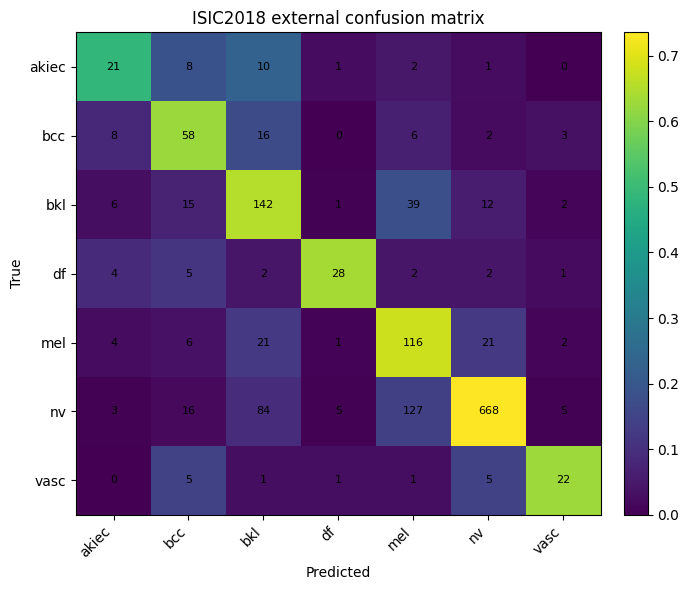

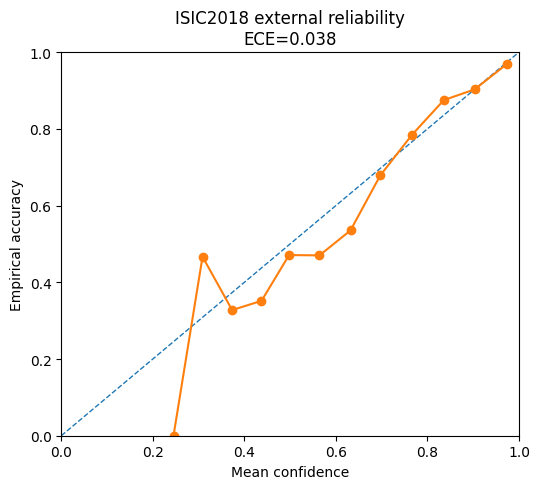

In [46]:
# --- Evaluate external ISIC2018 if available ---

if model_eval is not None and external_isic2018_df is not None and len(external_isic2018_df) > 0:
    X_meta_ext = meta_pre.transform(external_isic2018_df)
    ext_ds = make_tf_dataset(
        external_isic2018_df, X_meta_ext,
        training=False, shuffle=False,
        use_metadata=model_uses_metadata(model_eval)
    )
    ext_logits, y_ext = collect_logits(model_eval, ext_ds)
    # Use temperature fitted on HAM10000 validation set, not external labels.
    ext_probs = softmax_np(ext_logits, temperature=T if "T" in globals() else 1.0)
    ext_metrics = evaluate_probs(y_ext, ext_probs, prefix="isic2018_external_")
    display(pd.DataFrame([ext_metrics]).T.rename(columns={0: "value"}))
    pd.DataFrame([ext_metrics]).to_csv(RESULT_DIR / "isic2018_external_metrics.csv", index=False)
    plot_confusion(y_ext, ext_probs, FIG_DIR / "isic2018_external_confusion_matrix.png", "ISIC2018 external confusion matrix")
    plot_reliability(y_ext, ext_probs, FIG_DIR / "isic2018_external_reliability.png", "ISIC2018 external reliability", CONFIG["n_bins_ece"])
else:
    print("External ISIC2018 evaluation skipped.")

## 17. Stress testing for clinic-readiness

Stress testing checks whether small acquisition or preprocessing changes destabilise predictions. This is not a replacement for real external validation, but it is a useful reliability screen.

In [47]:
# --- Stress-test dataset construction ---
# Uses the same CPU-only Keras Sequence/PIL backend as the main evaluation pipeline.

def stress_transform_numpy(img, mode):
    """Apply light stress transforms to a float32 RGB image in 0-255 scale."""
    img_uint8 = np.clip(img, 0, 255).astype("uint8")
    im = Image.fromarray(img_uint8, mode="RGB")

    if mode == "none":
        return img.astype("float32")
    if mode == "brightness_up":
        im = ImageEnhance.Brightness(im).enhance(1.15)
    elif mode == "brightness_down":
        im = ImageEnhance.Brightness(im).enhance(0.85)
    elif mode == "contrast_up":
        im = ImageEnhance.Contrast(im).enhance(1.25)
    elif mode == "contrast_down":
        im = ImageEnhance.Contrast(im).enhance(0.75)
    elif mode == "jpeg_quality_40":
        import io
        buffer = io.BytesIO()
        im.save(buffer, format="JPEG", quality=40)
        buffer.seek(0)
        im = Image.open(buffer).convert("RGB").resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR)
    elif mode == "central_crop_90":
        w, h = im.size
        cw, ch = int(w * 0.90), int(h * 0.90)
        left, top = (w - cw) // 2, (h - ch) // 2
        im = im.crop((left, top, left + cw, top + ch)).resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR)
    else:
        raise ValueError(mode)

    return np.asarray(im, dtype="float32")


class StressSequence(HAM10000Sequence):
    def __init__(self, *args, stress_mode="none", **kwargs):
        super().__init__(*args, **kwargs)
        self.stress_mode = stress_mode

    def __getitem__(self, batch_idx):
        start = batch_idx * self.batch_size
        end = min((batch_idx + 1) * self.batch_size, len(self.paths))
        batch_indexes = self.indexes[start:end]

        images = np.empty((len(batch_indexes), IMG_SIZE, IMG_SIZE, 3), dtype="float32")
        for j, idx in enumerate(batch_indexes):
            arr = load_image_numpy(self.paths[idx], training=False)
            images[j] = stress_transform_numpy(arr, self.stress_mode)

        y = self.labels[batch_indexes].astype("int32")
        if self.use_metadata:
            x = {"image": images, "metadata": self.X_meta[batch_indexes].astype("float32")}
        else:
            x = {"image": images}
        return x, y


def make_stress_dataset(df, X_meta, mode="none", max_images=None, use_metadata=False):
    if max_images is not None and len(df) > max_images:
        df_use = df.sample(max_images, random_state=CONFIG["seed"]).reset_index(drop=True)
        X_use = meta_pre.transform(df_use)
    else:
        df_use = df.reset_index(drop=True)
        X_use = X_meta

    ds = StressSequence(
        df=df_use,
        X_meta=X_use,
        batch_size=BATCH_SIZE,
        training=False,
        shuffle=False,
        use_metadata=use_metadata,
        include_sample_weight=False,
        seed=int(CONFIG["seed"]),
        stress_mode=mode,
    )
    return ds, df_use


if model_eval is not None and CONFIG["run_stress_tests"]:
    stress_modes = ["none", "brightness_up", "brightness_down", "contrast_up", "contrast_down", "jpeg_quality_40", "central_crop_90"]
    stress_rows = []
    for mode in stress_modes:
        ds_stress, df_stress = make_stress_dataset(
            test_df, X_meta_test, mode=mode,
            max_images=CONFIG["stress_test_max_images"],
            use_metadata=model_uses_metadata(model_eval)
        )
        logits_s, y_s = collect_logits(model_eval, ds_stress)
        probs_s = softmax_np(logits_s, temperature=T if "T" in globals() else 1.0)
        m = evaluate_probs(y_s, probs_s, prefix="")
        m["stress_mode"] = mode
        m["n"] = len(y_s)
        stress_rows.append(m)
        print(mode, m["balanced_accuracy"], m["macro_f1"], m["ece"])
    stress_df = pd.DataFrame(stress_rows)
    display(stress_df)
    stress_df.to_csv(RESULT_DIR / "stress_test_metrics.csv", index=False)
else:
    print("Stress tests skipped.")


none 0.6922652894865224 0.6270569881758031 0.05445846305787564
brightness_up 0.6850798159048986 0.5870907765958967 0.04750519087910653
brightness_down 0.608234793655838 0.5732579072009726 0.04978295427560809
contrast_up 0.6525476197651133 0.6019334627283095 0.07601116168498993
contrast_down 0.6677221142502135 0.5891495068326206 0.05660860899090768
jpeg_quality_40 0.6197511792017473 0.5654647765791221 0.020904235869646074
central_crop_90 0.6829313881804178 0.615271818511103 0.03231155592203141


,accuracy,balanced_accuracy,macro_f1,weighted_f1,macro_recall,brier,nll,ece,ovr_roc_auc_macro,stress_mode,n
0,0.710,0.692265,0.627057,0.732352,0.692265,0.380088,0.715757,0.054458,0.942967,none,1000
1,0.693,0.685080,0.587091,0.718607,0.685080,0.399402,0.766668,0.047505,0.937967,brightness_up,1000
2,0.699,0.608235,0.573258,0.717116,0.608235,0.388166,0.737019,0.049783,0.940739,brightness_down,1000
3,0.685,0.652548,0.601933,0.711971,0.652548,0.404213,0.737927,0.076011,0.941177,contrast_up,1000
4,0.704,0.667722,0.589150,0.724267,0.667722,0.415391,0.801963,0.056609,0.936210,contrast_down,1000
5,0.740,0.619751,0.565465,0.742734,0.619751,0.356058,0.697175,0.020904,0.935599,jpeg_quality_40,1000
6,0.718,0.682931,0.615272,0.737443,0.682931,0.366455,0.695350,0.032312,0.943664,central_crop_90,1000


In [ ]:
# --- Stress-test plot ---

if 'stress_df' in globals() and len(stress_df):
    metrics_to_plot = ["balanced_accuracy", "macro_f1", "brier", "ece"]
    for metric in metrics_to_plot:
        fig, ax = plt.subplots(figsize=(8, 4.5))
        ax.bar(stress_df["stress_mode"], stress_df[metric])
        ax.set_title(f"Stress-test impact: {metric}")
        ax.set_ylabel(metric)
        ax.tick_params(axis="x", rotation=45)
        fig.tight_layout()
        fig.savefig(FIG_DIR / f"stress_test_{metric}.png", dpi=200)
        plt.show()
else:
    print("No stress-test results to plot.")

## 18. Optional Grad-CAM for error and high-uncertainty review

Grad-CAM should be treated as a qualitative audit aid, not proof that the model has learned clinically causal features. Use it for selected true positives, false negatives, false positives, and high-uncertainty cases.

Grad-CAM layer: conv5_block3_3_conv
Case: ISIC_0025960 true: nv pred: mel uncertainty: 0.7626954317092896


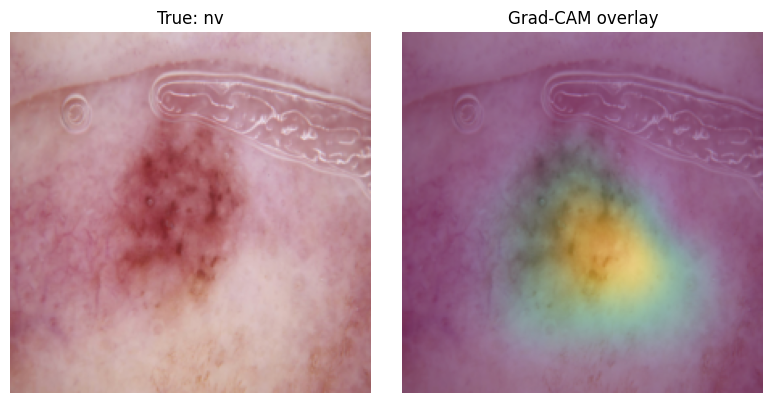

In [48]:
# --- Grad-CAM helper ---
# Qualitative only: use to audit selected high-uncertainty or misclassified cases.
# This cell is non-fatal. If the model architecture prevents Grad-CAM extraction, it records the issue and continues.

def find_last_conv_layer(model):
    last_name = None
    for layer in model.layers:
        if isinstance(layer, keras.Model):
            for sub in layer.layers:
                if isinstance(sub, layers.Conv2D):
                    last_name = sub.name
        elif isinstance(layer, layers.Conv2D):
            last_name = layer.name
    return last_name


def get_nested_layer(model, layer_name):
    for layer in model.layers:
        if layer.name == layer_name:
            return layer
        if isinstance(layer, keras.Model):
            try:
                return layer.get_layer(layer_name)
            except Exception:
                pass
    return None


def make_gradcam_heatmap(model, image_array, meta_array=None, class_index=None, conv_layer_name=None):
    if conv_layer_name is None:
        conv_layer_name = find_last_conv_layer(model)
    if conv_layer_name is None:
        raise ValueError("Could not find a Conv2D layer for Grad-CAM.")

    target_layer = get_nested_layer(model, conv_layer_name)
    if target_layer is None:
        raise ValueError(f"Layer {conv_layer_name} not found.")

    if model_uses_metadata(model):
        model_inputs = {"image": image_array, "metadata": meta_array}
    else:
        model_inputs = {"image": image_array}

    grad_model = keras.Model(model.inputs, [target_layer.output, model.output])
    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(model_inputs)
        if class_index is None:
            class_index = tf.argmax(predictions[0])
        class_channel = predictions[:, class_index]

    grads = tape.gradient(class_channel, conv_outputs)
    if grads is None:
        raise RuntimeError("Gradients are None for the selected convolutional layer.")

    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
    conv_outputs = conv_outputs[0]
    heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)
    heatmap = tf.maximum(heatmap, 0) / (tf.reduce_max(heatmap) + 1e-8)
    return heatmap.numpy(), conv_layer_name


def load_single_for_gradcam(row):
    img = load_image_numpy(row["image_path"], training=False)
    img_batch = np.expand_dims(img, axis=0).astype("float32")
    meta_vec = meta_pre.transform(pd.DataFrame([row]))
    return img_batch, meta_vec


RUN_GRADCAM_EXAMPLE = CONFIG["run_gradcam_example"]

if model_eval is not None and RUN_GRADCAM_EXAMPLE:
    try:
        pred_test = test_probs_temp.argmax(axis=1)
        uncertainty = 1 - test_probs_temp.max(axis=1)

        mis = np.where(pred_test != y_test)[0]
        if len(mis) > 0:
            candidate_idx = mis[np.argmax(uncertainty[mis])]
        else:
            candidate_idx = int(np.argmax(uncertainty))

        row = test_df.iloc[candidate_idx]
        img_batch, meta_vec = load_single_for_gradcam(row)
        heatmap, conv_name = make_gradcam_heatmap(model_eval, img_batch, meta_vec)
        print("Grad-CAM layer:", conv_name)
        print("Case:", row["image_id"], "true:", row["dx"], "pred:", CLASS_NAMES[pred_test[candidate_idx]], "uncertainty:", float(uncertainty[candidate_idx]))

        fig, ax = plt.subplots(1, 2, figsize=(8, 4))
        ax[0].imshow(img_batch[0].astype("uint8"))
        ax[0].set_title(f"True: {row['dx']}")
        ax[0].axis("off")

        heat = Image.fromarray(np.uint8(255 * heatmap)).resize((IMG_SIZE, IMG_SIZE))
        ax[1].imshow(img_batch[0].astype("uint8"))
        ax[1].imshow(heat, alpha=0.4)
        ax[1].set_title("Grad-CAM overlay")
        ax[1].axis("off")

        fig.tight_layout()
        fig.savefig(FIG_DIR / "gradcam_example.png", dpi=200)
        plt.show()

    except Exception as e:
        msg = f"Grad-CAM could not be generated for this architecture/session: {repr(e)}"
        print(msg)
        (RESULT_DIR / "gradcam_status.txt").write_text(msg)
else:
    print("Grad-CAM skipped. Set CONFIG['run_gradcam_example']=True for qualitative review.")


## 19. Optional TFLite export and deployment-cost reporting

Compression should only be done after choosing a final model. Report model size, inference latency, and any performance drop. Do not quantize every experimental model.

In [49]:
# --- Optional TFLite export: safer image-only wrapper ---

if model_eval is not None and CONFIG["run_tflite_export"]:
    try:
        if model_uses_metadata(model_eval):
            raise ValueError(
                "TFLite export wrapper currently supports image-only models. "
                "Skip export or implement a two-input signature for multimodal export."
            )

        export_dir = MODEL_DIR / "tflite_export"
        export_dir.mkdir(exist_ok=True, parents=True)

        image_input = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3), name="image")
        logits = model_eval({"image": image_input}, training=False)
        export_model = keras.Model(inputs=image_input, outputs=logits, name="image_only_tflite_export_wrapper")

        saved_model_dir = export_dir / "saved_model_image_only"
        if saved_model_dir.exists():
            shutil.rmtree(saved_model_dir)

        export_model.export(str(saved_model_dir))

        converter = tf.lite.TFLiteConverter.from_saved_model(str(saved_model_dir))
        converter.optimizations = [tf.lite.Optimize.DEFAULT]

        tflite_model = converter.convert()
        tflite_path = export_dir / "model_dynamic_range_quantized_image_only.tflite"
        tflite_path.write_bytes(tflite_model)

        deployment_row = {
            "tflite_path": str(tflite_path),
            "tflite_size_mb": round(tflite_path.stat().st_size / 1e6, 3),
            "selected_model_path": str(selected_model_path) if "selected_model_path" in globals() else "",
            "export_scope": "image_only_dynamic_range_quantization",
            "status": "success",
        }

        pd.DataFrame([deployment_row]).to_csv(
            RESULT_DIR / "deployment_export_summary.csv",
            index=False,
        )

        (RESULT_DIR / "tflite_export_status.txt").write_text(
            "success: image-only dynamic range quantized TFLite export completed\n"
            f"path: {tflite_path}\n"
            f"size_mb: {deployment_row['tflite_size_mb']}\n"
        )

        print("Saved TFLite model:", tflite_path)
        print("Size MB:", deployment_row["tflite_size_mb"])

    except Exception as e:
        msg = f"TFLite export failed non-fatally: {repr(e)}"
        print(msg)
        (RESULT_DIR / "tflite_export_status.txt").write_text(msg)
else:
    print("TFLite export skipped.")


Saved artifact at '/content/ham10000_trustworthy_ai/models/tflite_export/saved_model_image_only'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='image')
Output Type:
  TensorSpec(shape=(None, 7), dtype=tf.float32, name=None)
Captures:
  135049293758928: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135049154051728: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135049989396368: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135050001940112: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135050008511120: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135050001925712: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135049154036752: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135050005349392: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135049332638352: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135050005349584: TensorSpec(sha

In [50]:
# --- Methodological deployment verification ---
# This cell checks that the critical publication-safety fixes are active in the notebook run.

verification = {
    "dx_type_excluded_from_predictive_metadata": "dx_type" not in (META_CATEGORICAL_COLS + META_NUMERIC_COLS),
    "dx_type_available_for_subgroup_analysis": "dx_type" in SUBGROUP_VARIABLES,
    "primary_selection_image_only": CONFIG.get("main_model_selection_image_only", True),
    "multimodal_excluded_from_primary_selection": not CONFIG.get("include_multimodal_in_model_selection", False),
    "final_selected_seed_confirmation_enabled": CONFIG.get("run_final_selected_seed_confirmation", False),
    "tflite_export_image_only_wrapper": True,
}

if "selective_summary" in globals() and isinstance(selective_summary, pd.DataFrame) and "auto_sensitivity_for_class" in selective_summary.columns:
    verification["selective_sensitivity_bounded_by_1"] = selective_summary["auto_sensitivity_for_class"].dropna().le(1.0 + 1e-9).all()
else:
    verification["selective_sensitivity_bounded_by_1"] = "not_yet_run"

if "mc_summary" in globals() and isinstance(mc_summary, pd.DataFrame) and "auto_sensitivity_for_class" in mc_summary.columns:
    verification["mc_selective_sensitivity_bounded_by_1"] = mc_summary["auto_sensitivity_for_class"].dropna().le(1.0 + 1e-9).all()
else:
    verification["mc_selective_sensitivity_bounded_by_1"] = "not_yet_run"

verification_df = pd.DataFrame([
    {"check": k, "status": v} for k, v in verification.items()
])

display(verification_df)
verification_df.to_csv(RESULT_DIR / "methodological_deployment_verification.csv", index=False)

assert verification["dx_type_excluded_from_predictive_metadata"] is True
assert verification["dx_type_available_for_subgroup_analysis"] is True
assert verification["primary_selection_image_only"] is True
assert verification["multimodal_excluded_from_primary_selection"] is True
assert verification["final_selected_seed_confirmation_enabled"] is True

print("Methodological deployment verification passed.")


,check,status
0,dx_type_excluded_from_predictive_metadata,True
1,dx_type_available_for_subgroup_analysis,True
2,primary_selection_image_only,True
3,multimodal_excluded_from_primary_selection,True
4,final_selected_seed_confirmation_enabled,True
5,tflite_export_image_only_wrapper,True
6,selective_sensitivity_bounded_by_1,True
7,mc_selective_sensitivity_bounded_by_1,True


Methodological deployment verification passed.


## 20. Generate a reproducibility manifest and paper-ready result index

This final cell collects the key tables and figures created by the notebook. It is useful for writing the journal manuscript and for checking that every claim in the paper maps to a file output.

In [51]:
# --- Manifest of outputs ---

manifest = {
    "created_at": datetime.now().isoformat(),
    "work_dir": str(WORK_DIR),
    "config": CONFIG,
    "data_files": {
        "clean_metadata": str(clean_metadata_path),
        "split_all": str(SPLIT_DIR / "ham10000_lesion_level_split_all.csv"),
    },
    "result_files": sorted([str(p) for p in RESULT_DIR.glob("*")]),
    "figure_files": sorted([str(p) for p in FIG_DIR.glob("*")]),
    "model_files": sorted([str(p) for p in MODEL_DIR.rglob("*") if p.is_file()])[:200],
}
with open(WORK_DIR / "manifest.json", "w") as f:
    json.dump(manifest, f, indent=2)

print("Manifest saved:", WORK_DIR / "manifest.json")
print("Figures:")
for p in manifest["figure_files"]:
    print(" -", p)
print("Results:")
for p in manifest["result_files"]:
    print(" -", p)

Manifest saved: /content/ham10000_trustworthy_ai/manifest.json
Figures:
 - /content/ham10000_trustworthy_ai/figures/class_distribution.png
 - /content/ham10000_trustworthy_ai/figures/dx_type_distribution.png
 - /content/ham10000_trustworthy_ai/figures/gradcam_example.png
 - /content/ham10000_trustworthy_ai/figures/isic2018_external_confusion_matrix.png
 - /content/ham10000_trustworthy_ai/figures/isic2018_external_reliability.png
 - /content/ham10000_trustworthy_ai/figures/localization_distribution.png
 - /content/ham10000_trustworthy_ai/figures/referral_vs_melanoma_sensitivity.png
 - /content/ham10000_trustworthy_ai/figures/reliability_raw.png
 - /content/ham10000_trustworthy_ai/figures/reliability_temperature_scaled.png
 - /content/ham10000_trustworthy_ai/figures/risk_coverage_curves.png
 - /content/ham10000_trustworthy_ai/figures/sex_distribution.png
 - /content/ham10000_trustworthy_ai/figures/split_class_distribution.png
 - /content/ham10000_trustworthy_ai/figures/subgroup_metric_pr

## 21. Suggested manuscript claim-to-output map

| Manuscript claim | Notebook output |
|---|---|
| HAM10000 is long-tailed and unsuitable for accuracy-only reporting | `class_distribution.csv`, `class_distribution.png` |
| Splitting was lesion-level and leakage-controlled | `ham10000_lesion_level_split_all.csv`, split overlap assertions |
| The model was evaluated beyond accuracy | `test_metrics_raw.csv`, `test_metrics_temperature_scaled.csv`, `per_class_metrics_raw.csv` |
| Calibration was assessed and temperature scaling was fitted only on validation data | `reliability_bins_raw.csv`, `reliability_bins_temperature_scaled.csv`, reliability figures |
| Selective referral was evaluated independently of calibration | `selective_referral_summary.csv`, `risk_coverage_curves.png` |
| Internal subgroup performance/calibration gaps were assessed | `internal_subgroup_metrics_temperature_scaled.csv`, `internal_subgroup_gap_summary.csv` |
| Clinic-readiness stress tests were performed | `stress_test_metrics.csv`, stress-test figures |
| Compute cost and reproducibility were logged | `environment_log.json`, model `runtime.json`, `manifest.json` |

## References to justify the workflow in the manuscript

Use the research report's literature table to write the final reference list. The most directly used methods are:

- Tschandl et al. 2018 for HAM10000.
- Cassidy et al. 2022 and Abhishek et al. 2025 for data quality, duplicate images, and split leakage.
- Guo et al. 2017 for temperature scaling and neural-network calibration.
- Gal & Ghahramani 2016 and Lakshminarayanan et al. 2017 for MC Dropout and deep ensembles.
- El-Yaniv & Wiener 2010 and Geifman & El-Yaniv 2019 for selective classification / reject option.
- Mobiny et al. 2019 for risk-aware skin-lesion referral using uncertainty.
- Groh et al. 2021 and Daneshjou et al. 2022 for skin-tone and external fairness concerns.
- Young et al. 2021 for clinic-readiness stress testing.
- Thomas et al. 2023 and Krakowski et al. 2024 for real-world deployment and human-AI workflow framing.